In [2]:
############################################
import timeit
import sys
import os
import glob
import warnings
import matplotlib.pyplot as plt
from astropy.io import fits
from pyqsofit.PyQSOFit import QSOFit
import numpy as np
import matplotlib
from matplotlib.gridspec import GridSpec

from astropy.io import ascii
from astropy.table import Table
from astropy import table, time
from tqdm import tnrange, tqdm_notebook
from tqdm.notebook import trange
from astropy.cosmology import WMAP9 as cosmo
import astropy.units as u
from scipy.optimize import curve_fit

import random
from pkg.colorList import RGB2Hex

import pandas as pd
import pickle
##########################################

%matplotlib inline
warnings.filterwarnings("ignore")
##########################################

# PyQSOfit 


## emline template

In [3]:
newdata = np.rec.array([(6564.61,'Ha',6400.,6800.,'Ha_br',3,5e-3,0.004,0.05,0.015,0,0,0,0.05),\
                        (6564.61,'Ha',6400.,6800.,'Ha_na',1,1e-3,5e-4,0.0017,0.01,1,1,0,0.002),\
                        (6549.85,'Ha',6400.,6800.,'NII6549',1,1e-3,2.3e-4,0.0017,5e-3,1,1,1,0.001),\
                        (6585.28,'Ha',6400.,6800.,'NII6585',1,1e-3,2.3e-4,0.0017,5e-3,1,1,1,0.003),\
                        (6718.29,'Ha',6400.,6800.,'SII6718',1,1e-3,2.3e-4,0.0017,5e-3,1,1,2,0.001),\
                        (6732.67,'Ha',6400.,6800.,'SII6732',1,1e-3,2.3e-4,0.0017,5e-3,1,1,2,0.001),\
                        
                        (4862.68,'Hb',4640.,5100.,'Hb_br',1,5e-3,0.004,0.05,0.01,0,0,0,0.01),\
                        (4862.68,'Hb',4640.,5100.,'Hb_na',1,1e-3,2.3e-4,0.0017,0.01,1,1,0,0.002),\
                        (4960.30,'Hb',4640.,5100.,'OIII4959c',1,1e-3,2.3e-4,0.0017,0.01,1,1,0,0.002),\
                        (5008.24,'Hb',4640.,5100.,'OIII5007c',1,1e-3,2.3e-4,0.0017,0.01,1,1,0,0.004),\
                        (4960.30,'Hb',4640.,5100.,'OIII4959w',1,3e-3,2.3e-4,0.004,0.01,2,2,0,0.001),\
                        (5008.24,'Hb',4640.,5100.,'OIII5007w',1,3e-3,2.3e-4,0.004,0.01,2,2,0,0.002),\
#                         (4687.02,'Hb',4640.,5100.,'HeII4687_br',1,5e-3,0.004,0.05,0.005,0,0,0,0.001),\
                        (4687.02,'Hb',4640.,5100.,'HeII4687_na',1,1e-3,2.3e-4,0.0017,0.005,1,1,0,0.001),\
                        
#                         (3934.78,'CaII',3900.,3960.,'CaII3934',2,1e-3,3.333e-4,0.0017,0.01,99,0,0,-0.001),\
                        
#                         (3728.48,'OII',3650.,3800.,'OII3728',1,1e-3,3.333e-4,0.0017,0.01,1,1,0,0.001),\
                        
                        #(3426.84,'NeV',3380.,3480.,'NeV3426',1,1e-3,3.333e-4,0.0017,0.01,0,0,0,0.001),\
                        #(3426.84,'NeV',3380.,3480.,'NeV3426_br',1,5e-3,0.0025,0.02,0.01,0,0,0,0.001),\
                        
                        (2798.75,'MgII',2700.,2900.,'MgII_br',1,5e-3,0.004,0.05,0.0017,0,0,0,0.05),\
                        (2798.75,'MgII',2700.,2900.,'MgII_na',2,1e-3,5e-4,0.0017,0.01,1,1,0,0.002),\
                        
                        
                        (1908.73,'CIII',1700.,1970.,'CIII_br',2,5e-3,0.004,0.05,0.015,99,0,0,0.01),\
#                         (1908.73,'CIII',1700.,1970.,'CIII_na',1,1e-3,5e-4,0.0017,0.01,1,1,0,0.002),\
                        #(1892.03,'CIII',1700.,1970.,'SiIII1892',1,2e-3,0.001,0.015,0.003,1,1,0,0.005),\
                        #(1857.40,'CIII',1700.,1970.,'AlIII1857',1,2e-3,0.001,0.015,0.003,1,1,0,0.005),\
                        #(1816.98,'CIII',1700.,1970.,'SiII1816',1,2e-3,0.001,0.015,0.01,1,1,0,0.0002),\
                        #(1786.7,'CIII',1700.,1970.,'FeII1787',1,2e-3,0.001,0.015,0.01,1,1,0,0.0002),\
                        #(1750.26,'CIII',1700.,1970.,'NIII1750',1,2e-3,0.001,0.015,0.01,1,1,0,0.001),\
                        #(1718.55,'CIII',1700.,1900.,'NIV1718',1,2e-3,0.001,0.015,0.01,1,1,0,0.001),\
                        
                        (1549.06,'CIV',1500.,1700.,'CIV_br',1,5e-3,0.004,0.05,0.015,0,0,0,0.05),\
                        (1549.06,'CIV',1500.,1700.,'CIV_na',1,1e-3,5e-4,0.0017,0.01,1,1,0,0.002),\
                        #(1640.42,'CIV',1500.,1700.,'HeII1640',1,1e-3,5e-4,0.0017,0.008,1,1,0,0.002),\
                        #(1663.48,'CIV',1500.,1700.,'OIII1663',1,1e-3,5e-4,0.0017,0.008,1,1,0,0.002),\
                        #(1640.42,'CIV',1500.,1700.,'HeII1640_br',1,5e-3,0.0025,0.02,0.008,1,1,0,0.002),\
                        #(1663.48,'CIV',1500.,1700.,'OIII1663_br',1,5e-3,0.0025,0.02,0.008,1,1,0,0.002),\
                        
                        (1402.06,'SiIV',1290.,1450.,'SiIV_OIV1',1,5e-3,0.002,0.05,0.015,1,1,0,0.05),\
                        (1396.76,'SiIV',1290.,1450.,'SiIV_OIV2',1,5e-3,0.002,0.05,0.015,1,1,0,0.05),\
                        (1335.30,'SiIV',1290.,1450.,'CII1335',1,2e-3,0.001,0.015,0.01,1,1,0,0.001),\
                        (1304.35,'SiIV',1290.,1450.,'OI1304',1,2e-3,0.001,0.015,0.01,1,1,0,0.001),\
                        
                        (1215.67,'Lya',1150.,1290.,'Lya_br',1,5e-3,0.004,0.05,0.02,0,0,0,0.05),\
                        (1215.67,'Lya',1150.,1290.,'Lya_na',1,1e-3,5e-4,0.0017,0.01,0,0,0,0.002)\
                        ],\
                     formats='float32,a20,float32,float32,a20,float32,float32,float32,float32,\
                     float32,float32,float32,float32,float32',\
                     names='lambda,compname,minwav,maxwav,linename,ngauss,inisig,minsig,maxsig,voff,vindex,windex,findex,fvalue')
#------header-----------------
hdr = fits.Header()
hdr['lambda'] = 'Vacuum Wavelength in Ang'
hdr['minwav'] = 'Lower complex fitting wavelength range'
hdr['maxwav'] = 'Upper complex fitting wavelength range'
hdr['ngauss'] = 'Number of Gaussians for the line'
hdr['inisig'] = 'Initial guess of linesigma [in lnlambda]'
hdr['minsig'] = 'Lower range of line sigma [lnlambda]'  
hdr['maxsig'] = 'Upper range of line sigma [lnlambda]'
hdr['voff  '] = 'Limits on velocity offset from the central wavelength [lnlambda]'
hdr['vindex'] = 'Entries w/ same NONZERO vindex constrained to have same velocity'
hdr['windex'] = 'Entries w/ same NONZERO windex constrained to have same width'
hdr['findex'] = 'Entries w/ same NONZERO findex have constrained flux ratios'
hdr['fvalue'] = 'Relative scale factor for entries w/ same findex'
#------save line info-----------
hdu = fits.BinTableHDU(data=newdata,header=hdr,name='data')
hdu.writeto('pkg/PyQSOFit/qsopar.fits',overwrite=True)

## example

In [4]:
path0 = "pkg/PyQSOFit/"                      # PyQSOFit & qsopar.fits path
# path1 = 'data/fit_results/'                  # the path of the qsopar.fits
path2 = 'data/fit_results/sdss_dr9/'           # path of fitting results
path3 = 'data/fit_results/sdss_dr9/'               # path of figure
path4 = 'pkg/PyQSOFit/sfddata/'              # path of dusp reddening map

# sdss_data_path = "data/SDSS/"
# target_name    = "SDSS_J141119.44+413802.3"

#Requried
# an important note that all the data input must be finite, especically for the error !!!
data=fits.open("data/SDSS/SDSS_J161700.81+124332.2.fits")
lam=10**data[1].data['loglam']        # OBS wavelength [A]
flux=data[1].data['flux']             # OBS flux [erg/s/cm^2/A]
err=1./np.sqrt(data[1].data['ivar'])  # 1 sigma error
z=data[2].data['z'][0]                # Redshift

#Optinal
ra=data[0].header['plug_ra']          # RA 
dec=data[0].header['plug_dec']        # DEC
plateid = data[0].header['plateid']   # SDSS plate ID
mjd = 55653           # SDSS MJD
fiberid = data[0].header['fiberid']   # SDSS fiber ID

Fitting finished in : 585.0s


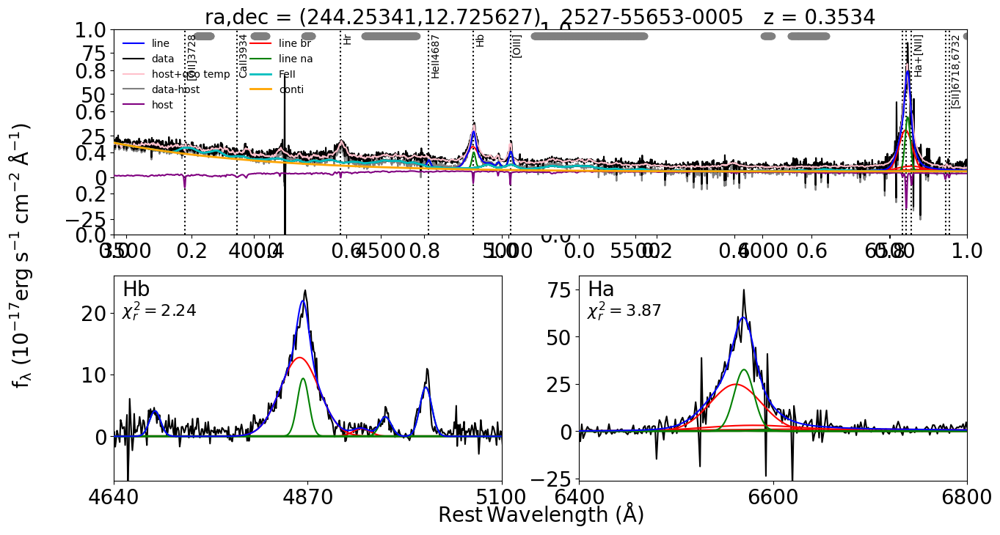

In [5]:
# get data prepared 

q = QSOFit(lam, flux, err, z, ra = ra, dec = dec, plateid = plateid, mjd = mjd, fiberid = fiberid, path = path0)

start = timeit.default_timer()
# do the fitting
q.Fit(name = None,nsmooth = 1, and_or_mask = False, deredden = True, reject_badpix = False, wave_range = None,\
      wave_mask =None, decomposition_host = True, Mi = None, npca_gal = 5, npca_qso = 20, \
      Fe_uv_op = True, Fe_flux_range=np.array([4435,4685]), poly = True, BC = False, rej_abs = False, \
      initial_guess = None, MC = True, n_trails = 100, linefit = True, tie_lambda = True, tie_width = True, \
      tie_flux_1 = True, tie_flux_2 = True, save_result = True, plot_fig = True,save_fig = True, \
      plot_line_name = True, plot_legend = True, dustmap_path = path4, save_fig_path = path3, \
      save_fits_path = path2,save_fits_name = 'SDSS_J1617_fit_results')

end = timeit.default_timer()

print('Fitting finished in : '+str(np.round(end-start))+'s')
    
# grey shade on the top is the continuum windiows used to fit.

In [ ]:
save_path = "data/fit_results/sdss_dr9/"
target_name = "SDSS_J1452"
ins_name = ""
redshift = z
n_iter=1000
data_test = betterOutput(q, save_path, target_name, ins_name, redshift, save_data = True, data_output=True, n_iter=n_iter)

# signal obj fitting



In [123]:
path0 = "pkg/PyQSOFit/"                      # PyQSOFit & qsopar.fits path
path2 = 'data/fit_results/sdss_dr9/'           # path of fitting results
path3 = 'data/fit_results/sdss_dr9/'               # path of figure
path4 = 'pkg/PyQSOFit/sfddata/'              # path of dusp reddening map

## SDSS SPEC

In [431]:
#Requried
# an important note that all the data input must be finite, especically for the error !!!
data=fits.open("data/SDSS/SDSS_J142746.39+293038.2.fits")
lam=10**data[1].data['loglam']        # OBS wavelength [A]
flux=data[1].data['flux']             # OBS flux [erg/s/cm^2/A]
err=1./np.sqrt(data[1].data['ivar'])  # 1 sigma error
z=data[2].data['z'][0]                # Redshift

#Optinal
ra=data[0].header['plug_ra']          # RA 
dec=data[0].header['plug_dec']        # DEC
plateid = data[0].header['plateid']   # SDSS plate ID
mjd = 52758         # SDSS MJD
fiberid = data[0].header['fiberid']   # SDSS fiber ID

Get negtive host galaxy flux larger than 100 pixels, decomposition is not applied!
Fitting finished in : 6.0s


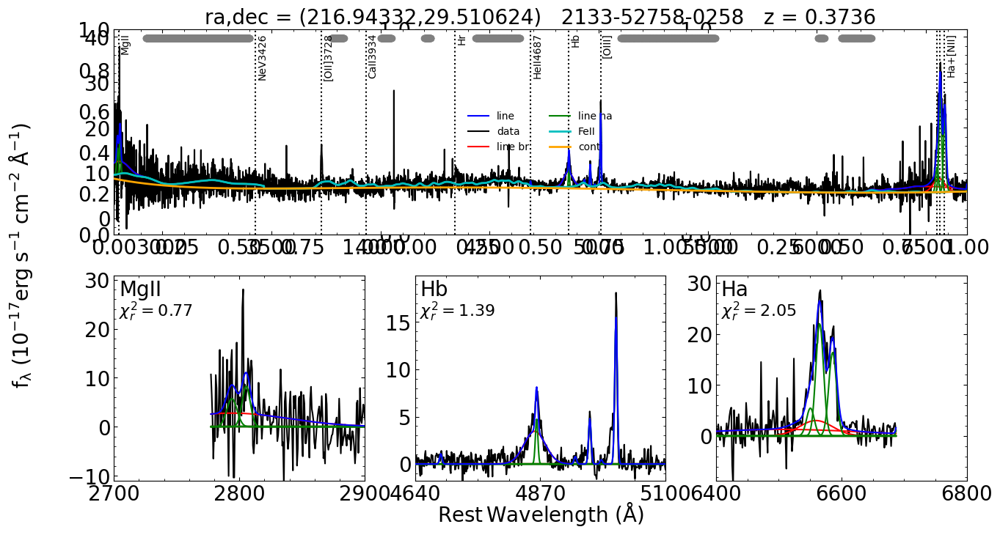

In [432]:
# get data prepared 
q_sdss = QSOFit(lam, flux, err, z, ra = ra, dec = dec, plateid = plateid, mjd = mjd, fiberid = fiberid, path = path0)

start = timeit.default_timer()
# do the fitting
q_sdss.Fit(name = None,nsmooth = 1, and_or_mask = False, deredden = True, reject_badpix = False, wave_range = None,\
      wave_mask =None, decomposition_host = True, Mi = None, npca_gal = 5, npca_qso = 20, \
      Fe_uv_op = True, Fe_flux_range=np.array([4435,4685]), poly = True, BC = False, rej_abs = False, \
      initial_guess = None, MC = False, n_trails = 200, linefit = True, tie_lambda = True, tie_width = True, \
      tie_flux_1 = True, tie_flux_2 = True, save_result = False, plot_fig = True,save_fig = True, \
      plot_line_name = True, plot_legend = True, dustmap_path = path4, save_fig_path = path3, \
      save_fits_path = path2,save_fits_name = 'J1427_fit_results')

end = timeit.default_timer()

print('Fitting finished in : '+str(np.round(end-start))+'s')
    
# grey shade on the top is the continuum windiows used to fit.

In [454]:
q_sdss.line_result_name[57:60], q_sdss.line_result[57:60]

(array(['Ha_na_1_scale', 'Ha_na_1_centerwave', 'Ha_na_1_sigma'],
       dtype='<U32'),
 array(['0.05164983408341583', '8.789565979193931',
        '0.0009348305708814147'], dtype='<U32'))

In [447]:
fwhm,sigma,ew,peak,area = q_sdss.line_prop(q_sdss.linelist[1][0],q_sdss.line_result[57:60],'narrow') 
area

338.1347478867627

In [171]:
# save_path = "data/fit_results/sdss_dr9/"
# target_name = "SDSS_J2127_MgII"
# ins_name = ""
# redshift = z

# data_test = betterOutput(q, save_path, target_name, ins_name, redshift, save_data = True, data_output=True, n_iter=500)

0.3736243844032288

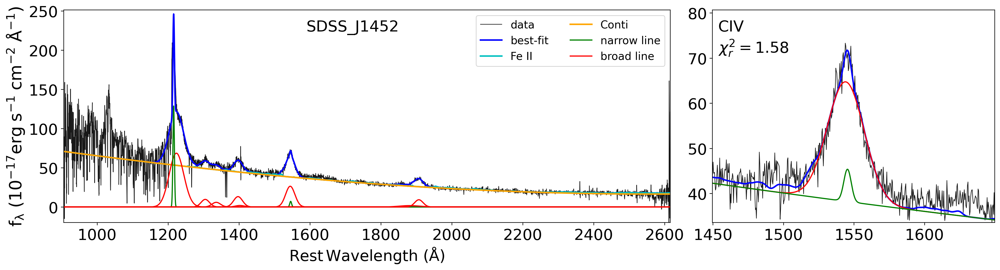

In [194]:
fig = plt.figure(figsize=(24,5),dpi = 200)
gs = fig.add_gridspec(nrows=1, ncols=3, left=0.05, right=0.75,
                      hspace=0.1, wspace=0.15)

ax = fig.add_subplot(gs[0, :-1])
ax.set_xlim(q_sdss.wave.min(), q_sdss.wave.max())
ax.set_ylim(-20, q_sdss.flux.max()*1.1)
ax.set_xlabel(r'$\rm Rest \, Wavelength$ ($\rm \AA$)',fontsize = 20)
ax.set_ylabel(r'$\rm f_{\lambda}$ ($\rm 10^{-17} erg\;s^{-1}\;cm^{-2}\;\AA^{-1}$)',fontsize = 22)

ax.plot(q_sdss.wave, q_sdss.flux, 'k', lw=0.8, alpha=0.9, label='data')
ax.plot(q_sdss.wave,q_sdss.Manygauss(np.log(q_sdss.wave),q_sdss.gauss_result)+q_sdss.f_conti_model,
        'b',label='best-fit',lw=2)
ax.plot(q_sdss.wave,q_sdss.f_conti_model,'c',lw=2, label='Fe II')
ax.plot(q_sdss.wave,q_sdss.PL_poly_BC,'orange',lw=2, label='Conti')

ax.plot(q_sdss.wave,np.full_like(q_sdss.wave, 0.0), 'g', label='narrow line')
ax.plot(q_sdss.wave,np.full_like(q_sdss.wave, 0.0), 'r', label='broad line')

ax.text(0.4,0.90,tar_name[5],transform=ax.transAxes,fontdict={'size': '20', 'color': 'black'})

for p in range(int(len(q_sdss.gauss_result)/3)):
    if q_sdss.CalFWHM(q_sdss.gauss_result[3*p+2] ) < 1210.:  # < 1200 km/s narrow
        color = 'g'
        label = 'narrow'
    else:
        color = 'r'
        label = 'broad'
    ax.plot(q_sdss.wave,q_sdss.Onegauss(np.log(q_sdss.wave),q_sdss.gauss_result[p*3:(p+1)*3]),
            color=color)

ax.legend(ncols=2, fontsize=14)

ax2 = fig.add_subplot(gs[0, -1])

para_name = q_sdss.gauss_result_name
all_para  = q_sdss.gauss_result
comp_result = q_sdss.comp_result

line_name = 'CIV'
lc_reswave = 1549.63
line_para_name = [name for name in para_name if line_name in name and 'whole' not in name]
line_para = [all_para[i] for i in range(len(para_name)) if para_name[i] in line_para_name]
ilines = np.where(comp_result == line_name)[0][0]
chi2   = np.round(float(comp_result[ilines+3]), 2)
em_window = (q_sdss.wave > lc_reswave-100)&(q_sdss.wave < lc_reswave+100)
em_flux = q_sdss.flux[em_window]


ax2.set_xlim(lc_reswave-100, lc_reswave+100)
ax2.set_ylim(em_flux.min(), em_flux.max()*1.1)
ax2.plot(q_sdss.wave, q_sdss.flux, 'k', lw=0.8, alpha=0.9, label='data')
ax2.plot(q_sdss.wave,q_sdss.Manygauss(np.log(q_sdss.wave),q_sdss.gauss_result)+q_sdss.f_conti_model,
        'b',label='best-fit',lw=2)
ax2.text(0.02,0.90,line_name,transform=ax2.transAxes,fontdict={'size': '20', 'color': 'black'})
ax2.text(0.02,0.80,r'$\chi ^2_r=$'+str(chi2),transform=ax2.transAxes,fontdict={'size': '20', 'color': 'black'})

for p in range(int(len(line_para)/3)):
    if q_sdss.CalFWHM(line_para[3*p+2]) < 1210.:  # < 1200 km/s narrow
        color = 'g'
        label = 'narrow'
    else:
        color = 'r'
        label = 'broad'
    ax2.plot(q_sdss.wave,q_sdss.PL_poly_BC+q_sdss.Onegauss(np.log(q_sdss.wave),line_para[p*3:(p+1)*3]),
             color=color)
    
    

## GTC SPEC

In [452]:
# load file data
gtc_C_data = fits.open("data/GTC-OSIRIS/Sci_spec/combined_grism/SDSS_J1427GTC_OSIRIS.fits")
gtc_fc_flux = ascii.read("data/GTC-OSIRIS/Sci_spec/Flux_cal_spec/J1427_FluxCal.dat")
sdss_data  = fits.open("data/SDSS/SDSS_J142746.39+293038.2.fits")

wave_c = gtc_C_data[1].data["wave"]
flux_c = np.array(gtc_fc_flux['fluxCal'])
var_c = gtc_C_data[1].data["var"]
z      = gtc_C_data[0].header["z"]

lam    = wave_c  # OBS wavelength [A]
flux   = flux_c  # OBS flux [erg/s/cm^2/A]
nanid  = np.where(np.isnan(flux))
flux[nanid] = 0
err    = (np.sqrt(var_c))  # 1 sigma error
nanid  = np.where(np.isnan(err))
err[nanid] = 0

# Optinal
data    = sdss_data
ra      = data[0].header['plug_ra']  # RA
dec     = data[0].header['plug_dec']  # DEC
plateid = data[0].header['plateid']  # SDSS plate ID
mjd     = gtc_C_data[0].header['mjd']  # SDSS MJD
fiberid = data[0].header['fiberid']  # SDSS fiber ID

Get negtive host galaxy flux larger than 100 pixels, decomposition is not applied!
Fitting finished in : 2.0s


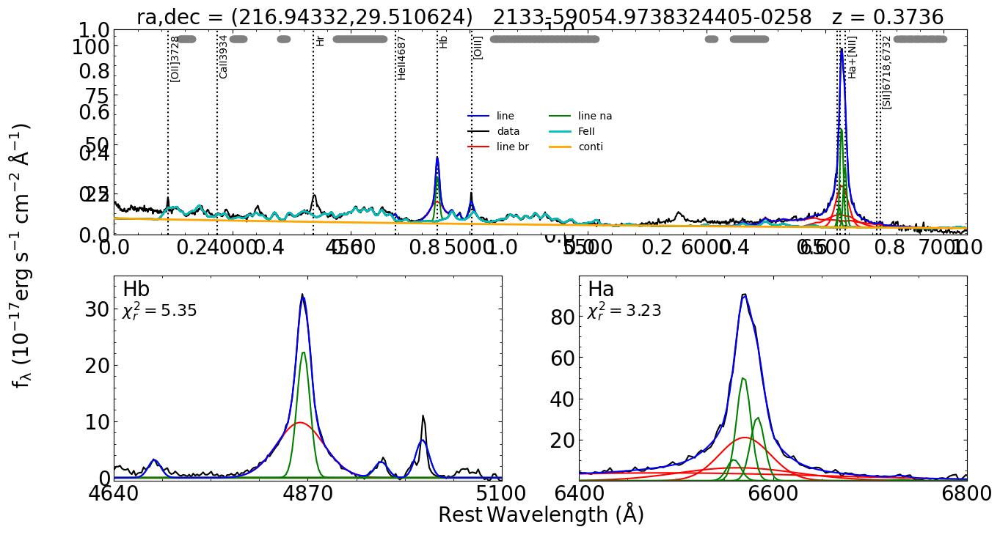

In [453]:
# get data prepared
q_gtc = QSOFit(lam,flux,err,z,path=path0,
           ra=ra,dec=dec,plateid=plateid,mjd=mjd,fiberid=fiberid)

start = timeit.default_timer()
# do the fitting
q_gtc.Fit(name=None, nsmooth=1, and_or_mask=False, deredden=True, reject_badpix=False, wave_range=np.array([3500,7100]),
      wave_mask=None, decomposition_host=True, Mi=None, npca_gal=5, npca_qso=20,
      Fe_uv_op=True, Fe_flux_range=np.array([4435,4685]), poly=False, BC=False, rej_abs=False,
      initial_guess=None, MC=False, n_trails=5, linefit=True, tie_lambda=False, tie_width=True,
      tie_flux_1=True, tie_flux_2=True, save_result=False, plot_fig=True, save_fig=False,
      plot_line_name=True, plot_legend=True, dustmap_path=path4, save_fig_path=path3,
      save_fits_path=path2, save_fits_name='SDSS_J1427_fit_results_gtc_new')

end = timeit.default_timer()

print('Fitting finished in : '+str(np.round(end-start))+'s')

In [465]:
q_gtc.line_result_name[42:45], q_gtc.line_result[42:45]

(array(['Ha_na_1_scale', 'Ha_na_1_centerwave', 'Ha_na_1_sigma'],
       dtype='<U32'),
 array(['0.14026370435268415', '8.790241512090315',
        '0.0011025233308024668'], dtype='<U32'))

In [466]:
fwhm,sigma,ew,peak,area = q_gtc.line_prop(q_gtc.linelist[1][0],q_gtc.line_result[42:45],'narrow') 
area

918.9194333880549

## J1427 results

(-1.0, 20.0)

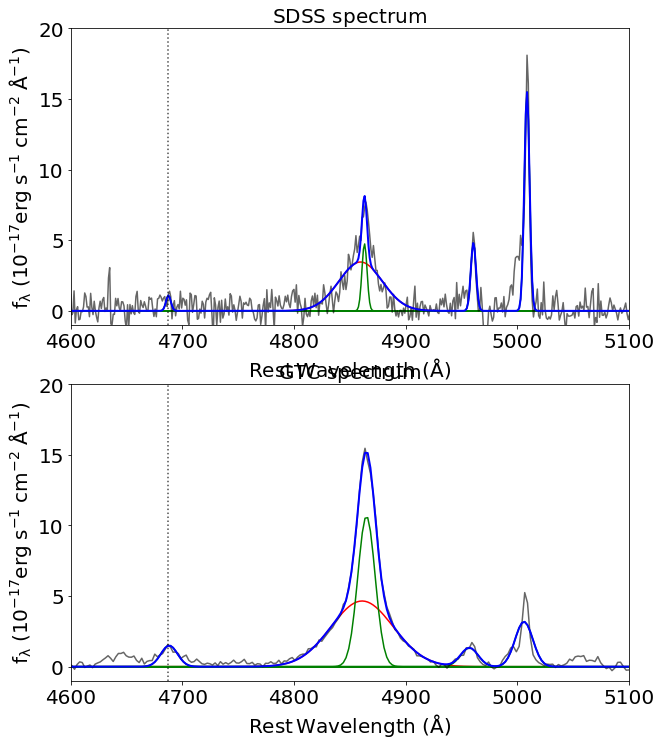

In [111]:
fig=plt.figure(figsize=(10,12))

ax1 = fig.add_subplot(211)
plt.xlabel(r'$\rm Rest \, Wavelength$ ($\rm \AA$)',fontsize = 20)
plt.ylabel(r'$\rm f_{\lambda}$ ($\rm 10^{-17} erg\;s^{-1}\;cm^{-2}\;\AA^{-1}$)',fontsize = 20)
plt.title(r'$\rm SDSS\ spectrum$',fontsize = 20)

for p in range(int(len(q_sdss.gauss_result)/3)):
    if q_sdss.CalFWHM(q_sdss.gauss_result[3*p+2] ) < 1200.:  # < 1200 km/s narrow
        color = 'g'
    else:
        color = 'r'
    plt.plot(q_sdss.wave,q_sdss.Onegauss(np.log(q_sdss.wave),q_sdss.gauss_result[p*3:(p+1)*3]),color=color)

plt.plot(q_sdss.wave,q_sdss.line_flux,'k',alpha = 0.6)
plt.plot(q_sdss.wave,q_sdss.Manygauss(np.log(q_sdss.wave),q_sdss.gauss_result),'b',lw=2)
plt.axvline(x = 4687.02, color = 'k',linestyle=":", alpha=0.7)

plt.xlim(4600,5100)
plt.ylim(-1,20)


ax2 = fig.add_subplot(212)
plt.xlabel(r'$\rm Rest \, Wavelength$ ($\rm \AA$)',fontsize = 20)
plt.ylabel(r'$\rm f_{\lambda}$ ($\rm 10^{-17} erg\;s^{-1}\;cm^{-2}\;\AA^{-1}$)',fontsize = 20)
plt.title(r'$\rm GTC\ spectrum$',fontsize = 20)

for p in range(int(len(q_gtc.gauss_result)/3)):
    if q_gtc.CalFWHM(q_gtc.gauss_result[3*p+2] ) < 1200.:  # < 1200 km/s narrow
        color = 'g'
    else:
        color = 'r'
    plt.plot(q_gtc.wave,q_gtc.Onegauss(np.log(q_gtc.wave),q_gtc.gauss_result[p*3:(p+1)*3]),color=color)

plt.plot(q_gtc.wave,q_gtc.line_flux,'k',alpha = 0.6)
plt.plot(q_gtc.wave,q_gtc.Manygauss(np.log(q_gtc.wave),q_gtc.gauss_result),'b',lw=2)
plt.axvline(x = 4687.02, color = 'k',linestyle=":", alpha=0.7)

plt.xlim(4600,5100)
plt.ylim(-1,20)

In [112]:
Fe_flux_result,Fe_flux_type,Fe_flux_name = q_sdss.Get_Fe_flux(np.array([4400,4900]))
print("SDSS")
print('Fe flux within a specific range: \n'+Fe_flux_name[0]+': '+str(Fe_flux_result[0]))

SDSS
Fe flux within a specific range: 
Fe_flux_4400_4900: 403.5137954818963


In [113]:
Fe_flux_result,Fe_flux_type,Fe_flux_name = q_gtc.Get_Fe_flux(np.array([4400,4900]))
print("GTC")
print('Fe flux within a specific range: \n'+Fe_flux_name[0]+': '+str(Fe_flux_result[0]))

GTC
Fe flux within a specific range: 
Fe_flux_4400_4900: 793.4854873328636


In [114]:
product_sdss = re_product(q_sdss, path = 'data/fit_results/', tar_name='SDSSJ1427', instr = 'SDSS')
product_gtc = re_product(q_gtc, path = 'data/fit_results/', tar_name='SDSSJ1427', instr = 'GTC')

In [124]:
print("SDSS   Type 1.2")
# Seyfert_type(168.1313443514904+27.133876952029542, 91.11495298062911)
product_sdss

SDSS   Type 1.2


line name,line peak,FWHM,sigma,ew,flux
str13,float64,float64,float64,float64,float64
MgII_na_1,0.0,0.0,0.0,0.0,0.0
Hb_br_1,4859.005048104426,2822.897858749152,1182.320072054227,25.352248835478342,168.1313443514904
Hb_na_1,4862.515071846253,340.6295254920615,138.67913626880141,4.092812109825631,27.133876952029542
OIII4959c_1,4960.126949053147,340.6291950488171,138.67900185129827,4.275935959419672,28.043594253464935
OIII5007c_1,5008.067409806067,340.62934014389856,138.6790610828698,13.973111077933552,91.11495298062911
HeII4687_na_1,4686.856490036716,340.62919555840404,138.67900211432715,0.8863622220872065,5.969238709782372
Ha_br_1,6505.282822621572,13846.611686877384,5804.140208848402,71.19512776313965,411.90302497382083
Ha_br_2,6558.620289123296,2822.4552374328628,1182.1346880642438,34.08756281363578,197.83254400540264
Ha_na_1,6564.581550836483,664.0672049649546,276.3973477638352,58.221056592272625,338.1343854696673


In [123]:
print("GTC    Type 1.0")
product_gtc
# Seyfert_type(324.28171796069347+206.0058075835376, 63.36464337023935)

GTC    Type 1.0


line name,line peak,FWHM,sigma,ew,flux
str13,float64,float64,float64,float64,float64
Hb_br_1,4860.983901521168,4048.1514610080994,1696.071968294927,69.45100391109642,324.28171796069347
Hb_na_1,4864.917772939078,1121.6995060400948,469.8771225125546,44.14450268650489,206.0058075835376
OIII4959c_1,4957.122836985502,1120.465406243796,469.36016123114445,5.679141616634552,26.145474911028877
OIII5007c_1,5006.025979982609,1120.6878971076271,469.45336203402576,13.861563755261429,63.36464337023935
HeII4687_na_1,4688.149599311145,1121.453756652918,469.77417867414886,5.819510291267754,27.89318152009389
Ha_br_1,6569.364616789044,3259.187392392635,1365.1742042295032,204.59495386081898,768.4988290564875
Ha_br_2,6538.356393720076,12672.134218071758,5311.367065570726,250.38587729919277,943.522921535879
Ha_na_1,6569.839353942569,805.4421311491998,337.3382133902894,126.42351416769516,474.89571196936885
NII6549_1,6558.952113247144,805.9194341939202,337.5381190725312,24.94248687077546,93.80594016634006


In [170]:
27.89318152009389/(324.28171796069347+206.0058075835376)

0.052600108764518407

In [ ]:
cosmo.luminosity_distance(0.3736). to(u.cm)  

In [588]:
## GTC
dist = 6.268082 * 10 ** 27   ## cm 
F_hb_br = 305.54074007611393 * 10**(-17)
FWHM_hb_br = 4246.65550808513
# log10(Mbh) 7.913

## SDSS 
F_hb_br_sdss = 168.28216836664635 * 10**(-17)
FWHM_hb_br_sdss = 2822.896983253054
# log10(Mbh) 7.413

##  M_bh
L_hb_br_sdss = 4 * np.pi * dist**2 * F_hb_br_sdss
L_hb_br_gtc = 4 * np.pi * dist**2 * F_hb_br
# Mbh_J1427 = 3.6 * 10**6 * ((L_hb_br / 10**42)**(0.56)) * ((FWHM_hb_br_sdss / (10**3)) **2)

## L_bol
L_bol_sdss = 10 * (L_hb_br_sdss / (1.425 * 10**42))**(1/1.133) * 10 ** 44
L_bol_gtc = 10 * (L_hb_br_gtc / (1.425 * 10**42))**(1/1.133) * 10 ** 44
L_bol_gtc,L_bol_sdss

(1.0515503344177651e+45, 6.211636526508692e+44)

In [589]:
SDSS_Lhb, SDSS_Lhb_err, SDSS_Hb_FWHM, SDSS_Hb_FWHM_err

(array([3.13118391e+42, 8.30095185e+41, 9.30183039e+42, 1.35157929e+42]),
 array([1.69494605e+41, 3.51322946e+40, 6.02325003e+41, 3.37883783e+40]),
 array([3463.47997252, 2822.8977567 , 3839.25274498, 2825.33909061]),
 array([234.24224474,   0.46322076, 455.89435606,   8.08371049]))

In [591]:
np.log10(3.6 * 10**6 * ((8.30095185e+41 / 10**42)**(0.56)) * ((2822.8977567 / (10**3)) **2))

7.412404419017738

In [595]:
virBhMass(4861*8.30095185e+41, 3.51322946e+40,2822.8977567 ,0.46322076,method='Hb')

(8.614317055104188, 0.0001496656382706869)

# Funcutions

In [134]:
def get_peak_type(line_name):
    line_center = []
    line_type   = []
    for name in line_name:
        if 'Hb_br' in name:
            line_center.append(4862.68)
            line_type.append('broad')
        if 'Hb_na' in name:
            line_center.append(4862.68)
            line_type.append('narrow')
        if 'Ha_br' in name:
            line_center.append(6564.61)
            line_type.append('broad')
        if 'Ha_na' in name:
            line_center.append(6564.61)
            line_type.append('narrow')   
        if 'OIII4959c' in name:
            line_center.append(4960.30)
            line_type.append('narrow')
        if 'OIII5007c' in name:
            line_center.append(5008.24)
            line_type.append('narrow')
        if 'OIII4959w' in name:
            line_center.append(4960.30)
            line_type.append('broad')
        if 'OIII5007w' in name:
            line_center.append(5008.24)
            line_type.append('broad')
        if "HeII4687_na" in name:
            line_center.append(4687.02)
            line_type.append('narrow')
        if "HeII4687_br" in name:
            line_center.append(4687.02)
            line_type.append('broad')
        if 'NII6549' in name:
            line_center.append(6549.85)
            line_type.append('narrow')
        if 'NII6585' in name:
            line_center.append(6585.28)
            line_type.append('narrow')
        if 'SII6718' in name:
            line_center.append(6718.29)
            line_type.append('narrow')
        if 'SII6732' in name:
            line_center.append(6732.67)
            line_type.append('narrow')
        if 'MgII_na' in name:
            line_center.append(2798.75)
            line_type.append('narrow')
        if 'MgII_br' in name:
            line_center.append(2798.75)
            line_type.append('broad')
        if 'CIII_na' in name:
            line_center.append(1908.73)
            line_type.append('narrow')
        if 'CIII_br' in name:
            line_center.append(1908.73)
            line_type.append('broad')
        if 'CIV_na' in name:
            line_center.append(1549.06)
            line_type.append('narrow')
        if 'CIV_br' in name:
            line_center.append(1549.06)
            line_type.append('broad')
        if 'SiIV_OIV1' in name:
            line_center.append(1402.06)
            line_type.append('broad')
        if 'SiIV_OIV2' in name:
            line_center.append(1396.76)
            line_type.append('broad')
        if 'CII1335' in name:
            line_center.append(1335.30)
            line_type.append('broad')
        if 'OI1304' in name:
            line_center.append(1304.35)
            line_type.append('broad')
        if 'Lya_na' in name:
            line_center.append(1215.67)
            line_type.append('narrow')
        if 'Lya_br' in name:
            line_center.append(1215.67)
            line_type.append('broad')
            
    return line_center, line_type

In [135]:
def fluxToLuminosity(flux, flux_err, z):
        """flat Universe as h=0.693, OmO=0.286, Tcmb0 = 2.725 K """
        from astropy.cosmology import WMAP9 as cosmo
        DL = cosmo.luminosity_distance(z).cgs.value  ## unit cm
        flux, flux_err = np.array(flux), np.array(flux_err)
        F_a = 4 * np.pi * DL**2                      
        L, L_err = F_a * flux * 1e-17, F_a * flux_err* 1e-17   ## unit erg/s
        return np.array(L), np.array(L_err)

In [136]:
def betterOutput(qsofit_class_q, save_path, target_name, ins_name, redshift, 
                 save_data = False, data_output=True, n_iter=100):
    """
    qsofit_class_q: class created by pyQSOFiT, with a default name 'q' in their example;
    save_path: str, final output data save path;
    target_name: str, object name;
    ins_name: str, to deal with spectra from different survey, like SDSS, GTC, or other instruments;
    redshift: float or array, to convert flux to luminosity;
    save_data: bool, default: False;
    data_output: bool, default: True;
    n_iter: int, repeat times of MCMC, the errors of line properties is simulated by MCMC method,
    
    """
    
    ####  组织qsofit输出参数并分类
    
    q = qsofit_class_q
    idx = []
    idy = []
    for ii in np.arange(q.line_result_name.shape[0]):
        if "ndof" in q.line_result_name[ii]:
            idx.append(ii)
        if "whole" in q.line_result_name[ii]:
            idy.append(ii)
    line_result = q.line_result[idx[-1]+1:idy[0]]
    line_r_name  = q.line_result_name[idx[-1]+1:idy[0]]
    line_count  = line_r_name.shape[0]/6
    line_name   = np.array([line_r_name[6*k][:-6] for k in np.arange(int(line_count))])
    line_center, line_type = get_peak_type(line_name)
    
    p_line_name = np.array([])
    p_err_line_name = np.array([])
    p_line = np.array([])
    p_err_line = np.array([])

    for i in range(len(line_r_name)):
        if 'err' in line_r_name[i]:
            p_err_line_name = np.append(p_err_line_name, line_r_name[i])
            p_err_line = np.append(p_err_line, np.float(line_result[i]))
        else:
            p_line_name = np.append(p_line_name, line_r_name[i])
            p_line = np.append(p_line, np.float(line_result[i]))
            
    #######  计算测量量及其误差
    
    line_fwhm  = np.full_like(line_name, np.nan)
    line_sigma = np.full_like(line_name, np.nan)
    line_ew    = np.full_like(line_name, np.nan)
    line_peak  = np.full_like(line_name, np.nan)
    line_flux  = np.full_like(line_name, np.nan)
    line_logL  = np.full_like(line_name, np.nan)

    line_fwhm_err  = np.full_like(line_name, np.nan)
    line_sigma_err = np.full_like(line_name, np.nan)
    line_ew_err    = np.full_like(line_name, np.nan)
    line_peak_err  = np.full_like(line_name, np.nan)
    line_flux_err  = np.full_like(line_name, np.nan)
    line_logL_err  = np.full_like(line_name, np.nan)

    for j in trange(len(line_name), desc='lines'):
        pt_line = p_line[3*j:3*j+3]
        pt_err_line = p_err_line[3*j:3*j+3]
        
        z = redshift
        n_iter = n_iter
        norm_array = np.zeros(n_iter)
        all_fwhm   = np.full_like(norm_array, np.nan)
        all_sigma  = np.full_like(norm_array, np.nan)
        all_ew     = np.full_like(norm_array, np.nan)
        all_peak   = np.full_like(norm_array, np.nan)
        all_area   = np.full_like(norm_array, np.nan)
        
        for tra in trange(n_iter,leave=False, desc='MCMC'):
            pp_line = random.gauss(pt_line,pt_err_line)
            line_type = 'broad' if pp_line[2::3] > 0.0017 else 'narrow'
            try:
                all_fwhm[tra], all_sigma[tra], all_ew[tra], all_peak[tra], all_area[tra] = q.line_prop(line_center[j],pp_line,line_type)
            except:
                all_fwhm[tra], all_sigma[tra], all_ew[tra], all_peak[tra], all_area[tra] = np.nan, np.nan, np.nan, np.nan, np.nan

        line_fwhm[j], line_sigma[j], line_ew[j], line_peak[j], line_flux[j] = np.nanmedian(all_fwhm), np.nanmedian(all_sigma), \
                                                              np.nanmedian(all_ew), np.nanmedian(all_peak), np.nanmedian(all_area)
        line_fwhm_err[j], line_sigma_err[j], line_ew_err[j], line_peak_err[j], line_flux_err[j] = np.nanstd(all_fwhm), np.nanstd(all_sigma), \
                                                                                    np.nanstd(all_ew), np.nanstd(all_peak), np.nanstd(all_area)
        flux2L, flux2L_err = fluxToLuminosity(np.float(line_flux[j]), np.float(line_flux_err[j]), z=z)
        line_logL[j], line_logL_err[j] = np.log10(flux2L), np.log10(flux2L_err)
        
    ########  写进table 
     
    data = Table()
    data['name']      = line_name
    data['peak']      = line_peak
    data['peak_err']  = line_peak_err
    data['flux']      = line_flux
    data['flux_err']  = line_flux_err
    data['L']         = line_logL
    data['L_err']     = line_logL_err
    data['FWHM']      = line_fwhm
    data['FWHM_err']  = line_fwhm_err
    data['sigma']     = line_sigma
    data['sigma_err'] = line_sigma_err
    data['ew']        = line_ew
    data['ew_err']    = line_ew_err
    
    if save_data:
        path = save_path 
        tar_name = target_name
        ins = ins_name 
        ascii.write(data,path + tar_name + ins  + "_line_properties.dat",overwrite=True)
        print("Save data completed")
        
    if data_output:  
        return data
    else:
        return

In [137]:
def feMcmc(qsofit_q, save_path, target_name, niter=100,  save_result=True, 
           MgII_range=np.array([2700., 3500.]), balmer_range=np.array([3686., 7484.]),):

    Fe_model_pt_name = q.conti_result_name[7:19]
    Fe_model_pt = q.conti_result[7:19]
    Fe_model_para = np.array([np.float(Fe_model_pt[i]) for i in range(len(Fe_model_pt_name)) if "err" not in Fe_model_pt_name[i]])
    Fe_model_perr = np.array([np.float(Fe_model_pt[i]) for i in range(len(Fe_model_pt_name)) if "err" in Fe_model_pt_name[i]])
    
    norm_array = np.zeros(niter)
    all_Fe_MgII_flux = np.full_like(norm_array, np.nan)
    all_Fe_balmer_flux = np.full_like(norm_array, np.nan)
    
    for tra in trange(niter,leave=False, desc='MCMC'):
        pp_Fe = random.gauss(Fe_model_para, Fe_model_perr)
        
        Fe_MgII_i, Fe_MgII_type,Fe_MgII_name = q.Get_Fe_flux(MgII_range, pp_Fe)
        Fe_balmer_i, Fe_balmer_type,Fe_balmer_name = q.Get_Fe_flux(balmer_range, pp_Fe)
        all_Fe_MgII_flux[tra], all_Fe_balmer_flux[tra] = Fe_MgII_i[0], Fe_balmer_i[0]
        
    Fe_MgII_flux, Fe_MgII_flux_err     = np.nanmedian(all_Fe_MgII_flux), np.nanstd(all_Fe_MgII_flux)
    Fe_balmer_flux, Fe_balmer_flux_err = np.nanmedian(all_Fe_balmer_flux), np.nanstd(all_Fe_balmer_flux)
    
    Fe_name   = np.array([Fe_MgII_name[0], Fe_MgII_name[0] + "_err", Fe_balmer_name[0], Fe_balmer_name[0] + "_err"])
    Fe_result = np.array([Fe_MgII_flux, Fe_MgII_flux_err, Fe_balmer_flux, Fe_balmer_flux_err])
    
    if save_result:
        
        data = Table()
        data['name'] = Fe_name
        data['value'] = np.round(Fe_result,5)
        
        path = save_path 
        tar_name = target_name
        ascii.write(data,path + tar_name + "_Fe_results.dat",overwrite=True)
        print("Save data completed")
        
    return np.round(Fe_result,5)

In [138]:
def Seyfert_type(F_4861, F_5007):
    # Winkler 1992 (https://ui.adsabs.harvard.edu/abs/1992MNRAS.257..677W/abstract)
    if F_5007 == 0:
        print("O3 Flux can not be zero!")
        
    ratio = F_4861/F_5007
    if ratio > 5.0:
        return 1.0
    elif 2.0 < ratio <5.0:
        return 1.2
    elif 1/3 < ratio <2.0:
        return 1.5
    elif ratio < 1/3:
        return 1.8

In [139]:
def virBhMass(L, Lerr, FWHM, FWHM_err, method="Hb", ):
    # mainly from shen et al. 2011a\
    if method == "Hb":
        # VP06
        a, b = 0.910, 0.50    
    if method == "MgII":
        # VO09
        a, b = 0.860, 0.50
    if method == "CIV":
        # VP06
        a, b = 0.660, 0.53
        
    Mvir = a + b*np.log10(L/1e44) + 2*np.log10(FWHM)
    Mvir_err = np.sqrt((Lerr*0.43/np.log(10)/L)**2 + (FWHM_err*2.1/np.log(10)/FWHM)**2)
    
    return Mvir, Mvir_err

In [140]:
def lcontiToLbol(L_conti, L_conti_err, wave='5100', ):
    
    # default in log scale. reference Richards et al. 2006a 
    if wave == "5100":
        f = np.log10(9.26)
    if wave == "3000":
        f = np.log10(5.15)
    if wave == "1350":
        f = np.log10(3.81)

    Lbol = L_conti + f 
    Lbol_err = L_conti_err 
    
    return Lbol, Lbol_err 

In [141]:
def spectralType(F_na, F_na_err, F_br, F_br_err):
    R = F_na/(F_br) 
    Ft_err = np.sqrt(F_na_err**2 + F_br_err**2)
    R_err = np.sqrt((F_na_err/F_na)**2 + (F_br_err/F_br)**2)
    
    spec_type = 1 + R**(0.4)
    spec_type_err = np.sqrt((0.4*R**(-0.6)*R_err)**2)
    
    return spec_type, spec_type_err 

In [311]:
def rebin_lc(mjd, mag, magerr, binsize,):
    t_list_bin = np.unique(mjd//binsize)
    t_norm = np.array(mjd//binsize)
    
    mag_new = []
    mag_err_new = []
    
    for idx in np.arange(len(t_list_bin)):
        ii = t_list_bin[idx]
        mag_list = []
        magerr_list = []
        for j in np.arange(len(t_norm)):
            jj = t_norm[j]
            if jj == ii:
                mag_list.append(mag[j])
                magerr_list.append(magerr[j])

        mag_new.append(np.nanmedian(np.array(mag_list)))
        magerr_list = np.array(magerr_list)

        num_photometry = len(mag_list)
        if num_photometry > 1:
            mag_err = np.sqrt((np.nansum(magerr_list**2) + 
                               num_photometry*np.nanstd(np.array(mag_list))**2)/(num_photometry*(num_photometry-1)))
            mag_err_new.append(mag_err)
        else:
            mag_err_new.append(np.nan)

        # mag_err_new.append(np.nanstd(np.array(mag_list)))

    mag_new = np.array(mag_new)
    mag_err_new = np.array(mag_err_new)
    mjd_new = t_list_bin*binsize
    
    return mjd_new, mag_new, mag_err_new

# Batch Fitting


## SDSS

In [131]:
# set path
path0 = "pkg/PyQSOFit/"  # PyQSOFit & the qsopar.fits path
path2 = 'data/fit_results/sdss_dr9/'  # path of fitting results
path4 = 'pkg/PyQSOFit/sfddata/'  # path of dusp reddening map

sdss_data_path = "data/SDSS/"

# load file name list
file_name = [name for name in glob.glob("data/SDSS/*.fits")]
tar_name = [name[10:20] for name in file_name]

In [ ]:
for i in range(len(file_name)):

    fits_path = file_name[i]
    data = fits.open(fits_path)
    lam = 10**data[1].data['loglam']  # OBS wavelength [A]
    flux = data[1].data['flux']  # OBS flux [erg/s/cm^2/A]
    err = 1. / np.sqrt(data[1].data['ivar'])  # 1 sigma error
    z = data[2].data['z'][0]  # Redshift

    # Optinal
    ra = data[0].header['plug_ra']  # RA
    dec = data[0].header['plug_dec']  # DEC
    plateid = data[0].header['plateid']  # SDSS plate ID
    fiberid = data[0].header['fiberid']  # SDSS fiber ID
    
    if 'J1452' in fits_path:
        mjd = 52758
    else:   
        mjd = data[0].header['mjd']  # SDSS MJD

    # get data prepared
    q = QSOFit(lam, flux, err, z, ra=ra, dec=dec, 
               plateid=plateid, mjd=mjd, fiberid=fiberid, path=path0)

    start = timeit.default_timer()
    # do the fitting
    q.Fit(name=None, nsmooth=1, and_or_mask=False, deredden=True, reject_badpix=False, wave_range=None,
          wave_mask=None, decomposition_host=True, Mi=None, npca_gal=5, npca_qso=20,
          Fe_uv_op=True, Fe_flux_range=np.array([4435, 4685]), poly=True, BC=False, rej_abs=False,
          initial_guess=None, MC=False, n_trails=200, linefit=True, tie_lambda=True, tie_width=True,
          tie_flux_1=True, tie_flux_2=True, save_result=False, plot_fig=False, save_fig=False,
          plot_line_name=False, plot_legend=False, dustmap_path=path4, save_fig_path=path2,
          save_fits_path=path2, save_fits_name=tar_name[i]+"_fit_results")

    # end = timeit.default_timer()

    # filename = 'data/fit_results/sdss_dr9/qsfit/'+tar_name[i]+'.result'
    # pickle.dump(q, open(filename, "wb"))

    # # re-save fit results
    # save_path = "data/fit_results/sdss_dr9/"
    # target_name = tar_name[i]
    # ins_name = ""
    # redshift = z
    # data_test = betterOutput(q, save_path, target_name, ins_name, redshift, save_data = True, data_output=True, n_iter=500)

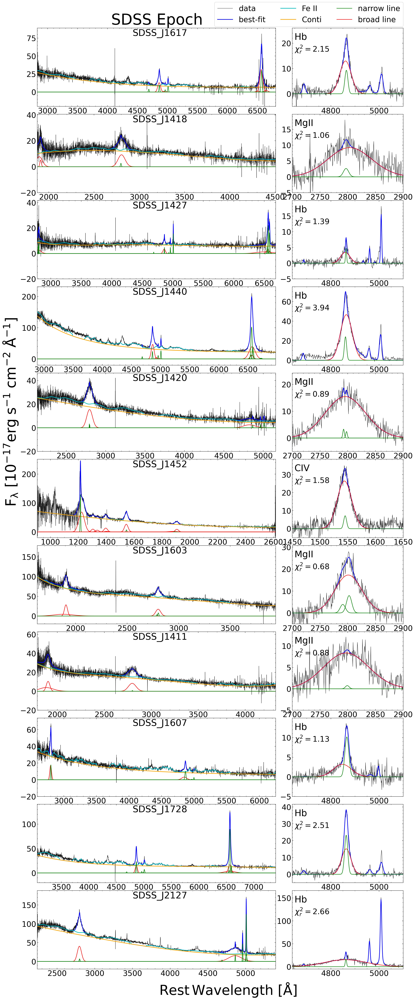

In [165]:
## figure 
itr = 0
# load file name list
file_name = [name for name in glob.glob("data/SDSS/*.fits")]
tar_name = [name[10:20] for name in file_name]
# file_name = file_name[:6]
# tar_name  = tar_name[:6]
n_raw = len(file_name)
fig = plt.figure(figsize=(24, 5*n_raw+1),dpi = 200)
gs = fig.add_gridspec(nrows=n_raw, ncols=3, left=0.05, right=0.75,
                      hspace=0.1, wspace=0.15)

for i in range(len(file_name)):
    
    ## pyqsofit
    fits_path = file_name[i]
    data = fits.open(fits_path)
    lam = 10**data[1].data['loglam']  # OBS wavelength [A]
    flux = data[1].data['flux']  # OBS flux [erg/s/cm^2/A]
    err = 1. / np.sqrt(data[1].data['ivar'])  # 1 sigma error
    z = data[2].data['z'][0]  # Redshift
    ra = data[0].header['plug_ra']  # RA
    dec = data[0].header['plug_dec']  # DEC
    plateid = data[0].header['plateid']  # SDSS plate ID
    fiberid = data[0].header['fiberid']  # SDSS fiber ID
    
    if 'J1452' in fits_path:
        mjd = 52758
    else:   
        mjd = data[0].header['mjd']  # SDSS MJD

    # get data prepared
    q = QSOFit(lam, flux, err, z, ra=ra, dec=dec, 
               plateid=plateid, mjd=mjd, fiberid=fiberid, path=path0)
    # do the fitting
    q.Fit(name=None, nsmooth=1, and_or_mask=False, deredden=True, reject_badpix=False, wave_range=None,
          wave_mask=None, decomposition_host=False, Mi=None, npca_gal=5, npca_qso=20,
          Fe_uv_op=True, Fe_flux_range=np.array([4435, 4685]), poly=True, BC=False, rej_abs=False,
          initial_guess=None, MC=False, n_trails=200, linefit=True, tie_lambda=True, tie_width=True,
          tie_flux_1=True, tie_flux_2=True, save_result=False, plot_fig=False, save_fig=False,
          plot_line_name=False, plot_legend=False, dustmap_path=path4, save_fig_path=path2,
          save_fits_path=path2, save_fits_name=tar_name[i]+"_fit_results")

    itr += 1
    plt.rcParams["xtick.direction"] = "in"
    plt.rcParams["ytick.direction"] = "in"
    plt.rcParams["xtick.top"] = True
    plt.rcParams["ytick.right"] = True
    plt.rcParams["xtick.minor.visible"] = True
    plt.rcParams["ytick.minor.visible"] = True
    plt.rcParams["xtick.labelsize"] = 25
    plt.rcParams["ytick.labelsize"] = 25
    ## ax1
    ax = fig.add_subplot(gs[i, :-1])
    if itr == 11: 
        ax.set_xlabel(r'$\rm Rest \, Wavelength$ [$\rm \AA$]', fontsize=45, labelpad=15, x=0.8)
    if itr == 5: 
        ax.set_ylabel(r'$\rm F_{\lambda}$ [$\rm 10^{-17} erg\;s^{-1}\;cm^{-2}\;\AA^{-1}$]',fontsize = 47)
    ax.set_xlim(q.wave.min(), q.wave.max())
    ax.set_ylim(-20, q.flux.max()*1.1)

    ax.plot(q.wave, q.flux, 'k', lw=0.8, alpha=0.9, label='data')
    ax.plot(q.wave,q.Manygauss(np.log(q.wave),q.gauss_result)+q.f_conti_model,'b',label='best-fit',lw=2)
    ax.plot(q.wave,q.f_conti_model,'c',lw=2, label='Fe II')
    ax.plot(q.wave,q.PL_poly_BC,'orange',lw=2, label='Conti')
    
    ax.plot(q.wave,np.full_like(q.wave, 0.0), 'g', label='narrow line')
    ax.plot(q.wave,np.full_like(q.wave, 0.0), 'r', label='broad line')
    for p in range(int(len(q.gauss_result)/3)):
        color = 'g' if q.CalFWHM(q.gauss_result[3*p+2]) < 1210. else 'r'
        ax.plot(q.wave,q.Onegauss(np.log(q.wave),q.gauss_result[p*3:(p+1)*3]),color=color)

    # ax.legend(loc='upper right', ncols=2, fontsize=14)
    if itr == 1: 
        ax.set_title(r'$\rm SDSS\ Epoch $',fontsize = 50)
        ax.legend(ncols=3, frameon=True, fontsize=25, bbox_to_anchor=(1.535, 1.33), borderaxespad = 0.)
    ax.text(0.4,0.90,tar_name[i],transform=ax.transAxes,fontdict={'size': '30', 'color': 'black'})

    
    
    ## ax2 
    ax2 = fig.add_subplot(gs[i, -1])
    # ax2.set_xlabel(r'$\rm Rest \, Wavelength$ [$\rm \AA$]', fontsize=30, labelpad=15, x=1.05)
    
    para_name   = q.gauss_result_name
    all_para    = q.gauss_result
    comp_result = q.comp_result
    
    if z < 0.71:
        line_name = 'Hb'
        lc_reswave = 4860
        min_wave = 4640
        max_wave = 5100
    elif z > 1.9:
        line_name = 'CIV'
        lc_reswave = 1550
        min_wave = lc_reswave-100
        max_wave = lc_reswave+100
    else:
        line_name = 'MgII'
        lc_reswave = 2800
        min_wave = lc_reswave-100
        max_wave = lc_reswave+100
        
    line_para_name = [name for name in para_name if line_name in name and 'whole' not in name]
    line_para = [all_para[i] for i in range(len(para_name)) if para_name[i] in line_para_name]
    ilines = np.where(comp_result == line_name)[0][0]
    chi2   = np.round(float(comp_result[ilines+3]), 2)
    em_window = (q.wave > min_wave)&(q.wave < max_wave)
    em_flux = q.line_flux[em_window]

    ax2.set_xlim(min_wave, max_wave)
    ax2.set_ylim(-5, em_flux.max()*1.1)
    ax2.plot(q.wave, q.line_flux, 'k', lw=0.8, alpha=0.9)
    ax2.plot(q.wave,q.Manygauss(np.log(q.wave),q.gauss_result),'b',lw=2)
    ax2.text(0.02,0.85,line_name,transform=ax2.transAxes,fontdict={'size': '30', 'color': 'black'})
    ax2.text(0.02,0.70,r'$\chi ^2_r=$'+str(chi2),transform=ax2.transAxes,fontdict={'size': '25', 'color': 'black'})

    for p in range(int(len(line_para)/3)):
        color = 'g' if q.CalFWHM(line_para[3*p+2]) < 1210. else 'r'
        ax2.plot(q.wave,q.Onegauss(np.log(q.wave),line_para[p*3:(p+1)*3]),color=color)

plt.savefig('image/All_SDSS_spec_fitting.pdf',dpi=600,bbox_inches='tight')

## GTC

In [166]:
file_name = [name for name in glob.glob("data/SDSS/*.fits")]
tar_name_list = [name[10:20] for name in file_name]

In [167]:
bpt_tar_list = ['SDSS_J1617', 'SDSS_J1427', 'SDSS_J1440', 'SDSS_J1728']
# spec_tar = 'SDSS_J1607'    ### wave: [2700, 6000], [6000, 6800]
tar_list = ['SDSS_J1617', 'SDSS_J1418', 'SDSS_J1427', 'SDSS_J1440', 'SDSS_J1420', 
            'SDSS_J1452', 'SDSS_J1603', 'SDSS_J1411', 'SDSS_J1607', 'SDSS_J1728', 'SDSS_J2127']
wave_range = [None, [1700, 4500], None, None, [2500, 5500], 
              None, [1830, 3700], [1800, 4300], [2700, 6200], [3400, 7300], [2650, 5500]]
decomposition_host = [True, True, True, True, True, True, True, False, True, True]

In [168]:
gtc_flux_cal_data = ascii.read(glob.glob("data/GTC-OSIRIS/Sci_spec/Flux_cal_spec/" + 'J1427' + "*.dat")[0])
gtc_flux_cal_data['fluxCal'].shape

(2027,)

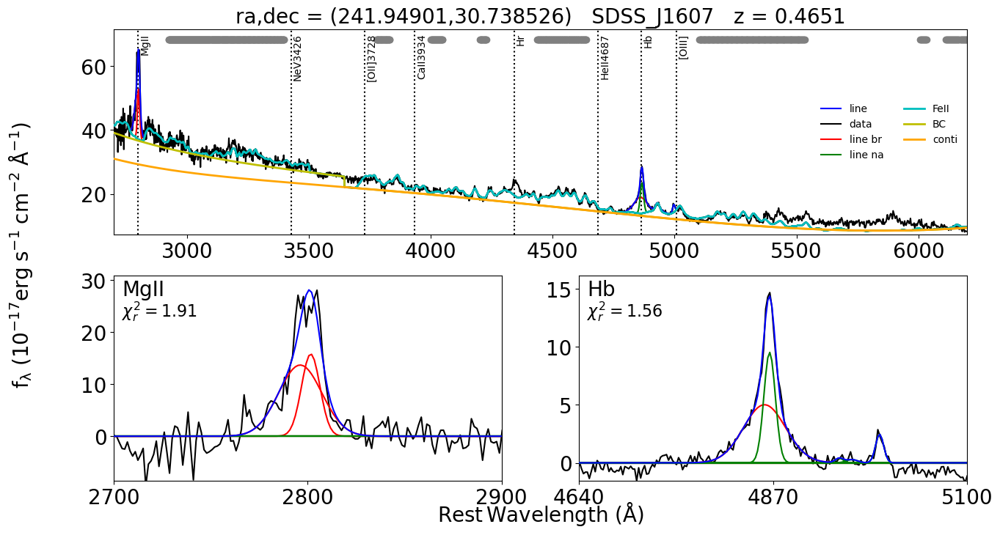

In [262]:
tar_name   = 'SDSS_J1607'
# set path
path0 = "pkg/PyQSOFit/"                 # PyQSOFit & the qsopar.fits path
path2 = 'data/fit_results/gtc_osiris/'  # path of fitting results
path4 = 'pkg/PyQSOFit/sfddata/'         # path of dusp reddening map
sdss_data_path = "data/SDSS/"
gtc_data_path  = "data/GTC-OSIRIS/Sci_spec/combined_grism/"

# load file data
gtc_C_file = glob.glob(gtc_data_path+tar_name+"*.fits")[0]
gtc_C_data = fits.open(gtc_C_file)
sdss_file  = glob.glob(sdss_data_path+"*"+tar_name+"*.fits")[0]
sdss_data  = fits.open(sdss_file)
gtc_flux_cal_data = ascii.read(glob.glob("data/GTC-OSIRIS/Sci_spec/Flux_cal_spec/" + 'J1607' + "*.dat")[0])

wave_c = gtc_C_data[1].data["wave"]
# flux_c = gtc_C_data[1].data["flux"]
flux_c = gtc_flux_cal_data['fluxCal']
var_c = gtc_C_data[1].data["var"]
z      = gtc_C_data[0].header["z"]

lam    = wave_c  # OBS wavelength [A]
flux   = flux_c  # OBS flux [erg/s/cm^2/A]
nanid  = np.where(np.isnan(flux))
flux[nanid] = 0
err    = (np.sqrt(var_c))  # 1 sigma error
nanid  = np.where(np.isnan(err))
err[nanid] = 0

# Optinal
data    = sdss_data
ra      = data[0].header['plug_ra']  # RA
dec     = data[0].header['plug_dec']  # DEC
plateid = -999  # SDSS plate ID
mjd     = -999  # SDSS MJD
fiberid = -999  # SDSS fiber ID

# get data prepared
q = QSOFit(lam,flux,err,z,path=path0,
           ra=ra,dec=dec,plateid=plateid,mjd=mjd,fiberid=fiberid)

start = timeit.default_timer()
# do the fitting
q.Fit(name=tar_name, nsmooth=1, and_or_mask=False, deredden=True, reject_badpix=False, wave_range=[2700, 6200],
      wave_mask=None, decomposition_host=False, Mi=None, npca_gal=5, npca_qso=20,
      Fe_uv_op=True, Fe_flux_range=np.array([4435,4685]), poly=True, BC=True, rej_abs=False,
      initial_guess=None, MC=False, n_trails=200, linefit=True, tie_lambda=True, tie_width=True,
      tie_flux_1=False, tie_flux_2=False, save_result=False, plot_fig=True, save_fig=False,
      plot_line_name=True, plot_legend=True, dustmap_path=path4, save_fig_path=path2,
      save_fits_path=path2, save_fits_name=tar_name+"_Fc_fit_results")

end = timeit.default_timer()


In [267]:
# # re-save fit results
# save_path = "data/fit_results/gtc_osiris/"
# target_name = tar_name
# ins_name = "_ntl"
# redshift = z
# data_test = betterOutput(q, save_path, target_name, ins_name, redshift, save_data = True, data_output=True, n_iter=500)

In [169]:
tar_list = ['SDSS_J1617', 'SDSS_J1418', 'SDSS_J1427', 'SDSS_J1440', 'SDSS_J1420', 
            'SDSS_J1452', 'SDSS_J1603', 'SDSS_J1411', 'SDSS_J1607', 'SDSS_J1728', 'SDSS_J2127']
wave_range = [None, [1700, 4500], None, None, [2500, 5500], 
              None, [1830, 3700], [1800, 4300], [2700, 6200], [3400, 7300], [2650, 5500]]
decomposition_host = [True, True, True, True, True, True, True, False, False, True, True]

In [170]:
# set path
path0 = "pkg/PyQSOFit/"                 # PyQSOFit & the qsopar.fits path
path2 = 'data/fit_results/gtc_osiris/'  # path of fitting results
path4 = 'pkg/PyQSOFit/sfddata/'         # path of dusp reddening map
sdss_data_path = "data/SDSS/"
gtc_data_path  = "data/GTC-OSIRIS/Sci_spec/combined_grism/"
gtc_Fcdata_path  = "data/GTC-OSIRIS/Sci_spec/Flux_cal_spec/"

In [ ]:
for ii in tnrange(len(tar_list)):
    tar_name = tar_list[ii]
    # load file data
    gtc_C_file = glob.glob(gtc_data_path+tar_name+"*.fits")[0]
    gtc_C_data = fits.open(gtc_C_file)
    sdss_file  = glob.glob(sdss_data_path+"*"+tar_name+"*.fits")[0]
    sdss_data  = fits.open(sdss_file)
    gtc_flux_cal_data = ascii.read(glob.glob("data/GTC-OSIRIS/Sci_spec/Flux_cal_spec/" + tar_name[5:] + "*.dat")[0])

    wave_c = gtc_C_data[1].data["wave"]
    # flux_c = gtc_C_data[1].data["flux"]
    flux_c = gtc_flux_cal_data['fluxCal']
    var_c = gtc_C_data[1].data["var"]
    z      = gtc_C_data[0].header["z"]

    lam    = wave_c  # OBS wavelength [A]
    flux   = flux_c  # OBS flux [erg/s/cm^2/A]
    nanid  = np.where(np.isnan(flux))
    flux[nanid] = 0
    err    = (np.sqrt(var_c))  # 1 sigma error
    nanid  = np.where(np.isnan(err))
    err[nanid] = 0

    # Optinal
    data    = sdss_data
    ra      = data[0].header['plug_ra']  # RA
    dec     = data[0].header['plug_dec']  # DEC
    plateid = -999  # SDSS plate ID
    mjd     = -999  # SDSS MJD
    fiberid = -999  # SDSS fiber ID

    # get data prepared
    q = QSOFit(lam,flux,err,z,path=path0,
               ra=ra,dec=dec,plateid=plateid,mjd=mjd,fiberid=fiberid)

    start = timeit.default_timer()
    # do the fitting
    q.Fit(name=tar_name, nsmooth=1, and_or_mask=False, deredden=True, reject_badpix=False, wave_range=wave_range[ii],
          wave_mask=None, decomposition_host=decomposition_host[ii], Mi=None, npca_gal=5, npca_qso=20,
          Fe_uv_op=True, Fe_flux_range=np.array([4435,4685]), poly=False, BC=False, rej_abs=False,
          initial_guess=None, MC=True, n_trails=200, linefit=True, tie_lambda=False, tie_width=True,
          tie_flux_1=True, tie_flux_2=True, save_result=True, plot_fig=True, save_fig=True,
          plot_line_name=True, plot_legend=True, dustmap_path=path4, save_fig_path=path2,
          save_fits_path=path2, save_fits_name=tar_name+"Fc_fit_results")

    end = timeit.default_timer()
    
#     save_path = "data/fit_results/gtc_osiris/"
#     target_name = tar_name
    # re-save fit results
    # save_path = "data/fit_results/gtc_osiris/"
    # target_name = tar_name
    # ins_name = "_ntl"
    # redshift = z
    # data_test = betterOutput(q, save_path, target_name, ins_name, redshift, save_data = True, data_output=True, n_iter=500)



In [268]:
# re-save fit results
# save_path = "data/fit_results/gtc_osiris/"
# target_name = tar_name
# ins_name = "_ntl"
# redshift = z
# data_test = betterOutput(q, save_path, target_name, ins_name, redshift, save_data = True, data_output=True, n_iter=500)

In [269]:
# save Fe results
# Fe_results = feMcmc(qsofit_q=q, save_path=save_path, target_name=target_name, niter=500,  save_result=True)

In [280]:
tar_list[1][5:]

'J1418'

Get negtive host galaxy flux larger than 100 pixels, decomposition is not applied!
Get negtive host galaxy flux larger than 100 pixels, decomposition is not applied!
Get negtive host galaxy flux larger than 100 pixels, decomposition is not applied!
Get negtive host galaxy flux larger than 100 pixels, decomposition is not applied!
redshift larger than 1.16 is not allowed for host decomposion!
redshift larger than 1.16 is not allowed for host decomposion!
Get negtive host galaxy flux larger than 100 pixels, decomposition is not applied!


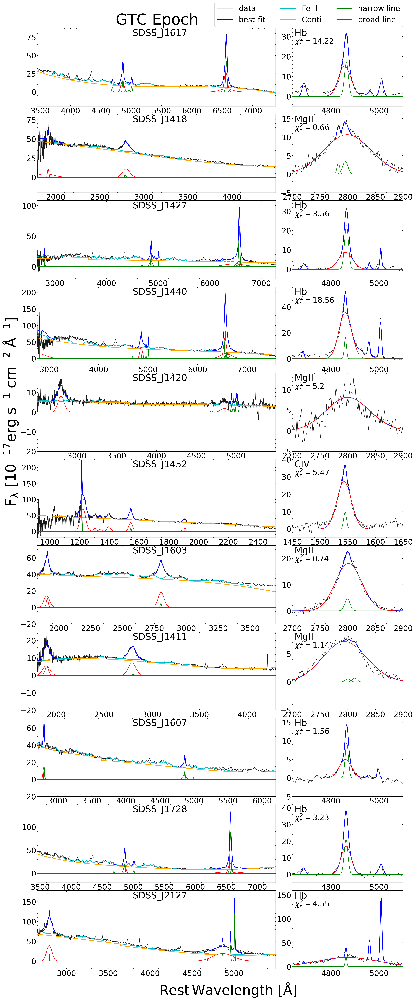

In [175]:
## figure
tar_list = ['SDSS_J1617', 'SDSS_J1418', 'SDSS_J1427', 'SDSS_J1440', 'SDSS_J1420', 
            'SDSS_J1452', 'SDSS_J1603', 'SDSS_J1411', 'SDSS_J1607', 'SDSS_J1728', 'SDSS_J2127']
wave_range = [None, [1700, 4500], None, None, [2500, 5500], 
              None, [1830, 3700], [1800, 4300], [2700, 6200], [3400, 7300], [2650, 5500]]
decomposition_host = [True, True, True, True, True, True, True, False, False, True, True]

# tar_list = tar_list[:6]
# wave_range = wave_range[:6]
# decomposition_host = decomposition_host[:6]
n_raw = len(tar_list)
fig = plt.figure(figsize=(24, 5*n_raw+1),dpi = 200)
gs = fig.add_gridspec(nrows=n_raw, ncols=3, left=0.05, right=0.75, hspace=0.1, wspace=0.15)


itr = 0
for i in range(len(tar_list)):
    
    tar_name = tar_list[i]
    
    # load file data
    gtc_C_data = fits.open(glob.glob(gtc_data_path+tar_name+"*.fits")[0])
    sdss_data  = fits.open(glob.glob(sdss_data_path+"*"+tar_name+"*.fits")[0])
    gtc_flux_cal_data = ascii.read(glob.glob(gtc_Fcdata_path + tar_name[5:] + "*.dat")[0])

    wave_c = gtc_C_data[1].data["wave"]
    # flux_c = gtc_C_data[1].data["flux"]
    flux_c = gtc_flux_cal_data['fluxCal']
    var_c = gtc_C_data[1].data["var"]
    z      = gtc_C_data[0].header["z"]
    lam    = wave_c  # OBS wavelength [A]
    flux   = flux_c  # OBS flux [erg/s/cm^2/A]
    nanid  = np.where(np.isnan(flux))
    flux[nanid] = 0
    err    = (np.sqrt(var_c))  # 1 sigma error
    nanid  = np.where(np.isnan(err))
    err[nanid] = 0
    
    # Optinal
    ra      = sdss_data[0].header['plug_ra']  # RA
    dec     = sdss_data[0].header['plug_dec']  # DEC
    plateid = -999  # SDSS plate ID
    mjd     = -999  # SDSS MJD
    fiberid = -999  # SDSS fiber ID

    # get data prepared
    q = QSOFit(lam,flux,err,z,path=path0,ra=ra,dec=dec,plateid=plateid,mjd=mjd,fiberid=fiberid)

    # do the fitting
    q.Fit(name=tar_name, nsmooth=1, and_or_mask=False, deredden=True, reject_badpix=False, wave_range=wave_range[i],
          wave_mask=None, decomposition_host=decomposition_host[i], Mi=None, npca_gal=5, npca_qso=20,
          Fe_uv_op=True, Fe_flux_range=np.array([4435,4685]), poly=True, BC=True, rej_abs=False,
          initial_guess=None, MC=False, n_trails=200, linefit=True, tie_lambda=True, tie_width=True,
          tie_flux_1=True, tie_flux_2=True, save_result=False, plot_fig=False, save_fig=False,
          plot_line_name=True, plot_legend=True, dustmap_path=path4, save_fig_path=path2,
          save_fits_path=path2, save_fits_name=tar_name+"Fc_fit_results")

    itr += 1
    plt.rcParams["xtick.direction"] = "in"
    plt.rcParams["ytick.direction"] = "in"
    plt.rcParams["xtick.top"] = True
    plt.rcParams["ytick.right"] = True
    plt.rcParams["xtick.minor.visible"] = True
    plt.rcParams["ytick.minor.visible"] = True
    plt.rcParams["xtick.labelsize"] = 25
    plt.rcParams["ytick.labelsize"] = 25
    
    ## ax1
    ax = fig.add_subplot(gs[i, :-1])
    if itr == 11: 
        ax.set_xlabel(r'$\rm Rest \, Wavelength$ [$\rm \AA$]', fontsize=45, labelpad=15, x=0.8)
    if itr == 5: 
        ax.set_ylabel(r'$\rm F_{\lambda}$ [$\rm 10^{-17} erg\;s^{-1}\;cm^{-2}\;\AA^{-1}$]',fontsize = 47)
    # ax.set_xlabel(r'$\rm Rest \, Wavelength$ [$\rm \AA$]',fontsize = 20)
    # ax.set_ylabel(r'$\rm F_{\lambda}$ [$\rm 10^{-17} erg\;s^{-1}\;cm^{-2}\;\AA^{-1}$]',fontsize = 20)
    ax.set_xlim(q.wave.min(), q.wave.max())
    ax.set_ylim(-20, q.flux.max()*1.1)

    ax.plot(q.wave, q.flux, 'k', lw=0.8, alpha=0.9, label='data')
    ax.plot(q.wave,q.Manygauss(np.log(q.wave),q.gauss_result)+q.f_conti_model,'b',label='best-fit',lw=2)
    ax.plot(q.wave,q.f_conti_model,'c',lw=2, label='Fe II')
    ax.plot(q.wave,q.PL_poly_BC,'orange',lw=2, label='Conti')
    
    ax.plot(q.wave,np.full_like(q.wave, 0.0), 'g', label='narrow line')
    ax.plot(q.wave,np.full_like(q.wave, 0.0), 'r', label='broad line')
    for p in range(int(len(q.gauss_result)/3)):
        color = 'g' if q.CalFWHM(q.gauss_result[3*p+2]) < 1210. else 'r'
        ax.plot(q.wave,q.Onegauss(np.log(q.wave),q.gauss_result[p*3:(p+1)*3]),color=color)

    if itr == 1: 
        ax.set_title(r'$\rm GTC\ Epoch $',fontsize = 50)
        ax.legend(ncols=3, frameon=True, fontsize=25, bbox_to_anchor=(1.535, 1.33), borderaxespad = 0.)
    # ax.legend(loc='upper right', ncols=2, fontsize=14)
    ax.text(0.4,0.90,tar_name,transform=ax.transAxes,fontdict={'size': '30', 'color': 'black'})

    
    
    ## ax2 
    ax2 = fig.add_subplot(gs[i, -1])
    
    para_name   = q.gauss_result_name
    all_para    = q.gauss_result
    comp_result = q.comp_result
    
    if z < 0.71:
        line_name = 'Hb'
        lc_reswave = 4860
        min_wave = 4640
        max_wave = 5100
    elif z > 1.9:
        line_name = 'CIV'
        lc_reswave = 1550
        min_wave = lc_reswave-100
        max_wave = lc_reswave+100
    else:
        line_name = 'MgII'
        lc_reswave = 2800
        min_wave = lc_reswave-100
        max_wave = lc_reswave+100
        
    line_para_name = [name for name in para_name if line_name in name and 'whole' not in name]
    line_para = [all_para[i] for i in range(len(para_name)) if para_name[i] in line_para_name]
    ilines = np.where(comp_result == line_name)[0][0]
    chi2   = np.round(float(comp_result[ilines+3]), 2)
    em_window = (q.wave > min_wave)&(q.wave < max_wave)
    em_flux = q.line_flux[em_window]

    ax2.set_xlim(min_wave, max_wave)
    ax2.set_ylim(-5, em_flux.max()*1.1)
    ax2.plot(q.wave, q.line_flux, 'k', lw=0.8, alpha=0.9)
    ax2.plot(q.wave,q.Manygauss(np.log(q.wave),q.gauss_result),'b',lw=2)
    ax2.text(0.02,0.90,line_name,transform=ax2.transAxes,fontdict={'size': '30', 'color': 'black'})
    ax2.text(0.02,0.80,r'$\chi ^2_r=$'+str(chi2),transform=ax2.transAxes,fontdict={'size': '25', 'color': 'black'})

    for p in range(int(len(line_para)/3)):
        color = 'g' if q.CalFWHM(line_para[3*p+2]) < 1210. else 'r'
        ax2.plot(q.wave,q.Onegauss(np.log(q.wave),line_para[p*3:(p+1)*3]),color=color)

plt.savefig('image/All_GTC_spec_fitting.pdf',dpi=600,bbox_inches='tight')

# Results

In [6]:
xl_RGB_List = ('0,0,0','56,72,113','231,189,57','171,79,63','71,133,90')
xm_RGB_List = ('36,50,88','40,114,70','177,1966,77','231,199,54','247,191,99',
               '238,176,175','150,52,96','99,31,102','141,87,41','1,137,157')

In [7]:
xmcl = RGB2Hex(xm_RGB_List)

In [237]:
plt.rcParams["xtick.direction"] = "in"
plt.rcParams["ytick.direction"] = "in"
plt.rcParams["xtick.top"] = True
plt.rcParams["ytick.right"] = True
plt.rcParams["xtick.minor.visible"] = True
plt.rcParams["ytick.minor.visible"] = True
plt.rcParams["xtick.labelsize"] = 16
plt.rcParams["ytick.labelsize"] = 16

In [62]:
file_name = [name for name in glob.glob("data/SDSS/*.fits")]
tar_name  = np.array([name[10:20] for name in file_name])
redshift  = []
ra = []
dec = []

for i in np.arange(len(tar_name)):
    file = fits.open(file_name[i])
    rai = file[0].header['plug_ra']  # RA
    deci = file[0].header['plug_dec']  # DEC
    z    = file[2].data['z'][0]     
    redshift.append(z)
    ra.append(rai)
    dec.append(deci)
redshift  = np.asarray(redshift) 
ra  = np.asarray(ra) 
dec  = np.asarray(dec) 
tar_name  = np.asarray(tar_name)

In [83]:
redshift

array([0.353428  , 1.0418948 , 0.37362438, 0.31874976, 0.78662   ,
       2.9711769 , 1.3339976 , 1.129845  , 0.4650761 , 0.24549723,
       0.70392036], dtype=float32)

In [88]:
ra

array([244.25341, 214.51164, 216.94332, 220.21154, 215.20278, 223.02874,
       240.97103, 212.83102, 241.94901, 262.00279, 321.81391])

In [87]:
file_name = [name for name in glob.glob("data/SDSS/*.fits")]
name  = np.array([name[15:-5] for name in file_name])
name

array(['J161700.81+124332.2', 'J141802.79+414935.2',
       'J142746.39+293038.2', 'J144050.76+520445.9',
       'J142048.66+375755.4', 'J145206.89+360226.0',
       'J160353.04+264515.9', 'J141119.44+413802.3',
       'J160747.76+304418.6', 'J172800.66+545302.7',
       'J212715.33-062041.6'], dtype='<U19')

## Spectral Type

### Hb,br/[O III]

In [64]:
# data = Table()
# data["Object"] = tar_name
# data["RA"] = ra
# data["decl"] = dec
# data["z"] = redshift
# ascii.write(data,"data/target_info.dat",overwrite=True)

In [65]:
zm = np.where(redshift<1)
tar_name[zm],redshift[zm]
hb03_tar_list = np.delete(tar_name[zm],4)
hb03_tar_list

array(['SDSS_J1617', 'SDSS_J1427', 'SDSS_J1440', 'SDSS_J1420',
       'SDSS_J1728', 'SDSS_J2127'], dtype='<U10')

In [66]:
names = hb03_tar_list
new_name = [name.split('_')[0]+" "+name.split('_')[1] for name in names]

In [72]:
##  SDSS table

AGN_type_SDSS = np.full(hb03_tar_list.shape[0],np.nan)
hb_na_flux = np.full(hb03_tar_list.shape[0],np.nan)
hb_br_flux = np.full(hb03_tar_list.shape[0],np.nan)
hb_na_flux_err = np.full(hb03_tar_list.shape[0],np.nan)
hb_br_flux_err = np.full(hb03_tar_list.shape[0],np.nan)
hb_br_fwhm = np.full(hb03_tar_list.shape[0],np.nan)
hb_br_fwhm_err = np.full(hb03_tar_list.shape[0],np.nan)
O3_flux = np.full(hb03_tar_list.shape[0],np.nan)
O3_flux_err = np.full(hb03_tar_list.shape[0],np.nan)

for jj in tnrange(hb03_tar_list.shape[0]):
    result_dat = ascii.read("data/fit_results/sdss_dr9/"+hb03_tar_list[jj]+"_line_properties.dat")
    result_fit = fits.open(glob.glob("data/fit_results/sdss_dr9/*"+hb03_tar_list[jj]+"*.fits")[0])
    
    hb_na_flux[jj] = result_dat[result_dat["name"]=='Hb_na_1']["flux"]
    # hb_na_flux_err[jj] = result_dat[result_dat["name"]=='Hb_na_1']["flux_err"]
    hb_br_flux[jj] = result_fit[1].data["Hb_whole_br_area"]
    # hb_br_flux_err[jj] = result_fit[1].data["Hb_whole_br_area_err"]
    hb_br_fwhm[jj] = result_fit[1].data["Hb_whole_br_fwhm"]
    # hb_br_fwhm_err[jj] = result_fit[1].data["Hb_whole_br_fwhm_err"]
    
    O3_flux[jj] = result_dat[result_dat["name"]=='OIII5007c_1']["flux"]
    # O3_flux_err[jj] = result_dat[result_dat["name"]=='OIII5007c_1']["flux_err"]

  0%|          | 0/6 [00:00<?, ?it/s]

In [73]:
## GTC data table

AGN_type_GTC = np.full(hb03_tar_list.shape[0],np.nan)
GTC_hb_na_flux = np.full(hb03_tar_list.shape[0],np.nan)
GTC_hb_br_flux = np.full(hb03_tar_list.shape[0],np.nan)
GTC_hb_na_flux_err = np.full(hb03_tar_list.shape[0],np.nan)
GTC_hb_br_flux_err = np.full(hb03_tar_list.shape[0],np.nan)
GTC_hb_br_fwhm = np.full(hb03_tar_list.shape[0],np.nan)
GTC_hb_br_fwhm_err = np.full(hb03_tar_list.shape[0],np.nan)

GTC_O3_flux = np.full(hb03_tar_list.shape[0],np.nan)
GTC_O3_flux_err = np.full(hb03_tar_list.shape[0],np.nan)

for jj in tnrange(hb03_tar_list.shape[0]):      
    result_dat = ascii.read(glob.glob("data/fit_results/gtc_osiris/*"+hb03_tar_list[jj]+"*line*.dat")[0])
    result_fit = fits.open(glob.glob("data/fit_results/gtc_osiris/*"+hb03_tar_list[jj]+"*_ntl.fits")[0])
    
    GTC_hb_na_flux[jj] = result_dat[result_dat["name"]=='Hb_na_1']["flux"]
    # GTC_hb_na_flux_err[jj] = result_dat[result_dat["name"]=='Hb_na_1']["flux_err"]
    GTC_hb_br_flux[jj] = result_fit[1].data["Hb_whole_br_area"]
    # GTC_hb_br_flux_err[jj] = result_fit[1].data["Hb_whole_br_area_err"]
    GTC_hb_br_fwhm[jj] = result_fit[1].data["Hb_whole_br_fwhm"]
    # GTC_hb_br_fwhm_err[jj] = result_fit[1].data["Hb_whole_br_fwhm_err"]
    
    GTC_O3_flux[jj] = result_dat[result_dat["name"]=='OIII5007c_1']["flux"]
    # GTC_O3_flux_err[jj] = result_dat[result_dat["name"]=='OIII5007c_1']["flux_err"]

  0%|          | 0/6 [00:00<?, ?it/s]

In [74]:
# F_Hb_SDSS = hb_na_flux + hb_br_flux
# F_Hb_SDSS_err = np.sqrt(hb_na_flux_err**2 + hb_br_flux_err**2)
# F_O3_SDSS = O3_flux
# F_O3_SDSS_err = O3_flux_err
# SDSS_O3_Hb = F_Hb_SDSS/F_O3_SDSS
# SDSS_O3_Hb_err = np.sqrt((F_O3_SDSS_err/F_O3_SDSS)**2 + (F_Hb_SDSS_err/F_Hb_SDSS)**2)

# F_Hb_GTC = GTC_hb_na_flux + GTC_hb_br_flux
# F_Hb_GTC_err = np.sqrt(GTC_hb_na_flux_err**2 + GTC_hb_br_flux_err**2)
# F_O3_GTC = GTC_O3_flux
# F_O3_GTC_err = GTC_O3_flux_err
# GTC_O3_Hb = F_Hb_GTC/F_O3_GTC
# GTC_O3_Hb_err = np.sqrt((F_O3_GTC_err/F_O3_GTC)**2 + (F_Hb_GTC_err/F_Hb_GTC)**2)

In [75]:
F_Hb_SDSS =  hb_br_flux
F_Hb_SDSS_err = hb_br_flux_err
F_O3_SDSS = O3_flux
F_O3_SDSS_err = O3_flux_err
SDSS_O3_Hb = F_Hb_SDSS/F_O3_SDSS
SDSS_O3_Hb_err = np.sqrt((F_O3_SDSS_err/F_O3_SDSS)**2 + (F_Hb_SDSS_err/F_Hb_SDSS)**2)

F_Hb_GTC = GTC_hb_br_flux
F_Hb_GTC_err = GTC_hb_br_flux_err
F_O3_GTC = GTC_O3_flux
F_O3_GTC_err = GTC_O3_flux_err
GTC_O3_Hb = F_Hb_GTC/F_O3_GTC
GTC_O3_Hb_err = np.sqrt((F_O3_GTC_err/F_O3_GTC)**2 + (F_Hb_GTC_err/F_Hb_GTC)**2)

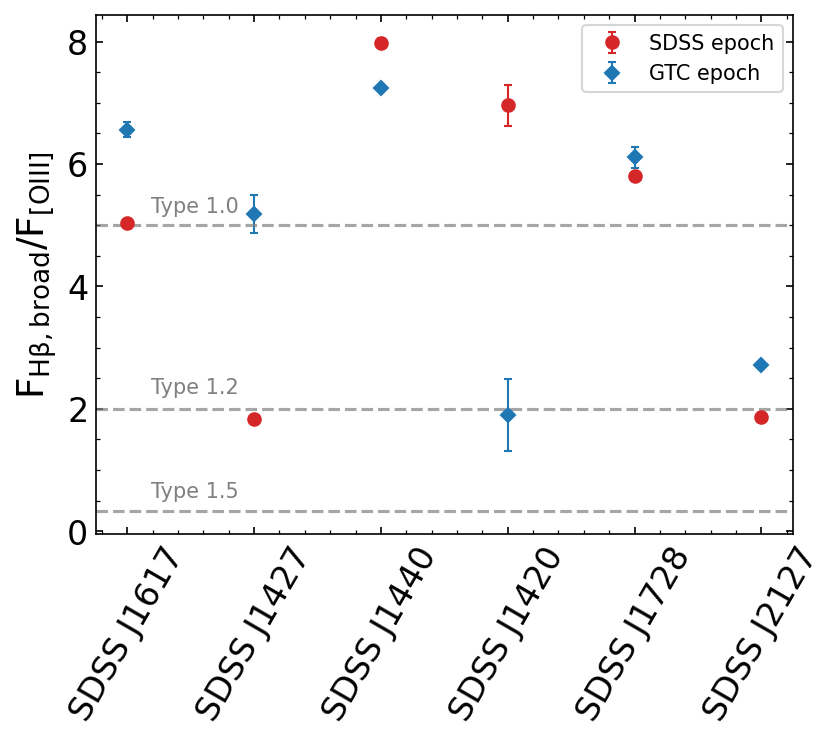

In [152]:
fig = plt.figure(figsize = (6,4.5),dpi=150)

ax  = plt.subplot(111)
# ax.set_xlabel(r"${\rm  Target}$", fontsize=15)
ax.set_ylabel(r"${\rm F_{\rm H\beta, broad}/ F_{\rm [O III]} }$", fontsize=18)
# ax.set_title(target_name, fontsize=15)
plt.xticks(rotation=60)

ax.errorbar(new_name, SDSS_O3_Hb, yerr = SDSS_O3_Hb_err, 
            color = 'C3',linestyle="None", marker="o", elinewidth=1,ms=6,capsize=2,
            label = "SDSS epoch")

ax.errorbar(new_name, GTC_O3_Hb, yerr = GTC_O3_Hb_err, 
            color = 'C0',linestyle="None", marker="D", elinewidth=1,ms=5,capsize=2,
            label = "GTC epoch")

ax.axhline(y=5.0,color='grey',linestyle="--", alpha=0.7)
ax.text(0.08,0.62,'Type 1.0',transform=ax.transAxes,fontdict={'size': '10', 'color': 'grey'})
ax.axhline(y=2.0,color='grey',linestyle="--", alpha=0.7)
ax.text(0.08,0.27,'Type 1.2',transform=ax.transAxes,fontdict={'size': '10', 'color': 'grey'})
ax.axhline(y=1/3,color='grey',linestyle="--", alpha=0.7)
ax.text(0.08,0.07,'Type 1.5',transform=ax.transAxes,fontdict={'size': '10', 'color': 'grey'})
plt.legend(loc='upper right')

# plt.savefig('image/AGN_type.pdf',dpi=600,bbox_inches='tight')

### Hb,n/Hb,br

In [616]:
SDSS_st = np.full(hb03_tar_list.shape[0],np.nan)
SDSS_st_err = np.full(hb03_tar_list.shape[0],np.nan)
GTC_st = np.full(hb03_tar_list.shape[0],np.nan)
GTC_st_err = np.full(hb03_tar_list.shape[0],np.nan)

for i in range(len(hb03_tar_list)):
    SDSS_st[i], SDSS_st_err[i] = spectralType(hb_na_flux[i], hb_na_flux_err[i], hb_br_flux[i], hb_br_flux_err[i])
    GTC_st[i] , GTC_st_err[i]  = spectralType(GTC_hb_na_flux[i], GTC_hb_na_flux_err[i], GTC_hb_br_flux[i], GTC_hb_br_flux_err[i])

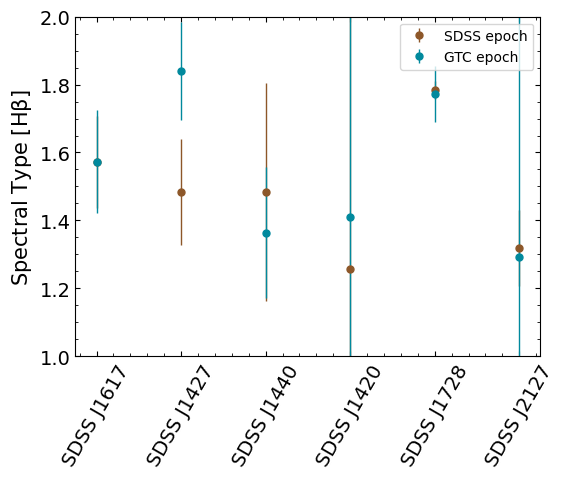

In [679]:
fig = plt.figure(figsize = (6,4.5), dpi = 100)

ax  = plt.subplot(111)
# ax.set_xlabel(r"${\rm  Target}$", fontsize=15)
ax.set_ylabel(r"${\rm Spectral\ Type\ [{\rm H\beta}] }$", fontsize=15)
# ax.set_title(target_name, fontsize=15)
plt.xticks(rotation=60)

ax.errorbar(new_name, SDSS_st, yerr = SDSS_st_err, 
            color = xmcl["C8"],linestyle="None", marker="o", elinewidth=1,ms=5,capsize=0,
            label = "SDSS epoch")

ax.errorbar(new_name, GTC_st, yerr = GTC_st_err, 
            color = xmcl["C9"],linestyle="None", marker="o", elinewidth=1,ms=5,capsize=0,
            label = "GTC epoch")
ax.set_ylim(1,2)
plt.legend()

# plt.savefig('image/spec_type.pdf',dpi=600,bbox_inches='tight')

In [412]:
# data = Table()
# data["Object"] = hb03_tar_list
# data["Hb_O3(SDSS)"] = SDSS_O3_Hb
# data["Hb_O3_err(SDSS)"] = SDSS_O3_Hb_err
# data["Hb_O3(GTC)"] = GTC_O3_Hb
# data["Hb_O3_err(GTC)"] = GTC_O3_Hb_err

# ascii.write(data,"data/AGN_type2epoch.dat",overwrite=True)

## Hb broad Flux, FWHM 

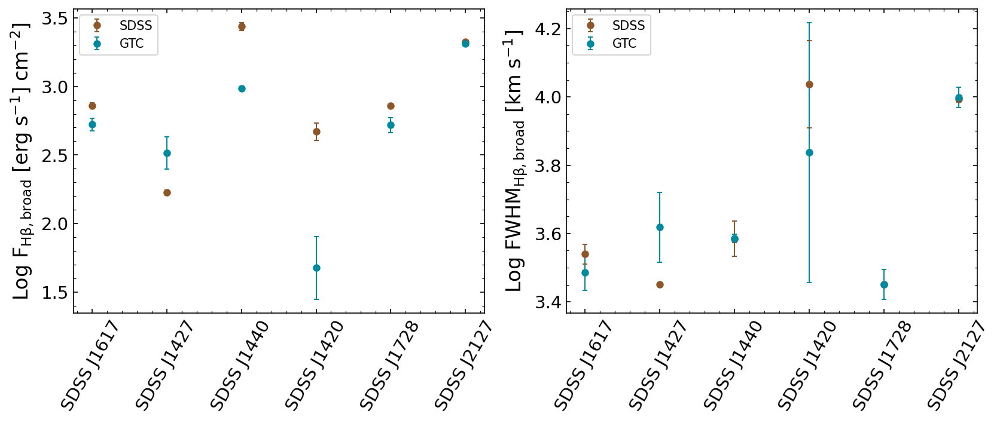

In [678]:
fig = plt.figure(figsize = (13,4.5), dpi = 150)

ax  = plt.subplot(121)

# ax.set_xlabel(r"${\rm  Target}$", fontsize=15)
ax.set_ylabel(r"${\rm Log\ F_{\rm H\beta, broad}\ [erg\;s^{-1}]\;cm^{-2}]}$", fontsize=16)
# ax.set_title(target_name, fontsize=15)
plt.xticks(rotation=60)

ax.errorbar(new_name, np.log10(F_Hb_SDSS), yerr = (F_Hb_SDSS_err/F_Hb_SDSS)/np.log(10), 
            color = xmcl["C8"],linestyle="None", marker="o", elinewidth=1,ms=5,capsize=2,
            label = "SDSS")

ax.errorbar(new_name, np.log10(F_Hb_GTC), yerr = (F_Hb_GTC_err/F_Hb_GTC)/np.log(10), 
            color = xmcl["C9"],linestyle="None", marker="o", elinewidth=1,ms=5,capsize=2,
            label = "GTC")
plt.legend(loc='upper left')


ax1  = plt.subplot(122)

# ax.set_xlabel(r"${\rm  Target}$", fontsize=15)
ax1.set_ylabel(r"${\rm Log\ FWHM_{\rm H\beta, broad}\ [km\;s^{-1}] }$", fontsize=16)
# ax.set_title(target_name, fontsize=15)
plt.xticks(rotation=60)

ax1.errorbar(new_name, np.log10(hb_br_fwhm), yerr = (hb_br_fwhm_err/hb_br_fwhm)/np.log(10), 
            color = xmcl["C8"],linestyle="None", marker="o", elinewidth=1,ms=5,capsize=2,
            label = "SDSS")

ax1.errorbar(new_name, np.log10(GTC_hb_br_fwhm), yerr = (GTC_hb_br_fwhm_err/GTC_hb_br_fwhm)/np.log(10), 
            color = xmcl["C9"],linestyle="None", marker="o", elinewidth=1,ms=5,capsize=2,
            label = "GTC")
plt.legend(loc='upper left')

plt.savefig('image/Hb_broad.pdf',dpi=600,bbox_inches='tight')

## Ha broad Flux, FWHM

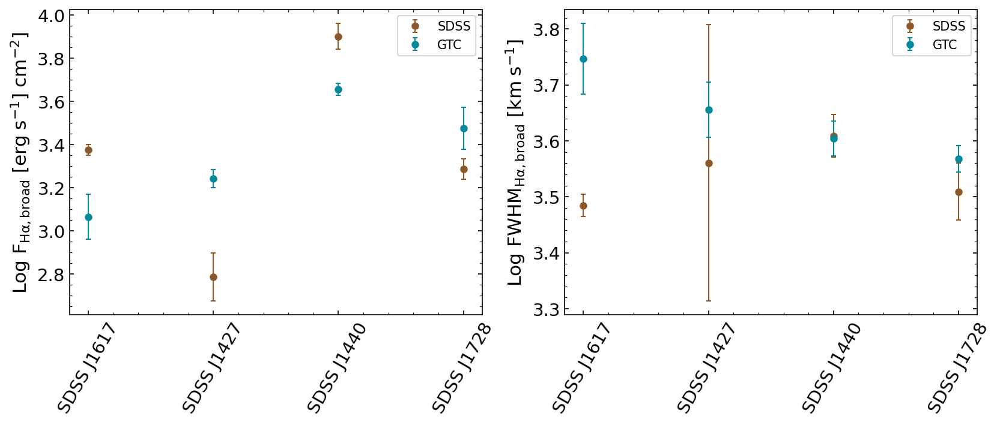

In [677]:
fig = plt.figure(figsize = (13,4.5), dpi = 150)

ax  = plt.subplot(121)
# ax.set_xlabel(r"${\rm  Target}$", fontsize=15)
ax.set_ylabel(r"${\rm Log\ F_{\rm H\alpha, broad}\ [erg\;s^{-1}]\;cm^{-2}]}$", fontsize=15)
# ax.set_title(target_name, fontsize=15)
plt.xticks(rotation=60)

names = np.array(["SDSS J1617", "SDSS J1427", "SDSS J1440", "SDSS J1728"])

ax.errorbar(names, np.log10(SDSS_Ha_broad_flux), yerr = (SDSS_Ha_broad_flux_err/SDSS_Ha_broad_flux)/np.log(10), 
            color = xmcl["C8"],linestyle="None", marker="o", elinewidth=1,ms=5,capsize=2,
            label = "SDSS")

ax.errorbar(names, np.log10(GTC_Ha_broad_flux), yerr = (GTC_Ha_broad_flux_err/GTC_Ha_broad_flux)/np.log(10), 
            color = xmcl["C9"],linestyle="None", marker="o", elinewidth=1,ms=5,capsize=2,
            label = "GTC")
plt.legend(loc='upper right')


ax1  = plt.subplot(122)
# ax.set_xlabel(r"${\rm  Target}$", fontsize=15)
ax1.set_ylabel(r"${\rm Log\ FWHM_{\rm H\alpha, broad}\ [km\;s^{-1}] }$", fontsize=15)
# ax.set_title(target_name, fontsize=15)
plt.xticks(rotation=60)

ax1.errorbar(names, np.log10(SDSS_Ha_FWHM), yerr = (SDSS_Ha_FWHM_err/SDSS_Ha_FWHM)/np.log(10), 
            color = xmcl["C8"],linestyle="None", marker="o", elinewidth=1,ms=5,capsize=2,
            label = "SDSS")

ax1.errorbar(names, np.log10(GTC_Ha_FWHM), yerr = (GTC_Ha_FWHM_err/GTC_Ha_FWHM)/np.log(10), 
            color = xmcl["C9"],linestyle="None", marker="o", elinewidth=1,ms=5,capsize=2,
            label = "GTC")
plt.legend(loc='upper right')

plt.savefig('image/Ha_broad.pdf',dpi=600,bbox_inches='tight')

## MgII Flux, FWHM

In [306]:
z_mask = (redshift>0.4) & (redshift<2)
mg2_tar_list = tar_name[z_mask]
mg2_names = [name.split('_')[0]+" "+name.split('_')[1] for name in mg2_tar_list]


In [549]:
## SDSS data table
SDSS_Mg2_flux = np.full(mg2_tar_list.shape[0],np.nan)
SDSS_Mg2_fwhm = np.full(mg2_tar_list.shape[0],np.nan)
SDSS_Mg2_ew = np.full(mg2_tar_list.shape[0],np.nan)
SDSS_Mg2_flux_err = np.full(mg2_tar_list.shape[0],np.nan)
SDSS_Mg2_fwhm_err = np.full(mg2_tar_list.shape[0],np.nan)
SDSS_Mg2_ew_err = np.full(mg2_tar_list.shape[0],np.nan)

for jj in tnrange(mg2_tar_list.shape[0]):
    if "J2127" in mg2_tar_list[jj]:
        result_fit = fits.open(glob.glob("data/fit_results/sdss_dr9/SDSS_J2127_fit_results_MgII.fits")[0])
    else:
        result_fit = fits.open(glob.glob("data/fit_results/sdss_dr9/*"+mg2_tar_list[jj]+"*.fits")[0])
        
    SDSS_Mg2_flux[jj] = result_fit[1].data["MgII_whole_br_area"]
    SDSS_Mg2_fwhm[jj] = result_fit[1].data["MgII_whole_br_fwhm"]
    SDSS_Mg2_ew[jj] = result_fit[1].data["MgII_whole_br_ew"]
    SDSS_Mg2_ew_err[jj] = result_fit[1].data["MgII_whole_br_ew_err"]
    SDSS_Mg2_flux_err[jj] = result_fit[1].data["MgII_whole_br_area_err"]
    SDSS_Mg2_fwhm_err[jj] = result_fit[1].data["MgII_whole_br_fwhm_err"]

In [550]:
## GTC data table
GTC_Mg2_flux = np.full(mg2_tar_list.shape[0],np.nan)
GTC_Mg2_fwhm = np.full(mg2_tar_list.shape[0],np.nan)
GTC_Mg2_ew = np.full(mg2_tar_list.shape[0],np.nan)
GTC_Mg2_flux_err = np.full(mg2_tar_list.shape[0],np.nan)
GTC_Mg2_fwhm_err = np.full(mg2_tar_list.shape[0],np.nan)
GTC_Mg2_ew_err = np.full(mg2_tar_list.shape[0],np.nan)

for jj in tnrange(mg2_tar_list.shape[0]):
    
    if "J1607" in mg2_tar_list[jj]:
        result_fit = fits.open(glob.glob("data/fit_results/gtc_osiris/SDSS_J1607_fit_results_Mg2Hb.fits")[0])
    else:
        result_fit = fits.open(glob.glob("data/fit_results/gtc_osiris/*"+mg2_tar_list[jj]+"*_ntl.fits")[0])
        
    GTC_Mg2_flux[jj] = result_fit[1].data["MgII_whole_br_area"]
    GTC_Mg2_fwhm[jj] = result_fit[1].data["MgII_whole_br_fwhm"]
    GTC_Mg2_ew[jj] = result_fit[1].data["MgII_whole_br_ew"]
    GTC_Mg2_ew_err[jj] = result_fit[1].data["MgII_whole_br_ew_err"]
    GTC_Mg2_flux_err[jj] = result_fit[1].data["MgII_whole_br_area_err"]
    GTC_Mg2_fwhm_err[jj] = result_fit[1].data["MgII_whole_br_fwhm_err"]

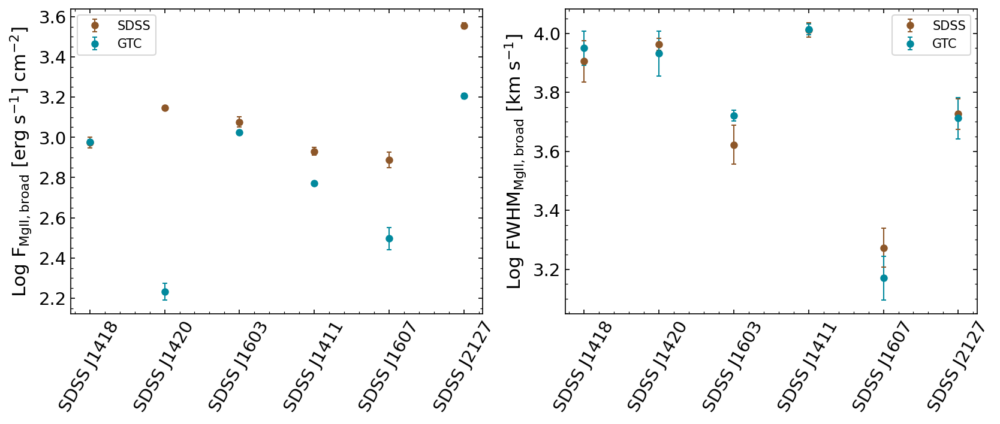

In [675]:
fig = plt.figure(figsize = (13,4.5), dpi = 150)

ax  = plt.subplot(121)

# ax.set_xlabel(r"${\rm  Target}$", fontsize=15)
ax.set_ylabel(r"${\rm Log\ F_{\rm MgII, broad}\ [erg\;s^{-1}]\;cm^{-2}] }$", fontsize=15)
# ax.set_title(target_name, fontsize=15)
plt.xticks(rotation=60)

ax.errorbar(mg2_names, np.log10(SDSS_Mg2_flux), yerr = (SDSS_Mg2_flux_err/SDSS_Mg2_flux)/np.log(10), 
            color = xmcl["C8"],linestyle="None", marker="o", elinewidth=1,ms=5,capsize=2,
            label = "SDSS")

ax.errorbar(mg2_names, np.log10(GTC_Mg2_flux), yerr = (GTC_Mg2_flux_err/GTC_Mg2_flux)/np.log(10), 
            color = xmcl["C9"],linestyle="None", marker="o", elinewidth=1,ms=5,capsize=2,
            label = "GTC")
plt.legend()


ax1  = plt.subplot(122)
# ax.set_xlabel(r"${\rm  Target}$", fontsize=15)
ax1.set_ylabel(r"${\rm Log\ FWHM_{\rm MgII, broad}\ [km\;s^{-1}] }$", fontsize=15)
# ax.set_title(target_name, fontsize=15)
plt.xticks(rotation=60)

ax1.errorbar(mg2_names, np.log10(SDSS_Mg2_fwhm), yerr = (SDSS_Mg2_fwhm_err/SDSS_Mg2_fwhm)/np.log(10), 
            color = xmcl["C8"],linestyle="None", marker="o", elinewidth=1,ms=5,capsize=2,
            label = "SDSS")

ax1.errorbar(mg2_names, np.log10(GTC_Mg2_fwhm), yerr = (GTC_Mg2_fwhm_err/GTC_Mg2_fwhm)/np.log(10), 
            color = xmcl["C9"],linestyle="None", marker="o", elinewidth=1,ms=5,capsize=2,
            label = "GTC")
plt.legend()

plt.savefig('image/Mg2_broad.pdf',dpi=600,bbox_inches='tight')

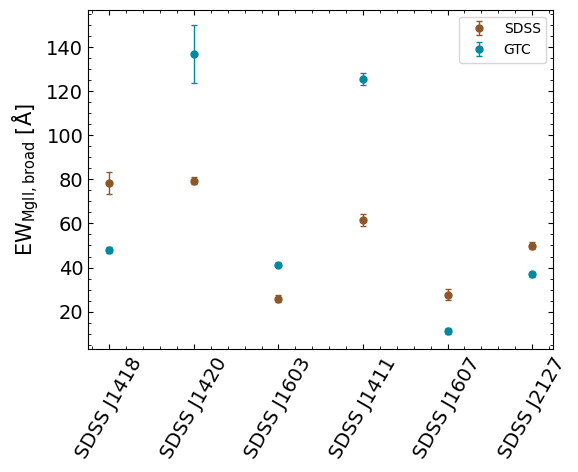

In [673]:
fig = plt.figure(figsize = (6,4.5), dpi = 100)

ax  = plt.subplot(111)
# ax.set_xlabel(r"${\rm  Target}$", fontsize=15)
ax.set_ylabel(r"${\rm EW_{\rm MgII, broad}\ [\AA] }$", fontsize=15)
# ax.set_title(target_name, fontsize=15)
plt.xticks(rotation=60)

ax.errorbar(mg2_names, SDSS_Mg2_ew, yerr = SDSS_Mg2_ew_err, 
            color = xmcl["C8"],linestyle="None", marker="o", elinewidth=1,ms=5,capsize=2,
            label = "SDSS")

ax.errorbar(mg2_names, GTC_Mg2_ew, yerr = GTC_Mg2_ew_err, 
            color = xmcl["C9"],linestyle="None", marker="o", elinewidth=1,ms=5,capsize=2,
            label = "GTC")
plt.legend()


In [594]:
log_Lcon = np.array([data_sdss["L3000"][4],data_gtc["L3000"][4]])
log_EWMG2 = np.array([np.log10(SDSS_Mg2_ew[1]), np.log10(GTC_Mg2_ew[1])])

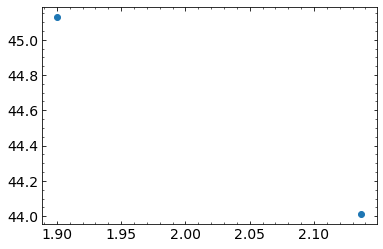

In [598]:
plt.scatter(log_EWMG2, log_Lcon)
fakex = np.arange(1.5, 2.5, 0.01)
# plt.plot(fakex, func(fakex,*p))

In [585]:
def func(x,*p):
    return 

In [590]:
p0 = np.array([1,-0.5, 0])
bounds = ([0, -5,0],[1e50, 5,1e45])

p, perr = curve_fit(func, log_EWMG2, log_Lcon, 
                    p0=p0, bounds = bounds, 
                    maxfev = 10000)

In [591]:
p

array([ 1.e+00, -5.e-01,  1.e-10])

## BPT diagram

In [24]:
file_name = [name for name in glob.glob("data/SDSS/*.fits")]
tar_name_list = [name[10:20] for name in file_name]
snr_cut = 2

In [25]:
def tarBptSeclet(tar_name):
    line_prop_path = glob.glob("data/fit_results/sdss_dr9/*"+tar_name+"*_line_properties.dat")[0]
    data = ascii.read(line_prop_path)
    if 'Ha_na_1' in data["name"]:
        return tar_name
    elif "Ha_br_1" in data["name"]:
        return tar_name

In [26]:
bpt_list = []
for name in tar_name_list:
    namei = tarBptSeclet(name)
    bpt_list.append(namei)

In [50]:
key_word = ['L1350', 'L1350_err', 'L3000', 'L3000_err', 'L5100', 'L5100_err', 
            'Hb_whole_br_fwhm', 'Hb_whole_br_fwhm_err', 'Hb_whole_br_ew', 'Hb_whole_br_ew_err', 'Hb_whole_br_area', 'Hb_whole_br_area_err', 
            'MgII_whole_br_fwhm', 'MgII_whole_br_fwhm_err', 'MgII_whole_br_ew', 'MgII_whole_br_ew_err', 'MgII_whole_br_area', 'MgII_whole_br_area_err',
            'CIV_whole_br_fwhm', 'CIV_whole_br_fwhm_err', 'CIV_whole_br_ew', 'CIV_whole_br_ew_err', 'CIV_whole_br_area', 'CIV_whole_br_area_err', 
           ]

In [148]:
gtc_result_path = "data/fit_results/gtc_osiris/"
sdss_result_path = "data/fit_results/sdss_dr9/"

## Balmer decrement


In [408]:
gtc_result_path = "data/fit_results/gtc_osiris/"
sdss_result_path = "data/fit_results/sdss_dr9/"

In [409]:
names = np.array(["J1617", "J1427", "J1440", "J1728"])
SDSS_Ha_broad_flux = np.zeros(4)
SDSS_Ha_broad_flux_err = np.zeros(4)
SDSS_Hb_broad_flux = np.zeros(4)
SDSS_Hb_broad_flux_err = np.zeros(4)

GTC_Ha_broad_flux = np.zeros(4)
GTC_Ha_broad_flux_err = np.zeros(4)
GTC_Hb_broad_flux = np.zeros(4)
GTC_Hb_broad_flux_err = np.zeros(4)

for i in range(len(names)):
    SDSS_file = fits.open(glob.glob(sdss_result_path+"*"+names[i]+"*.fits")[-1])
    GTC_file  = fits.open(glob.glob(gtc_result_path +"*"+names[i]+"*_ntl.fits")[0])
    
    SDSS_Ha_broad_flux[i] = SDSS_file[1].data['Ha_whole_br_area']
    SDSS_Ha_broad_flux_err[i] = SDSS_file[1].data['Ha_whole_br_area_err']
    SDSS_Hb_broad_flux[i] = SDSS_file[1].data['Hb_whole_br_area']
    SDSS_Hb_broad_flux_err[i] = SDSS_file[1].data['Hb_whole_br_area_err']
    
    GTC_Ha_broad_flux[i] = GTC_file[1].data["Ha_whole_br_area"]
    GTC_Ha_broad_flux_err[i] = GTC_file[1].data["Ha_whole_br_area_err"]
    GTC_Hb_broad_flux[i] = GTC_file[1].data["Hb_whole_br_area"]
    GTC_Hb_broad_flux_err[i] = GTC_file[1].data["Hb_whole_br_area_err"]



In [410]:
sdss_ha2hb     = SDSS_Ha_broad_flux/SDSS_Hb_broad_flux
sdss_ha2hb_err = np.sqrt((SDSS_Ha_broad_flux_err/SDSS_Ha_broad_flux)**2 + \
                         (SDSS_Hb_broad_flux_err/SDSS_Hb_broad_flux)**2)
gtc_ha2hb      = GTC_Ha_broad_flux/GTC_Hb_broad_flux
gtc_ha2hb_err  = np.sqrt((GTC_Ha_broad_flux_err/GTC_Ha_broad_flux)**2 + \
                         (GTC_Hb_broad_flux_err/GTC_Hb_broad_flux)**2)

In [416]:
gtc_ha2hb_err

array([0.16591272, 0.29634804, 0.11974942, 0.15121599])

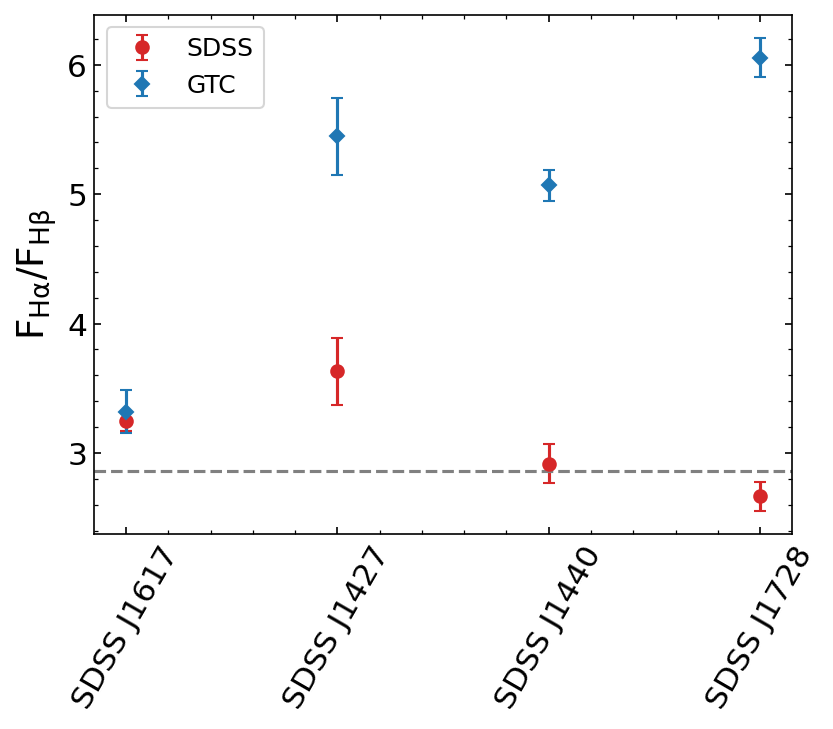

In [411]:
fig = plt.figure(figsize = (6,4.5), dpi = 150)


fs = 16
ax  = plt.subplot(111)

# ax.set_xlabel(r"${\rm  Target}$", fontsize=15)
ax.set_ylabel(r"${\rm F_{\rm H\alpha}/F_{\rm H\beta} }$", fontsize=18)
# ax.set_title(target_name, fontsize=15)
names = np.array(["SDSS J1617", "SDSS J1427", "SDSS J1440", "SDSS J1728"])
plt.xticks(rotation=60)
ax.errorbar(names, sdss_ha2hb, yerr = sdss_ha2hb_err, 
            color = 'C3',linestyle="None", marker="o", elinewidth=1.5,ms=6,capsize=3,
            label = "SDSS")

ax.errorbar(names, gtc_ha2hb, yerr = gtc_ha2hb_err, 
            color = 'C0',linestyle="None", marker="D", elinewidth=1.5,ms=5,capsize=3,
            label = "GTC")

plt.axhline(y=2.86,color='gray',linestyle='--')
plt.legend(fontsize = 12,markerscale = 1)

# plt.savefig('image/Ha2Hb.pdf',dpi=600,bbox_inches='tight')

## fit results

In [126]:
tar_info = ascii.read("data/target_info.dat")
tar_name = tar_info["Object"]
redshift = tar_info["z"]

lowz_mask  = redshift < 0.7
medz_mask  = (0.7 < redshift) & (redshift < 1.9)
highz_mask = redshift >1.9

lz_tar = tar_name[lowz_mask]
mz_tar = tar_name[medz_mask]
hz_tar = tar_name[highz_mask]

line_name = ["Hb_whole_br_", "MgII_whole_br_", "CIV_whole_br_", ]
phy_prop = ["fwhm", "ew",  "area", "fwhm_err", "ew_err",  "area_err", ]
lumi_conti = ["L1350", "L3000", "L5100", "L1350_err", "L3000_err", "L5100_err",]

gtc_result_path = "data/fit_results/gtc_osiris/"
sdss_result_path = "data/fit_results/sdss_dr9/"

In [ ]:
# ###  SDSS prop
# tar_name = tar_name[1:]
# data_sdss = Table()
# data_sdss["Obj"] = tar_name
# for luname in lumi_conti:
#     data_sdss[luname] = np.zeros(len(tar_name))
# for lname in line_name:
#         for phyp in phy_prop:
#             data_sdss[lname+phyp] = np.zeros(len(tar_name))
            
# for i in range(len(tar_name)):
    
#     fits_file = fits.open(glob.glob(sdss_result_path+"*"+tar_name[i]+"*.fits")[0])

#     for luname in lumi_conti:
#         data_sdss[luname][i] = fits_file[1].data[luname]
            
#     for lname in line_name:
#         for phyp in phy_prop:
#             try:
#                 data_sdss[lname+phyp][i] = fits_file[1].data[lname+phyp]
#             except:
#                 data_sdss[lname+phyp][i] = 0.0

# ascii.write(data_sdss, 'data/SDSS_datatable.csv')

In [ ]:
##  GTC prop
# data_gtc = Table()
# data_gtc["Obj"] = tar_name
# for luname in lumi_conti:
#     data_gtc[luname] = np.zeros(len(tar_name))
# for lname in line_name:
#         for phyp in phy_prop:
#             data_gtc[lname+phyp] = np.zeros(len(tar_name))
            
# for i in range(len(tar_name)):
#     if tar_name[i] == "J1607":
#         fits_file = fits.open(glob.glob(gtc_result_path+"*"+tar_name[i]+"*Mg2Hb.fits")[0])
#     else:
#         fits_file = fits.open(glob.glob(gtc_result_path+"*"+tar_name[i]+"*Fc*.fits")[0])
    
#     for luname in lumi_conti:
#             data_gtc[luname][i] = fits_file[1].data[luname]
            
#     for lname in line_name:
#         for phyp in phy_prop:
#             try:
#                 data_gtc[lname+phyp][i] = fits_file[1].data[lname+phyp]
#             except:
#                 data_gtc[lname+phyp][i] = 0.0

# ascii.write(data_gtc, 'data/GTC_fc_datatable.csv')

## BH properties


In [392]:
tar_info = ascii.read("data/target_info.dat")
tar_name = tar_info["Object"]
redshift = tar_info["z"]


data_gtc = ascii.read("data/GTC_datatable.csv")
data_sdss = ascii.read("data/SDSS_datatable.csv")

SDSS

In [393]:
Lb_1350 = 10**data_sdss["L1350"]
Lb_1350_err = np.log(10)*Lb_1350*data_sdss["L1350_err"]
Lb_3000 = 10**data_sdss["L3000"]
Lb_3000_err = np.log(10)*Lb_3000*data_sdss["L3000_err"]
Lb_5100 = 10**data_sdss["L5100"]
Lb_5100_err = np.log(10)*Lb_5100*data_sdss["L5100_err"]

L_Mgii, L_Mgii_err = fluxToLuminosity(data_sdss["MgII_whole_br_area"], data_sdss["MgII_whole_br_area_err"], redshift)
L_Hb, L_Hb_err     = fluxToLuminosity(data_sdss["Hb_whole_br_area"], data_sdss["Hb_whole_br_area_err"], redshift)
L_Civ, L_Civ_err   = fluxToLuminosity(data_sdss["CIV_whole_br_area"], data_sdss["CIV_whole_br_area_err"], redshift)

Mvir_Mgii, Mvir_Mgii_err = virBhMass(Lb_3000, Lb_3000_err, 
                                     data_sdss["MgII_whole_br_fwhm"], data_sdss["MgII_whole_br_fwhm_err"], method="MgII")
Mvir_Hb, Mvir_Hb_err     = virBhMass(Lb_5100, Lb_5100_err, 
                                     data_sdss["Hb_whole_br_fwhm"], data_sdss["Hb_whole_br_fwhm_err"], method="Hb", )
Mvir_Civ, Mvir_Civ_err   = virBhMass(Lb_1350, Lb_1350_err, 
                                     data_sdss["CIV_whole_br_fwhm"], data_sdss["CIV_whole_br_fwhm_err"], method="CIV", )

SDSS_Lbol = np.zeros(len(tar_name))
SDSS_Lbol_err = np.zeros(len(tar_name))
SDSS_Mbh = np.zeros(len(tar_name))
SDSS_Mbh_err = np.zeros(len(tar_name))

for i in range(len(redshift)):
    if redshift[i] < 0.7:
        SDSS_Lbol[i] = np.log10(9.26*Lb_5100[i])
        SDSS_Lbol_err[i] = data_sdss["L5100_err"][i]
        SDSS_Mbh[i] = Mvir_Hb[i]
        SDSS_Mbh_err[i] = Mvir_Hb_err[i]
    elif redshift[i] > 1.9:
        SDSS_Lbol[i] = np.log10(3.81*Lb_1350[i])
        SDSS_Lbol_err[i] = data_sdss["L1350_err"][i]
        SDSS_Mbh[i] = Mvir_Civ[i]
        SDSS_Mbh_err[i] = Mvir_Civ_err[i]
    else:
        SDSS_Lbol[i] = np.log10(5.15*Lb_3000[i])
        SDSS_Lbol_err[i] = data_sdss["L3000_err"][i]
        SDSS_Mbh[i] = Mvir_Mgii[i]
        SDSS_Mbh_err[i] = Mvir_Mgii_err[i]
        
SDSS_Lbol[-1] = np.log10(9.26*Lb_5100[-1])
SDSS_Lbol_err[-1] = data_sdss["L5100_err"][-1]
SDSS_Mbh[-1] = Mvir_Hb[-1]
SDSS_Mbh_err[-1] = Mvir_Hb_err[-1]

In [394]:
logL_edd = np.log10(1.26) + 38 + SDSS_Mbh
logL_edd_err = SDSS_Mbh_err
SDSS_logR_edd = SDSS_Lbol - logL_edd
SDSS_logR_edd_err = np.sqrt(SDSS_Lbol_err**2 + logL_edd_err**2)
SDSS_R_edd = 10**(SDSS_logR_edd)
SDSS_R_edd_err = SDSS_R_edd*np.log(10)*SDSS_logR_edd_err

GTC

In [395]:
Lb_1350 = 10**data_gtc["L1350"]
Lb_1350_err = np.log(10)*Lb_1350*data_gtc["L1350_err"]
Lb_3000 = 10**data_gtc["L3000"]
Lb_3000_err = np.log(10)*Lb_1350*data_gtc["L3000_err"]
Lb_5100 = 10**data_gtc["L5100"]
Lb_5100_err = np.log(10)*Lb_1350*data_gtc["L5100_err"]

L_Mgii, L_Mgii_err = fluxToLuminosity(data_gtc["MgII_whole_br_area"], data_gtc["MgII_whole_br_area_err"], redshift)
L_Hb, L_Hb_err     = fluxToLuminosity(data_gtc["Hb_whole_br_area"], data_gtc["Hb_whole_br_area_err"], redshift)
L_Civ, L_Civ_err   = fluxToLuminosity(data_gtc["CIV_whole_br_area"], data_gtc["CIV_whole_br_area_err"], redshift)

Mvir_Mgii, Mvir_Mgii_err = virBhMass(Lb_3000, Lb_3000_err, 
                                     data_gtc["MgII_whole_br_fwhm"], data_gtc["MgII_whole_br_fwhm_err"], method="MgII")
Mvir_Hb, Mvir_Hb_err     = virBhMass(Lb_5100, Lb_5100_err, 
                                     data_gtc["Hb_whole_br_fwhm"], data_gtc["Hb_whole_br_fwhm_err"], method="Hb", )
Mvir_Civ, Mvir_Civ_err   = virBhMass(Lb_1350, Lb_1350_err, 
                                     data_gtc["CIV_whole_br_fwhm"], data_gtc["CIV_whole_br_fwhm_err"], method="CIV", )

GTC_Lbol = np.zeros(len(tar_name))
GTC_Lbol_err = np.zeros(len(tar_name))
GTC_Mbh = np.zeros(len(tar_name))
GTC_Mbh_err = np.zeros(len(tar_name))

for i in range(len(redshift)):
    if redshift[i] < 0.7:
        GTC_Lbol[i] = np.log10(9.26*Lb_5100[i])
        GTC_Lbol_err[i] = data_gtc["L5100_err"][i]
        GTC_Mbh[i] = Mvir_Hb[i]
        GTC_Mbh_err[i] = Mvir_Hb_err[i]
    elif redshift[i] > 1.9:
        GTC_Lbol[i] = np.log10(3.81*Lb_1350[i])
        GTC_Lbol_err[i] = data_gtc["L1350_err"][i]
        GTC_Mbh[i] = Mvir_Civ[i]
        GTC_Mbh_err[i] = Mvir_Civ_err[i]
    else:
        GTC_Lbol[i] = np.log10(5.15*Lb_3000[i])
        GTC_Lbol_err[i] = data_gtc["L3000_err"][i]
        GTC_Mbh[i] = Mvir_Mgii[i]
        GTC_Mbh_err[i] = Mvir_Mgii_err[i]

In [396]:
GTC_logL_edd = np.log10(1.26) + 38 + GTC_Mbh
GTC_logL_edd_err = GTC_Mbh_err
GTC_logR_edd = GTC_Lbol - GTC_logL_edd
GTC_logR_edd_err = np.sqrt(GTC_Lbol_err**2 + GTC_logL_edd_err**2)
GTC_R_edd = 10**(GTC_logR_edd)
GTC_R_edd_err = GTC_logR_edd*np.log(10)*GTC_logR_edd_err

In [397]:
GTC_lbol_dist = {tar_name[i]:GTC_Lbol[i] for i in range(len(GTC_Lbol))}
GTC_lbolerr_dist = {tar_name[i]:GTC_Lbol_err[i] for i in range(len(GTC_Lbol_err))}

### BH mass 

(7.0, 10.0)

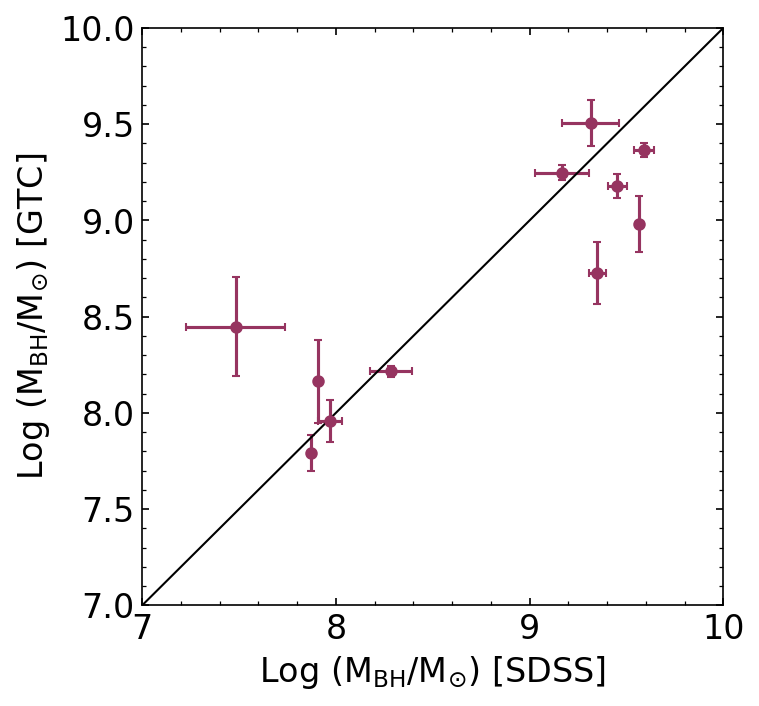

In [399]:
fig = plt.figure(figsize = (5,5), dpi = 150)

ax  = plt.subplot(111)
ax.set_xlabel(r"${\rm Log\ (M_{BH}/M_{\odot})\ [SDSS]}$", fontsize=16)
ax.set_ylabel(r"${\rm Log\ (M_{BH}/M_{\odot})\ [GTC] }$", fontsize=16)
# ax.set_title(target_name, fontsize=15)
# plt.xticks(rotation=60)

ax.errorbar(x=SDSS_Mbh, xerr = SDSS_Mbh_err, y=GTC_Mbh, yerr = GTC_Mbh_err, 
            color = xmcl["C6"],linestyle="None", marker="o", elinewidth=1.5,ms=5,capsize=2,)
xx = np.arange(7.0,10.0,0.001)
yy = xx
plt.plot(xx,yy,'k',lw=1)

plt.ylim(7, 10)
plt.xlim(7, 10)

# plt.savefig('image/BH_mass_2epoch.pdf',dpi=600,bbox_inches='tight')

In [400]:
bhm = np.log10(0.5* (10**(SDSS_Mbh) + 10**(GTC_Mbh)))
Mbh_err = np.sqrt(SDSS_Mbh_err**2 + GTC_Mbh_err**2)

In [401]:
np.around(bhm, 2), np.around(Mbh_err, 2)

(array([7.96, 9.42, 8.05, 8.25, 9.14, 9.34, 9.21, 9.49, 8.19, 7.83, 9.36]),
 array([0.13, 0.19, 0.22, 0.11, 0.17, 0.08, 0.14, 0.06, 0.36, 0.09, 0.15]))

### Eddingto ratio

In [402]:
Mbh = 0.5*(SDSS_Mbh+GTC_Mbh)
Mbh_err = np.sqrt(SDSS_Mbh_err**2 + GTC_Mbh_err**2)
logL_edd = np.log10(1.26) + 38 + Mbh
logL_edd_err = Mbh_err

GTC_logR_edd = GTC_Lbol - logL_edd
GTC_logR_edd_err = np.sqrt(GTC_Lbol_err**2 + logL_edd_err**2)
GTC_R_edd = 10**(GTC_logR_edd)
GTC_R_edd_err = GTC_logR_edd*np.log(10)*GTC_logR_edd_err

SDSS_logR_edd = SDSS_Lbol - logL_edd
SDSS_logR_edd_err = np.sqrt(SDSS_Lbol_err**2 + logL_edd_err**2)
SDSS_R_edd = 10**(SDSS_logR_edd)
SDSS_R_edd_err = SDSS_R_edd*np.log(10)*SDSS_logR_edd_err

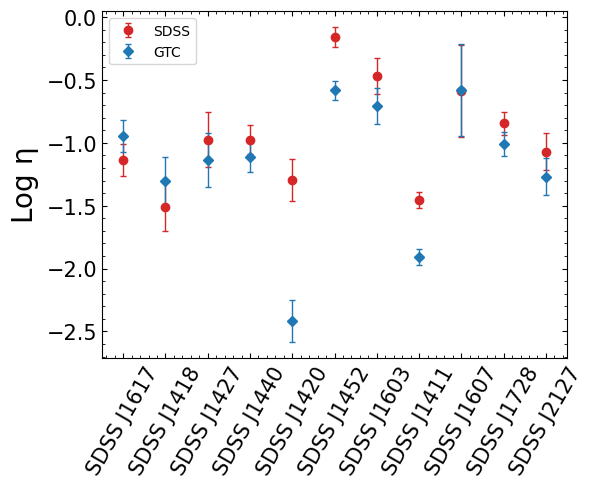

In [403]:
names = ["SDSS "+ i for i in tar_name]
fig = plt.figure(figsize = (6,4.5), dpi = 100)
plt.rcParams["xtick.labelsize"] = 15
plt.rcParams["ytick.labelsize"] = 15

ax  = plt.subplot(111)

# ax.set_xlabel(r"${\rm  Target}$", fontsize=15)
ax.set_ylabel(r"${\rm Log\ \eta }$", fontsize=20)
# ax.set_title(target_name, fontsize=15)
plt.xticks(rotation=60)

ax.errorbar(names, SDSS_logR_edd, yerr = SDSS_logR_edd_err, 
            color = 'C3',linestyle="None", marker="o", elinewidth=1,ms=6,capsize=2,
            label = "SDSS")

ax.errorbar(names, GTC_logR_edd, yerr = GTC_logR_edd_err, 
            color = 'C0',linestyle="None", marker="D", elinewidth=1,ms=5,capsize=2,
            label = "GTC")
plt.legend()

# plt.savefig('image/Eddington_ratio_var_FC.pdf',dpi=600,bbox_inches='tight')

## Dust reverberation

In [149]:
tl_dataz

target,W1r_tau,W1r_tau_uperr,W1r_tau_loerr,W2r_tau,W2r_tau_uperr,W2r_tau_loerr
str5,float64,float64,float64,float64,float64,float64
J1607,-402.0,250.3,242.4,-397.0,213.0,195.9
J1603,-313.0,935.5,524.6,-576.0,1010.0,279.4
J1411,-326.0,967.5,391.2,-408.0,989.2,322.4
J1427,-314.0,77.34,120.6,-409.0,128.2,95.33
J1418,-418.0,544.0,309.3,-481.0,653.5,279.4
J1420,-365.0,336.2,329.7,-421.0,335.6,295.3
J1440,-504.0,203.7,151.6,-504.0,216.9,240.4
J1728,-186.0,53.13,97.38,-189.0,235.7,140.3
J1617,-629.0,287.3,194.5,-523.0,774.3,290.0


In [29]:
pgqsos = pd.read_csv("data/PGqsos.txt", sep="	")
pgqso_Lagn = np.array(pgqsos["${L}_{\mathrm{AGN},\mathrm{bol}}$"])[1:]
pgqso_tw1  = np.array(pgqsos[r"${\rm{\Delta }}{t}_{W1,{\chi }^{2}}$"])[1:]
pgqso_tw2  = np.array(pgqsos[r"${\rm{\Delta }}{t}_{W2,{\chi }^{2}}$"])[1:]

pg_Lagn = np.asarray(pgqso_Lagn, dtype="float")
pg_tw1 = np.array([float(i.split('+',1)[0]) for i in pgqso_tw1])
pg_tw1_err = np.array([float(i.split('-',1)[1]) for i in pgqso_tw1])
pg_tw2 = np.array([float(i.split('+',1)[0]) for i in pgqso_tw2])
pg_tw2_err = np.array([float(i.split('-',1)[1]) for i in pgqso_tw2])

Log_pglagn = pg_Lagn-11
Log_pgtw1 = np.log10(pg_tw1)
Log_pgtw1_err = (pg_tw1_err/pg_tw1)/np.log(10)
Log_pgtw2 = np.log10(pg_tw2)
Log_pgtw2_err = (pg_tw2_err/pg_tw2)/np.log(10)

In [147]:
tl_data = ascii.read("data/time_lag_results.dat")   
tar_new = tl_data["target"]
GTC_lbol_dist = {tar_name[i]:GTC_Lbol[i] for i in range(len(GTC_Lbol))}
GTC_lbolerr_dist = {tar_name[i]:GTC_Lbol_err[i] for i in range(len(GTC_Lbol_err))}

In [31]:
L_AGN = np.zeros(11)
L_AGN_err = np.zeros(11)
for i in range(len(tar_new)):
    key = tar_new[i]
    L_AGN[i] = float(GTC_lbol_dist[key])
    L_AGN_err[i] = float(GTC_lbolerr_dist[key])

In [32]:
L_sun = 3.845*10**33      # erg/s
L_AGN_new = 10**(L_AGN)/(10**11 * L_sun)
L_AGN_err_new = np.sqrt((L_AGN_new*np.log(10)*L_AGN_err)**2)

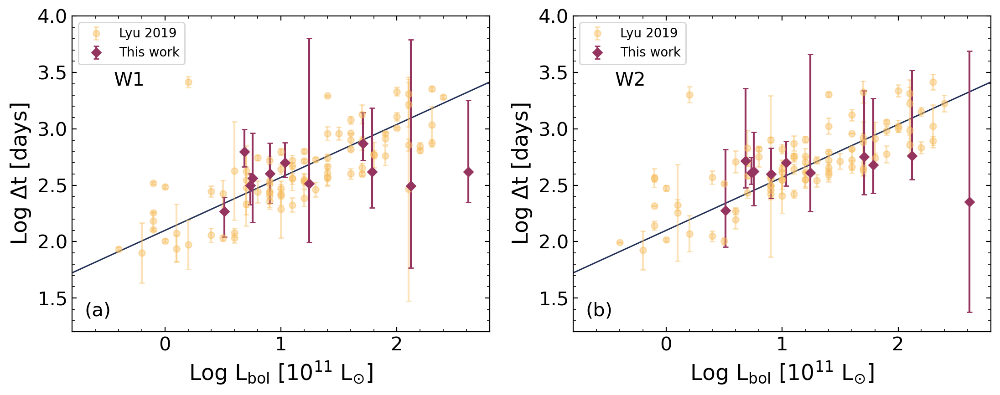

In [39]:
fig = plt.figure(figsize = (13, 4.5), dpi = 200)
plt.rcParams["xtick.labelsize"] = 15
plt.rcParams["ytick.labelsize"] = 15
ms = 5
logLagn = L_AGN-(np.log10(L_sun)+11)
logLagn_err =  L_AGN_err

######   W1
ax1  = plt.subplot(121)
ax1.set_xlabel(r"${\rm  Log\ L_{bol}\ [10^{11}\ L_{\odot}]}$", fontsize=17)
ax1.set_ylabel(r"${\rm Log\ \Delta t\ [days] }$", fontsize=17)
# ax1.set_xscale("log")
# ax1.set_title(target_name, fontsize=15)
ax1.set_xlim(-0.8,2.8)
ax1.set_ylim(1.2,4.0)

### Lyu 2019 realtion
L_sun = 3.845*10**33      # erg/s
logxx = (np.arange(42, 48, 0.01))-(np.log10(L_sun)+11)
logy_W1 = logxx * 0.47 + 2.10
logyW1_up = logxx * (0.47+0.06) + (2.10+0.06)
logyW1_lo = logxx * (0.47-0.06) + (2.10-0.06)
ax1.plot(logxx, logy_W1, xmcl["C0"], lw=1.1)

### this work 
color = xmcl["C8"]
marker = "D"
t_w1 = np.abs(tl_data["W1r_tau"])
t_w1_uperr = tl_data["W1r_tau_uperr"]
t_w1_loerr = tl_data["W1r_tau_loerr"]
logtw1 = np.log10(t_w1)
logtw1_ue = (t_w1_uperr/t_w1)/np.log(10)
logtw1_le = (t_w1_loerr/t_w1)/np.log(10)

ax1.errorbar(Log_pglagn, Log_pgtw1, yerr = Log_pgtw1_err,
             linestyle = "None", color=xmcl["C4"], marker="o", ms=ms, elinewidth=1.5,capsize=2,alpha = 0.45, label = "Lyu 2019")

ax1.errorbar(x=logLagn, y=logtw1, yerr=[logtw1_le, logtw1_ue], 
             linestyle = "None", color=xmcl["C6"], marker=marker, ms=ms, elinewidth=1.5,capsize=2, label = "This work")
ax1.text(0.1,0.78,'W1',transform=ax1.transAxes,fontdict={'size': '15', 'color': 'black'})
ax1.text(0.03,0.05,'(a)',transform=ax1.transAxes,fontdict={'size': '15', 'color': 'black'})

plt.legend()

######## W2
ax2  = plt.subplot(122)
ax2.set_xlabel(r"${\rm  Log\ L_{bol}\ [10^{11}\ L_{\odot}]}$", fontsize=17)
ax2.set_ylabel(r"${\rm Log\ \Delta t\ [days] }$", fontsize=17)
# ax2.set_title(target_name, fontsize=15)

ax2.set_xlim(-0.8,2.8)
ax2.set_ylim(1.2,4.0)

### Lyu 2019 realtion
L_sun = 3.845*10**33      # erg/s
logxx = (np.arange(42, 48, 0.01))-(np.log10(L_sun)+11)
logy_W2 = logxx * 0.45 + 2.20
ax2.plot(logxx, logy_W1, xmcl["C0"], lw=1.1)

### this work
marker = "D"
t_w2 = np.abs(tl_data["W2r_tau"])
t_w2_uperr = tl_data["W2r_tau_uperr"]
t_w2_loerr = tl_data["W2r_tau_loerr"]
logtw2 = np.log10(t_w2)
logtw2_ue = (t_w2_uperr/t_w2)/np.log(10)
logtw2_le = (t_w2_loerr/t_w2)/np.log(10)

ax2.errorbar(Log_pglagn, Log_pgtw2, yerr = Log_pgtw2_err,
             linestyle = "None", color=xmcl["C4"], marker="o", ms=ms, elinewidth=1.5,capsize=2,alpha = 0.45, label = "Lyu 2019")

ax2.errorbar(x=logLagn, y=logtw2,  yerr=[logtw2_le, logtw2_ue], 
             linestyle = "None", color=xmcl["C6"], marker=marker, ms=ms, elinewidth=1.5,capsize=2, label = "This work")
ax2.text(0.1,0.78,'W2',transform=ax2.transAxes,fontdict={'size': '15', 'color': 'black'})
ax2.text(0.03,0.05,'(b)',transform=ax2.transAxes,fontdict={'size': '15', 'color': 'black'})



plt.legend()
plt.savefig('image/timelag_vs_L_FC.pdf',dpi=600,bbox_inches='tight')

##  Baldwin Effect

In [150]:
SDSS_log_Lc = np.zeros(11)
SDSS_log_Lc_err = np.zeros(11)
SDSS_EW = np.zeros(11)
SDSS_EW_err = np.zeros(11)

GTC_log_Lc = np.zeros(11)
GTC_log_Lc_err = np.zeros(11)
GTC_EW = np.zeros(11)
GTC_EW_err = np.zeros(11)

for i in range(len(redshift)):
    if redshift[i] < 0.7:
        SDSS_log_Lc[i] = data_sdss["L5100"][i]
        SDSS_log_Lc_err[i] = data_sdss["L5100_err"][i]
        SDSS_EW[i] = data_sdss["Hb_whole_br_ew"][i]
        SDSS_EW_err[i] = data_sdss["Hb_whole_br_ew_err"][i]
        
        GTC_log_Lc[i] = data_gtc["L5100"][i]
        GTC_log_Lc_err[i] = data_gtc["L5100_err"][i]
        GTC_EW[i] = data_gtc["Hb_whole_br_ew"][i]
        GTC_EW_err[i] = data_gtc["Hb_whole_br_ew_err"][i]
    elif redshift[i] > 1.9:
        SDSS_log_Lc[i] = data_sdss["L1350"][i]
        SDSS_log_Lc_err[i] = data_sdss["L1350_err"][i]
        SDSS_EW[i] = data_sdss["CIV_whole_br_ew"][i]
        SDSS_EW_err[i] = data_sdss["CIV_whole_br_ew_err"][i]
        
        GTC_log_Lc[i] = data_gtc["L1350"][i]
        GTC_log_Lc_err[i] = data_gtc["L1350_err"][i]
        GTC_EW[i] = data_gtc["CIV_whole_br_ew"][i]
        GTC_EW_err[i] = data_gtc["CIV_whole_br_ew_err"][i]
    else:
        SDSS_log_Lc[i] = data_sdss["L3000"][i]
        SDSS_log_Lc_err[i] = data_sdss["L3000_err"][i]
        SDSS_EW[i] = data_sdss["MgII_whole_br_ew"][i]
        SDSS_EW_err[i] = data_sdss["MgII_whole_br_ew_err"][i]
        
        GTC_log_Lc[i] = data_gtc["L3000"][i]
        GTC_log_Lc_err[i] = data_gtc["L3000_err"][i]
        GTC_EW[i] = data_gtc["MgII_whole_br_ew"][i]
        GTC_EW_err[i] = data_gtc["MgII_whole_br_ew_err"][i]
             

In [151]:
SDSS_log_Lc[-1] = data_sdss["L5100"][-1]
SDSS_log_Lc_err[-1] = data_sdss["L5100_err"][-1]
SDSS_EW[-1] = data_sdss["Hb_whole_br_ew"][-1]
SDSS_EW_err[-1] = data_sdss["Hb_whole_br_ew_err"][-1]

GTC_log_Lc[-1] = data_gtc["L5100"][-1]
GTC_log_Lc_err[-1] = data_gtc["L5100_err"][-1]
GTC_EW[-1] = data_gtc["Hb_whole_br_ew"][-1]
GTC_EW_err[-1] = data_gtc["Hb_whole_br_ew_err"][-1]

In [152]:
SDSS_log_ew = np.log10(SDSS_EW)
SDSS_log_ew_err = SDSS_EW_err/SDSS_EW/np.log(10)
GTC_log_ew = np.log10(GTC_EW)
GTC_log_ew_err = GTC_EW_err/GTC_EW/np.log(10)

In [567]:
dLc = SDSS_log_Lc - GTC_log_Lc
dLc_err = np.sqrt(SDSS_log_Lc_err**2+GTC_log_Lc_err**2)

deqw = SDSS_log_ew - GTC_log_ew
deqw_err = np.sqrt(SDSS_log_ew_err**2+GTC_log_ew_err**2)

In [568]:
SDSS_log_Lc[0],GTC_log_Lc[0]

(43.96232661932186, 44.3025114412091)

In [569]:
## baldwin effect slope of 3 emline, from Xiao et al. 2022;
## https://ui.adsabs.harvard.edu/abs/2022ApJ...936..146X/abstract
bde_k_Civ = -0.25
b_Civ = 13.26
bde_k_Mgii = -0.24
b_Mgii = 12.74
bde_k_Hb = -0.08
b_hb = 5.23

## 
br_line = np.array(['hb', 'mg', 'hb', 'hb', 'mg', 'c', 'mg', 'mg', 'hb', 'hb', 'hb'])

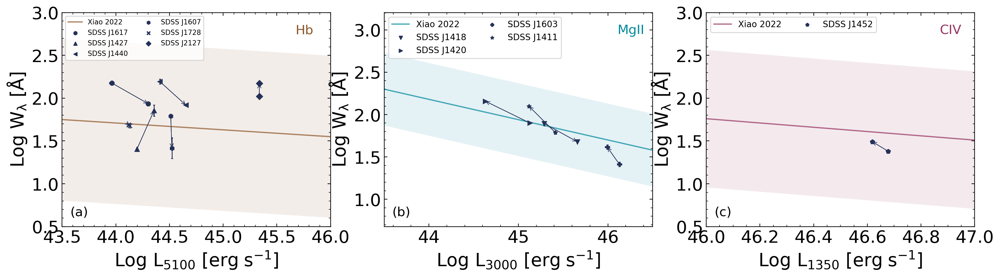

In [578]:
fig = plt.figure(figsize = (19,4.5), dpi = 200)

ms = 5

#####
fake_Lcon = np.arange(42,48,0.01)
ew_hb  = bde_k_Hb* fake_Lcon + b_hb
ew_Mg  = bde_k_Mgii* fake_Lcon  + b_Mgii
ew_Civ = bde_k_Civ* fake_Lcon + b_Civ
Hb_c = xmcl['C8']
Mg_c = xmcl['C9']
C_c = xmcl['C6']

ax1  = plt.subplot(131)
ax1.set_xlim(43.5, 46)
ax1.set_ylim(0.5, 3.0)
ax1.set_xlabel(r"${\rm  Log\ L_{5100}\ [erg\;s^{-1}]}$", fontsize=21)
ax1.set_ylabel(r"${\rm  Log\ W_{\lambda}\ [\AA] }$", fontsize=21)

ax1.plot(fake_Lcon,ew_hb,  color=Hb_c, ls='-', lw=1.5, alpha=0.7, label = "Xiao 2022")
ax1.text(0.87,0.90,'Hb',transform=ax1.transAxes,fontdict={'size': '15', 'color':Hb_c})
ax1.fill_between(fake_Lcon, ew_hb + 2.84/3, ew_hb - 2.84/3,\
             color=Hb_c, alpha=0.1, edgecolors='none')
ax1.text(0.03,0.05,'(a)',transform=ax1.transAxes,fontdict={'size': '15', 'color': 'black'})

# ax1.axhline(y=3, xmin=0.045, xmax=0.96, color=xmcl['C1'], ls="--", lw=1, alpha=0.7)
# ax1.text(0.84,0.57,'attenuation',transform=ax1.transAxes,fontdict={'size': '15', 'color': xmcl['C1']})


ax2  = plt.subplot(132)
ax2.set_xlim(43.5, 46.5)
ax2.set_xlabel(r"${\rm  Log\ L_{3000}\ [erg\;s^{-1}]}$", fontsize=21)
ax2.set_ylabel(r"${\rm  Log\ W_{\lambda}\ [\AA] }$", fontsize=21)

ax2.plot(fake_Lcon,ew_Mg,  color=Mg_c, ls='-',  lw=1.5, alpha=0.7, label = "Xiao 2022")
ax2.text(0.87,0.90,'MgII',transform=ax2.transAxes,fontdict={'size': '15', 'color':Mg_c})
ax2.fill_between(fake_Lcon, ew_Mg + 1.29/3, ew_Mg - 1.29/3,\
             color=Mg_c, alpha=0.1, edgecolors='none')

ax2.text(0.03,0.05,'(b)',transform=ax2.transAxes,fontdict={'size': '15', 'color': 'black'})

# ax2.axhline(y=3, xmin=0.045, xmax=0.96, color=xmcl['C1'], ls="--", lw=1, alpha=0.7)
# ax2.text(0.84,0.57,'attenuation',transform=ax2.transAxes,fontdict={'size': '15', 'color': xmcl['C1']})

ax3  = plt.subplot(133)
ax3.set_xlim(46, 47)
ax3.set_ylim(0.5, 3.0)
ax3.set_xlabel(r"${\rm  Log\ L_{1350}\ [erg\;s^{-1}]}$", fontsize=21)
ax3.set_ylabel(r"${\rm  Log\ W_{\lambda}\ [\AA] }$", fontsize=21)


ax3.plot(fake_Lcon,ew_Civ, color=C_c, ls='-', lw=1.5, alpha=0.7, label = "Xiao 2022")
ax3.text(0.87,0.90,'CIV',transform=ax3.transAxes,fontdict={'size': '15', 'color':C_c})
ax3.fill_between(fake_Lcon, ew_Civ + 2.41/3, ew_Civ - 2.41/3,\
             color=C_c, alpha=0.1, edgecolors='none')

ax3.text(0.03,0.05,'(c)',transform=ax3.transAxes,fontdict={'size': '15', 'color': 'black'})

# ax3.axhline(y=3, xmin=0.045, xmax=0.96, color=xmcl['C1'], ls="--", lw=1, alpha=0.7)
# ax3.text(0.84,0.57,'attenuation',transform=ax3.transAxes,fontdict={'size': '15', 'color': xmcl['C1']})

for i in range(len(br_line)):

    x_sdss = SDSS_log_Lc[i]
    x_sdss_err = SDSS_log_Lc_err[i]
    y_sdss = SDSS_log_ew[i]
    y_sdss_err = SDSS_log_ew_err[i]
    x_gtc  = GTC_log_Lc[i]
    x_gtc_err = GTC_log_Lc_err[i]
    y_gtc  = GTC_log_ew[i]
    y_gtc_err = GTC_log_ew_err[i]
    
    lb_name = 'SDSS '+data_sdss["Obj"][i]
    Hb_c = xmcl['C8']
    Mg_c = xmcl['C9']
    C_c = xmcl['C6']
    marker = ['o', 'v', '^', '<', '>', 'p', 'P', '*', 'h', 'x', 'D']
    
    if br_line[i] == "hb":
        color = Hb_c     
        ax1.scatter(x_sdss,y_sdss,color=xmcl['C0'], marker=marker[i], label= lb_name, s=15)
        ax1.errorbar([x_sdss, x_gtc], [y_sdss, y_gtc], 
                    xerr = [x_sdss_err, x_gtc_err], yerr = [y_sdss_err, y_gtc_err],
                    color=xmcl['C0'], ls='-',lw=0.7, 
                    marker=marker[i], ms=ms, elinewidth=1,capsize=1)
        ax1.annotate("", xytext=(x_sdss, y_sdss), xy=(x_gtc,y_gtc),
                arrowprops=dict(arrowstyle="->", shrinkB=0.50, color=xmcl['C0'],lw=0.7))
        ax1.legend(fontsize = 8, ncol=2, loc='upper left')
    
    elif br_line[i] == "mg":
        color = Mg_c
        ax2.scatter(x_sdss,y_sdss,color=xmcl['C0'], marker=marker[i], label= lb_name, s=15)
        ax2.errorbar([x_sdss, x_gtc], [y_sdss, y_gtc], 
                    xerr = [x_sdss_err, x_gtc_err], yerr = [y_sdss_err, y_gtc_err],
                    color=xmcl['C0'], ls='-',lw=0.7, 
                    marker=marker[i], ms=ms, elinewidth=1,capsize=1)
        ax2.annotate("", xytext=(x_sdss, y_sdss), xy=(x_gtc,y_gtc),
                arrowprops=dict(arrowstyle="->", shrinkB=0.50, color=xmcl['C0'],lw=0.7))
        ax2.legend(fontsize = 10, ncol=2, loc='upper left')

    else: 
        color = C_c
        ax3.scatter(x_sdss,y_sdss,color=xmcl['C0'], marker=marker[i], label= lb_name, s=15)
        ax3.errorbar([x_sdss, x_gtc], [y_sdss, y_gtc], 
                    xerr = [x_sdss_err, x_gtc_err], yerr = [y_sdss_err, y_gtc_err],
                    color=xmcl['C0'], ls='-',lw=0.7,
                    marker=marker[i], ms=ms, elinewidth=1,capsize=1)
        ax3.annotate("", xytext=(x_sdss, y_sdss), xy=(x_gtc,y_gtc),
                arrowprops=dict(arrowstyle="->", shrinkB=0.50, color=xmcl['C0'],lw=0.7))
        
        ax3.legend(fontsize = 10, ncol=2, loc='upper left')
    

plt.savefig('image/Baldwin_effect_FC.pdf',dpi=600,bbox_inches='tight')

<ErrorbarContainer object of 3 artists>

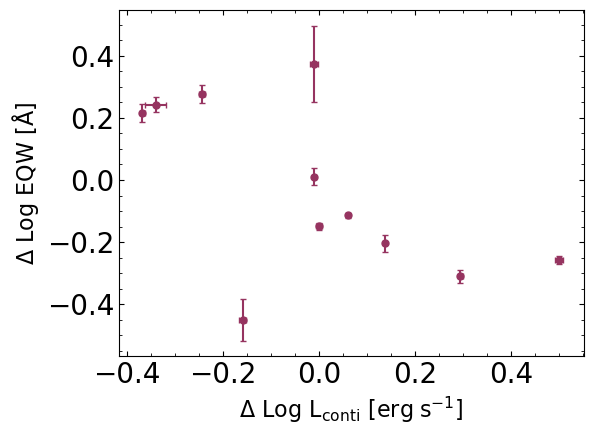

In [571]:
fig = plt.figure(figsize = (6,4.5), dpi = 100)

ax  = plt.subplot(111)
ax.set_xlabel(r"${\rm \Delta\ Log\ L_{conti}\ [erg\;s^{-1}]}$", fontsize=16)
ax.set_ylabel(r"${\rm \Delta\ Log\ EQW\ [\AA] }$", fontsize=16)

ax.errorbar(dLc, deqw, xerr = dLc_err, yerr = deqw_err,
             linestyle = "None", color=xmcl["C6"], marker="o", ms=ms, elinewidth=1.5,capsize=2)

## BEL flux 

In [110]:
SDSS_BLF = np.zeros(11)
SDSS_BLF_err = np.zeros(11)

GTC_BLF = np.zeros(11)
GTC_BLF_err = np.zeros(11)

for i in range(len(redshift)):
    if redshift[i] < 0.7:
        SDSS_BLF[i] = data_sdss["Hb_whole_br_area"][i]
        SDSS_BLF_err[i] = data_sdss["Hb_whole_br_area_err"][i]
        
        GTC_BLF[i] = data_gtc["Hb_whole_br_area"][i]
        GTC_BLF_err[i] = data_gtc["Hb_whole_br_area_err"][i]
    elif redshift[i] > 1.9:
        SDSS_BLF[i] = data_sdss["CIV_whole_br_area"][i]
        SDSS_BLF_err[i] = data_sdss["CIV_whole_br_area_err"][i]
        
        GTC_BLF[i] = data_gtc["CIV_whole_br_area"][i]
        GTC_BLF_err[i] = data_gtc["CIV_whole_br_area_err"][i]
    else:
        SDSS_BLF[i] = data_sdss["MgII_whole_br_area"][i]
        SDSS_BLF_err[i] = data_sdss["MgII_whole_br_area_err"][i]
        
        GTC_BLF[i] = data_gtc["MgII_whole_br_area"][i]
        GTC_BLF_err[i] = data_gtc["MgII_whole_br_area_err"][i]
             

In [ ]:
SDSS_Lbol, GTC_Lbol

In [124]:
dLbol_abs = SDSS_Lbol-GTC_Lbol
dLbol_err = np.sqrt(SDSS_Lbol_err**2 + GTC_Lbol_err**2)

dBEL_flux_abs = np.log10(SDSS_BLF)-np.log10(GTC_BLF)

dBEL_flux_err = np.sqrt((GTC_BLF_err/GTC_BLF/np.log(10))**2 + (SDSS_BLF_err/SDSS_BLF/np.log(10))**2)

<ErrorbarContainer object of 3 artists>

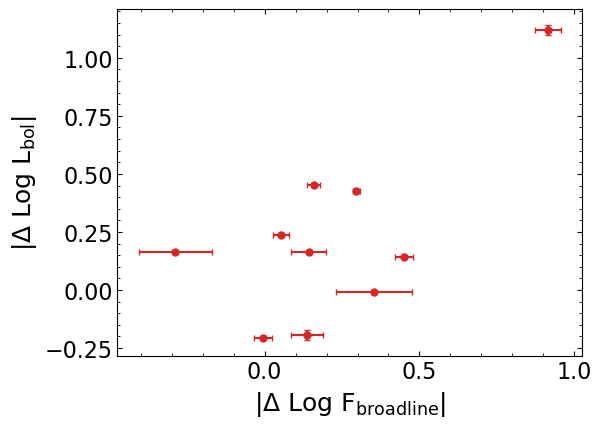

In [172]:
fig = plt.figure(figsize = (6,4.5), dpi = 100)

ax  = plt.subplot(111)
ax.set_xlabel(r"${\rm |\Delta\ Log\ F_{broad line}|}$", fontsize=18)
ax.set_ylabel(r"${\rm |\Delta\ Log\ L_{bol}|}$", fontsize=18)

ax.errorbar(dBEL_flux_abs, dLbol_abs, xerr = dBEL_flux_err, yerr = dLbol_err,
             linestyle = "None", color="C3", marker="o", ms=ms, elinewidth=1.5,capsize=2)

In [122]:
SDSS_Lbol_err

array([0.02200227, 0.00497367, 0.00670642, 0.00585568, 0.00564598,
       0.00157504, 0.00226246, 0.00451065, 0.00676543, 0.00283604,
       0.00625861])

In [177]:
2.5 * 1.3 * np.log10(6/2.7)

1.1270593302301328

In [ ]:
0.6, 0.8, 1.1

## SDSS J1452

In [523]:
fits_sdss = fits.open("data/fit_results/sdss_dr9/SDSS_J1452_fit_results.fits")
frs_gtc = fits.open("data/fit_results/gtc_osiris/SDSS_J1452_fit_results_ntl.fits")

In [622]:
fits_sdss[1].data["L1350"]

array([46.6777952])

In [623]:
frs_gtc[1].data["L1350"]

array([46.25312088])

In [532]:
line_key = ["Lya", "SiIV", "CIV", "CIII"]

In [605]:
sdss_flux = np.array([fits_sdss[1].data[line+"_whole_br_area"][0] for line in line_key])
sdss_flux_err = np.array([fits_sdss[1].data[line+"_whole_br_area_err"][0] for line in line_key])
sdss_fwhm = np.array([fits_sdss[1].data[line+"_whole_br_fwhm"][0] for line in line_key])
sdss_fwhm_err = np.array([fits_sdss[1].data[line+"_whole_br_fwhm_err"][0] for line in line_key])
sdss_ew = np.array([fits_sdss[1].data[line+"_whole_br_ew"][0] for line in line_key])
sdss_ew_err = np.array([fits_sdss[1].data[line+"_whole_br_ew_err"][0] for line in line_key])

gtc_flux = np.array([frs_gtc[1].data[line+"_whole_br_area"][0] for line in line_key])
gtc_flux_err = np.array([frs_gtc[1].data[line+"_whole_br_area_err"][0] for line in line_key])
gtc_fwhm = np.array([frs_gtc[1].data[line+"_whole_br_fwhm"][0] for line in line_key])
gtc_fwhm_err = np.array([frs_gtc[1].data[line+"_whole_br_fwhm_err"][0] for line in line_key])
gtc_ew = np.array([frs_gtc[1].data[line+"_whole_br_ew"][0] for line in line_key])
gtc_ew_err = np.array([frs_gtc[1].data[line+"_whole_br_ew_err"][0] for line in line_key])

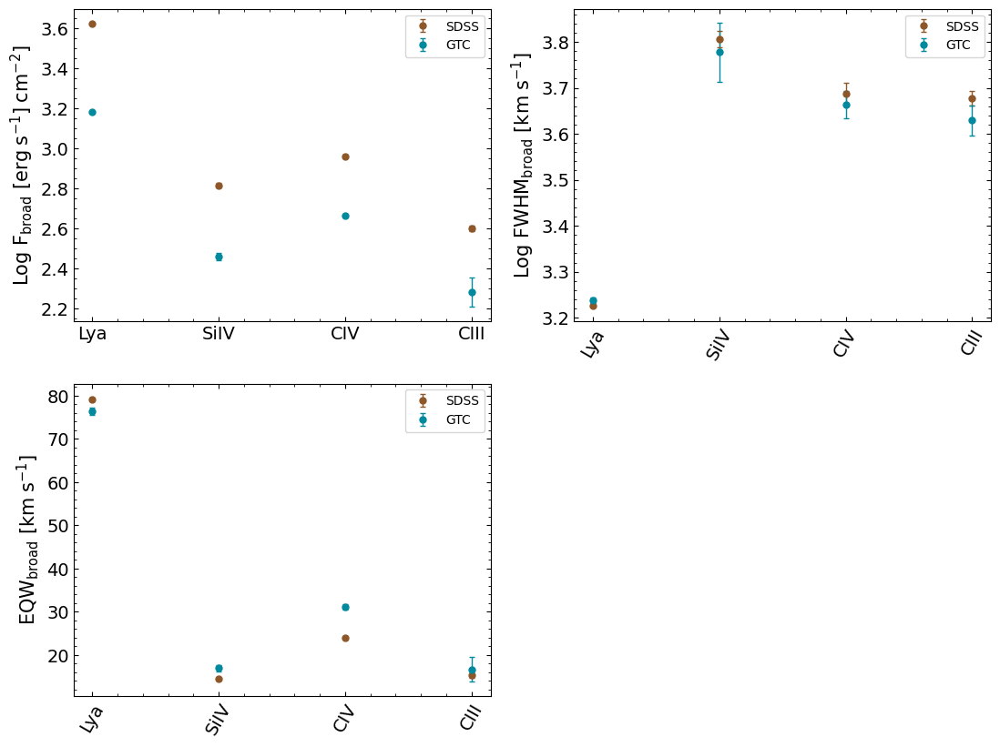

In [684]:
fig = plt.figure(figsize = (13, 10), dpi = 100)

ax = plt.subplot(221)
ax.set_ylabel(r"${\rm Log\ F_{\rm broad}\ [erg\;s^{-1}]\;cm^{-2}]}$", fontsize=15)
# ax.set_title(target_name, fontsize=15)
# plt.xticks(rotation=60)


ax.errorbar(line_key, np.log10(sdss_flux), yerr = (sdss_flux_err/sdss_flux)/np.log(10), 
            color = xmcl["C8"],linestyle="None", marker="o", elinewidth=1,ms=5,capsize=2,
            label = "SDSS")

ax.errorbar(line_key, np.log10(gtc_flux), yerr = (gtc_flux_err/gtc_flux)/np.log(10), 
            color = xmcl["C9"],linestyle="None", marker="o", elinewidth=1,ms=5,capsize=2,
            label = "GTC")
plt.legend()

ax1 = plt.subplot(222)
ax1.set_ylabel(r"${\rm Log\ FWHM_{\rm broad}\ [km\;s^{-1}] }$", fontsize=15)
# ax.set_title(target_name, fontsize=15)
plt.xticks(rotation=60)


ax1.errorbar(line_key, np.log10(sdss_fwhm), yerr = (sdss_fwhm_err/sdss_fwhm)/np.log(10), 
            color = xmcl["C8"],linestyle="None", marker="o", elinewidth=1,ms=5,capsize=2,
            label = "SDSS")

ax1.errorbar(line_key, np.log10(gtc_fwhm), yerr = (gtc_fwhm_err/gtc_fwhm)/np.log(10), 
            color = xmcl["C9"],linestyle="None", marker="o", elinewidth=1,ms=5,capsize=2,
            label = "GTC")
plt.legend()


ax1 = plt.subplot(223)
ax1.set_ylabel(r"${\rm EQW_{\rm broad}\ [km\;s^{-1}] }$", fontsize=15)
# ax.set_title(target_name, fontsize=15)
plt.xticks(rotation=60)


ax1.errorbar(line_key, sdss_ew, yerr = sdss_ew_err, 
            color = xmcl["C8"],linestyle="None", marker="o", elinewidth=1,ms=5,capsize=2,
            label = "SDSS")

ax1.errorbar(line_key, gtc_ew, yerr = gtc_ew_err, 
            color = xmcl["C9"],linestyle="None", marker="o", elinewidth=1,ms=5,capsize=2,
            label = "GTC")
plt.legend()

## SDSS J1427

### light curve 


In [27]:
## load data optical

## ZTF

lc_df_1427 = ascii.read("data/lc/J1427_lcData.dat")

### r band
t_1427 = lc_df_1427["MJD"][lc_df_1427["band"] == 'r']
mag_1427 = lc_df_1427["mag"][lc_df_1427["band"] == 'r']
mag_1427_err = lc_df_1427["magerr"][lc_df_1427["band"] == 'r']

### g band
t_1427_g = lc_df_1427["MJD"][lc_df_1427["band"] == 'g']
gmag_1427 = lc_df_1427["mag"][lc_df_1427["band"] == 'g']
gmag_1427_err = lc_df_1427["magerr"][lc_df_1427["band"] == 'g']

### i band 
t_1427_i = lc_df_1427["MJD"][lc_df_1427["band"] == 'i']
imag_1427 = lc_df_1427["mag"][lc_df_1427["band"] == 'i']
imag_1427_err = lc_df_1427["magerr"][lc_df_1427["band"] == 'i']

In [28]:
tg_mask = (t_1427_g > 58400) & (t_1427_g < 59242)
tr_mask = (t_1427 > 58400) & (t_1427 < 59242)
ti_mask = (t_1427_i > 58400) & (t_1427_i < 59242)

g_MJD = list(np.array(t_1427_g[tg_mask]))
g_mag = list(gmag_1427[tg_mask])
g_mag_err = list(gmag_1427_err[tg_mask])
g_band_s = list(len(g_MJD)*["g"])

r_MJD = list(np.array(t_1427[tr_mask]))
r_mag = list(mag_1427[tr_mask])
r_mag_err = list(mag_1427_err[tr_mask])
r_band_s = list(len(r_MJD)*["r"])

i_MJD = list(np.array(t_1427_i[ti_mask]))
i_mag = list(imag_1427[ti_mask])
i_mag_err = list(imag_1427_err[ti_mask])
i_band_s = list(len(i_MJD)*["i"])

time_MJD = g_MJD+r_MJD+i_MJD
mag_tol = g_mag+r_mag+i_mag
mag_err_tol = g_mag_err+r_mag_err+i_mag_err
band_name = g_band_s+r_band_s+i_band_s
tele_name = list(len(time_MJD)*["ZTF"])


In [29]:
## SDSS

SDSS_t = np.array([53111])
SDSS_r_mag = np.array([19.151])
SDSS_r_mag_err = np.array([0.012])

In [30]:
## PTF 

# ptf_t = np.array([56782])
# ptf_r_mag = np.array([19.198])
# ptf_r_mag_err = np.array([0.0753])

data_ptf = pd.read_csv("data/lc/PTF/SDSS_J1427_PTF_r.csv")
ptf_t = np.array(data_ptf["obsmjd"])
ptf_r_mag = np.array(data_ptf["mag_autocorr"])
ptf_r_mag_err = np.array(data_ptf["magerr_auto"])

In [31]:
## Pan-Starrs

data_pan = pd.read_csv("data/lc/Pan_starrs/SDSS_J1427_Panstarrs.csv")
pan_t = np.array(data_pan["epochMean"])
pan_r_mag = np.array(data_pan["rMeanPSFMag"])
pan_r_mag_err = np.array(data_pan["rMeanPSFMagErr"])

pan_mask = np.where(pan_r_mag_err>0)
pan_t = pan_t[pan_mask]
pan_r_mag = pan_r_mag[pan_mask]
pan_r_mag_err = pan_r_mag_err[pan_mask]


In [32]:
## Pan-Starrs-new 
df_Pan = pd.read_csv("data/lc/Pan_starrs/SDSS_J1427_Panstarrs_new.csv")
T_pan  = np.array(df_Pan['obsTime'])
F_pan  = np.array(df_Pan['psfFlux'])
F_panerr = np.array(df_Pan['psfFluxErr'])

Mag_pan = -2.5*np.log10(F_pan/3631)
Mag_pan_err = np.sqrt(((-2.5/F_pan/np.log(10))*F_panerr)**2)

In [226]:
## Gaia
# url = 'https://api.sne.space/AT2019brs/photometry/telescope' \
#       '+instrument+band+system+upperlimit+time+magnitude' \
#       '+e_magnitude+e_lower_magnitude+e_upper_magnitude?format=csv'
# photometry = table.Table.read(url, format='ascii')

gaia_photometry = pd.read_csv("data/lc/Gaia/J1427.csv")
gaia_t = np.array(gaia_photometry['JD'] - 2400000)
gaia_g_mag = np.array(gaia_photometry['averagemag'])

id_mask = np.where(gaia_g_mag>0)
gaia_t = gaia_t[id_mask]
gaia_g_mag = gaia_g_mag[id_mask]


In [364]:
## data WISE W1: 3.4 um, W2: 4.6 um 

data_WISE = pd.read_csv("data/lc/neoWISE/neoWISESDSSJ1427.csv")
WISE_t = np.array(data_WISE["mjd"])
W1_mag = np.array(data_WISE["w1mpro"])
W1_mag_err = np.array(data_WISE["w1sigmpro"])
W2_mag = np.array(data_WISE["w2mpro"])
W2_mag_err = np.array(data_WISE["w2sigmpro"])

In [365]:
W1_mjd_bin, W1_mag_bin, W1_mag_err_bin = rebin_lc(WISE_t, W1_mag, W1_mag_err, 40)
W2_mjd_bin, W2_mag_bin, W2_mag_err_bin = rebin_lc(WISE_t, W2_mag, W2_mag_err, 40)

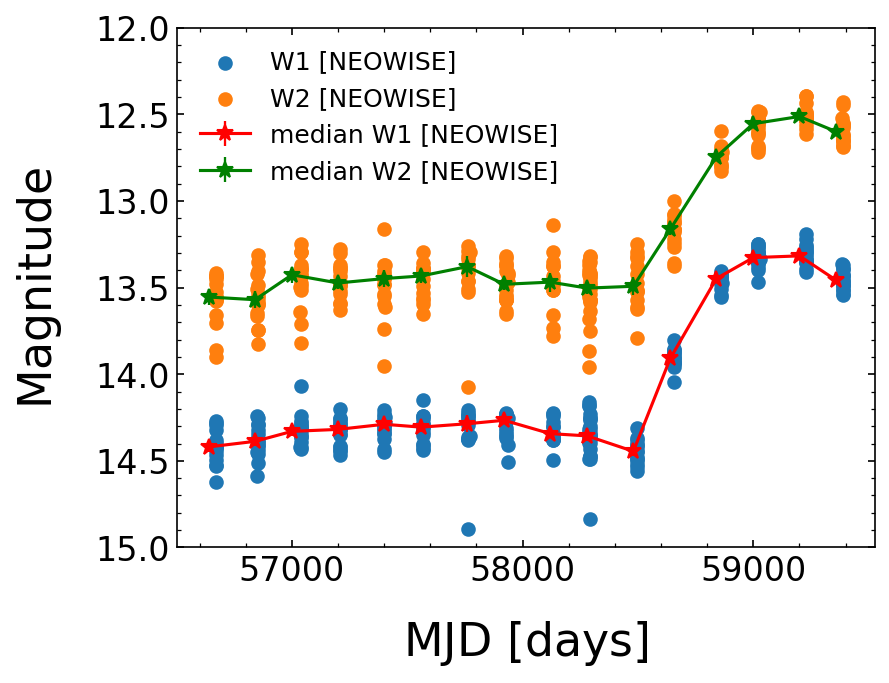

In [389]:
fig = plt.figure(figsize = (6,4.5), dpi = 150)
plt.xlabel(r'${\rm MJD\ [days]}$', fontsize=22, labelpad=15)
plt.ylabel(r'${\rm Magnitude}$', fontsize=22, labelpad=15)

plt.scatter(WISE_t,W1_mag, label = 'W1 [NEOWISE]')
plt.scatter(WISE_t,W2_mag, label = 'W2 [NEOWISE]')
plt.errorbar(W1_mjd_bin, W1_mag_bin, yerr=W1_mag_err_bin,c='r', label = 'median W1 [NEOWISE]',
             marker = '*', ms=8, elinewidth=1.1, alpha = 1,)
plt.errorbar(W2_mjd_bin, W2_mag_bin, yerr=W2_mag_err_bin,c='g', label = 'median W2 [NEOWISE]', 
            marker = '*', ms=8, elinewidth=1.1, alpha = 1,)

plt.ylim(15.0, 12.0)

plt.legend(loc = 'upper left', fontsize = 12, markerscale = 1, ncol = 1, frameon=False )
plt.savefig('image/median_MIR_lc.pdf',dpi=600,bbox_inches='tight')

### lc example

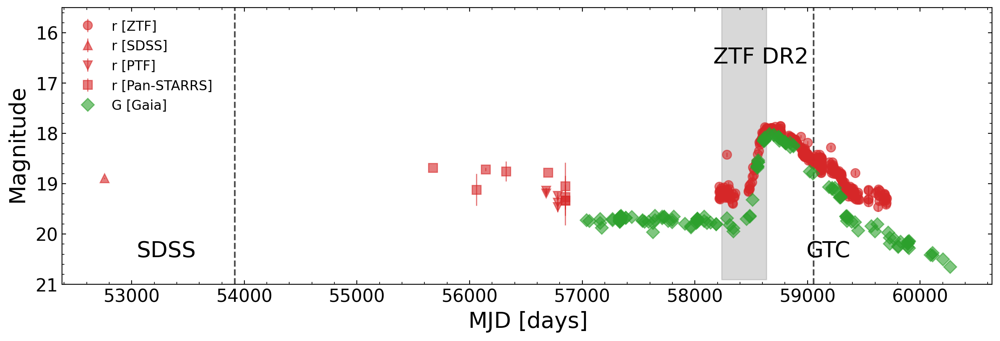

In [238]:
fig = plt.figure(figsize = (15,4.5), dpi = 200)

ax  = plt.subplot(111)
ax.set_xlabel(r"${\rm MJD\ [days]}$", fontsize=20)
ax.set_ylabel(r"${\rm Magnitude }$", fontsize=20)
# ax.set_title('SDSS J1427+2930', fontsize=20)


ax.set_ylim(21, 15.5)
# ax.set_xlim(-1000,1000)

plot_triband = 0
plot_triins  = 1

t_start = 58522+120
ax.errorbar(t_1427, mag_1427, yerr = mag_1427_err, 
            linestyle = 'None', color = "C3", marker = 'o', 
            ms=8, elinewidth=1.1, alpha = 0.6, label = "r [ZTF]" )

# ax.scatter(t_1427, mag_1427, color = 'C3', s = 6, alpha = 0.5)

# ax.axvline(x = 0, color = 'k',linestyle="--", alpha=line_alpha,lw=line_lw)
# ax.text(0.235 ,0.92,r'${\rm peak}$',transform=ax.transAxes,fontdict=fontdict_emline,rotation=0, va='center')

ax.axvline(x = 59055, color = 'k',linestyle="--", alpha=0.7)
ax.text(0.80,0.1,'GTC',transform=ax.transAxes,fontdict={'size': '20', 'color': 'black'})
ax.axvline(x = 53917, color = 'k',linestyle="--", alpha=0.7)
ax.text(0.08,0.1,'SDSS',transform=ax.transAxes,fontdict={'size': '20', 'color': 'black'})

y_t = np.arange(15,21,0.1)
ax.fill_betweenx(y_t,np.full_like(y_t,58239),np.full_like(y_t,58635),color='grey', alpha=0.3)
ax.text(0.70,0.80,'ZTF DR2',transform=ax.transAxes,fontdict={'size': '20', 'color': 'black'})

if plot_triband:
    ax.errorbar(WISE_t_new, W1_mag_new+2.683, yerr = W1_mag_err_new, 
                linestyle = 'None', color = "C3", marker = 'o', ms=3, 
                elinewidth=1.1, alpha = 0.6, label = "W1 [WISE]")
    # ax.scatter(WISE_t_new, W1_mag_new+2.683, color = 'C3', s = 4, alpha = 0.5, label = "W1 [WISE]" )
    
    ax.errorbar(WISE_t_new, W2_mag_new+3.319, yerr = W2_mag_err_new, 
                linestyle = 'None', color = "C4", marker = 'o', ms=3, 
                elinewidth=1.1, alpha = 0.6, label = "W2 [WISE]")
    # ax.scatter(WISE_t_new, W2_mag_new+3.319, color = 'C4', s = 4, alpha = 0.5, label = "W2 [WISE]" )
    
    ax.errorbar(t_1427_g, gmag_1427, yerr = gmag_1427_err, 
                linestyle = 'None', color = "C1", marker = 'o', ms=3, 
                elinewidth=1.1, alpha = 0.6, label = "g [ZTF]")
    # ax.scatter(t_1427_g, gmag_1427, color = 'C1', s = 4, alpha = 0.5, label = "g [ZTF]" )

    ax.errorbar(t_1427_i, imag_1427, yerr = imag_1427_err, 
                linestyle = 'None', color = "C2", marker = 'o', 
                ms=3, elinewidth=1.1, alpha = 0.6, label = "i [ZTF]")
    # ax.scatter(t_1427_i, imag_1427, color = 'C2', s = 4, alpha = 0.5, label = "i [ZTF]" )

if plot_triins:
    
    ax.errorbar(SDSS_t, SDSS_r_mag, yerr = SDSS_r_mag_err, 
                linestyle = 'None', color = "C3", marker = '^', 
                ms=8, elinewidth=1.1, alpha = 0.6, label = "r [SDSS]")
    # ax.scatter(SDSS_t, SDSS_r_mag, color = 'C0', s = 6, alpha = 0.5, label = "r [SDSS]" )
    
    ax.errorbar(ptf_t, ptf_r_mag, yerr = ptf_r_mag_err, 
                linestyle = 'None', color = "C3", marker = 'v', 
                ms=8, elinewidth=1.1, alpha = 0.6, label = "r [PTF]")
    # ax.scatter(ptf_t, ptf_r_mag, color = 'C0', s = 6, alpha = 0.5, label = "r [PTF]" )

    # ax.errorbar(pan_t, pan_r_mag, yerr = pan_r_mag_err, 
    #             linestyle = 'None', color = "C3", marker = 's', 
    #             ms=8, elinewidth=1.1, alpha = 0.6, label = "r [Pan-STARRS]")
    ax.errorbar(pan_t, pan_mag, yerr=pan_magerr,
                linestyle = 'None', color = "C3", marker = 's', 
                ms=8, elinewidth=1.1, alpha = 0.6, label = "r [Pan-STARRS]")
    # ax.scatter(pan_t, pan_r_mag, color = 'C0', s = 6, alpha = 0.5, label = "r [Pan-Starrs]" )
    
    ax.errorbar(gaia_t, gaia_g_mag,  
                linestyle = 'None', color = "C2", marker = 'D', 
                ms=8, elinewidth=1.1, alpha = 0.6, label = "G [Gaia]")
    # ax.scatter(gaia_t, gaia_g_mag, color = 'C6', s = 6, alpha = 0.5, label = "g [Gaia]" )


plt.legend(loc = 'upper left', fontsize = 12, markerscale = 1, ncol = 1, frameon=False )

# plt.savefig('image/lc_sample_select.pdf',dpi=600,bbox_inches='tight')

In [376]:
def mag2L(mag, mag_err, dist, ins, band, logscale = True):
    
    if ins == 'ZTF':
        if band == 'g':
            lambda_eff = 4722.74 * 10**(-10)
            F_nu0 = 3963.97
        if band == 'r':
            lambda_eff = 6339.61 * 10**(-10)
            F_nu0 = 3042.00
        if band == 'i':
            lambda_eff = 7886.13 * 10**(-10)
            F_nu0 = 2426.09
    if ins == 'WISE':
        if band == 'W1':
            lambda_eff = 33526.00 * 10**(-10)
            F_nu0 = 309.540
        if band == 'W2':
            lambda_eff = 46028.00 * 10**(-10)
            F_nu0 = 171.787
            
    c = 299792458  
    nu = c/lambda_eff 
    
    mag = np.array(mag)
    mag_err = np.array(mag_err)
        
    F_nu = F_nu0 * 10**(-mag/2.5)
    F_nu_err = np.sqrt((np.log(10)*F_nu*mag_err)**2)
    
    nuL = F_nu * 10**(-23) * nu * 4*np.pi*dist**2
    nuL_err = F_nu_err * 10**(-23) * nu * 4*np.pi*dist**2
    
    log_nuL = np.log10(nuL)
    log_nuL_err = np.sqrt((nuL_err/nuL)**2)/np.log(10)

    
    if logscale:
        return np.array(log_nuL), np.array(log_nuL_err)
    else:
        return np.array(nu_L), np.array(nu_L_err)

In [377]:
dist = cosmo.luminosity_distance(0.37362438).cgs.value

g_nuL, g_nuL_err = mag2L(gmag_1427, gmag_1427_err, dist=dist, ins='ZTF', band='g', logscale = True)
r_nuL, r_nuL_err = mag2L(mag_1427, mag_1427_err, dist=dist, ins='ZTF', band='r', logscale = True)
i_nuL, i_nuL_err = mag2L(imag_1427, imag_1427_err, dist=dist, ins='ZTF', band='i', logscale = True)
W1_nuL, W1_nuL_err = mag2L(W1_mag_new, W1_mag_err_new, dist=dist, ins='WISE', band='W1', logscale = True)
W2_nuL, W2_nuL_err = mag2L(W2_mag_new, W2_mag_err_new, dist=dist, ins='WISE', band='W2', logscale = True)

In [264]:
def rebin_lc(mjd, mag, magerr, binsize,):
    t_list_bin = np.unique(mjd//binsize)
    t_norm = np.array(mjd//binsize)
    
    mag_new = []
    mag_err_new = []
    
    for idx in np.arange(len(t_list_bin)):
        ii = t_list_bin[idx]
        mag_list = []
        magerr_list = []
        for j in np.arange(len(t_norm)):
            jj = t_norm[j]
            if jj == ii:
                mag_list.append(mag[j])
                magerr_list.append(magerr[j])

        mag_new.append(np.nanmedian(np.array(mag_list)))
        magerr_list = np.array(magerr_list)

        num_photometry = len(mag_list)
        if num_photometry > 1:
            mag_err = np.sqrt((np.nansum(magerr_list**2) + 
                               num_photometry*np.nanstd(np.array(mag_list))**2)/(num_photometry*(num_photometry-1)))
            mag_err_new.append(mag_err)
        else:
            mag_err_new.append(np.nan)

        # mag_err_new.append(np.nanstd(np.array(mag_list)))

    mag_new = np.array(mag_new)
    mag_err_new = np.array(mag_err_new)
    mjd_new = t_list_bin*binsize
    
    return mjd_new, mag_new, mag_err_new

In [379]:
r_mjd_bin, r_mag_bin, r_mag_err_bin = rebin_lc(t_1427, mag_1427,10)
g_mjd_bin, g_mag_bin, g_mag_err_bin = rebin_lc(t_1427_g, gmag_1427,10)

t_gr = np.intersect1d(g_mjd_bin,r_mjd_bin)

t_gr_mask = (t_gr>58400)&(t_gr<60000)

g_gr_mask = np.isin(g_mjd_bin, t_gr[t_gr_mask], invert=False)
r_gr_mask = np.isin(r_mjd_bin, t_gr[t_gr_mask], invert=False)
g_mag_gr = g_mag_bin[g_gr_mask]
g_mag_err_gr = g_mag_err_bin[g_gr_mask]
r_mag_gr = r_mag_bin[r_gr_mask]
r_mag_err_gr = r_mag_err_bin[r_gr_mask]

g_r = g_mag_gr-r_mag_gr
g_r_err = np.sqrt(g_mag_err_gr**2 + r_mag_err_gr**2)

### lc & fit

Text(0.5, 0, '$\\rm MJD\\ [days] $')

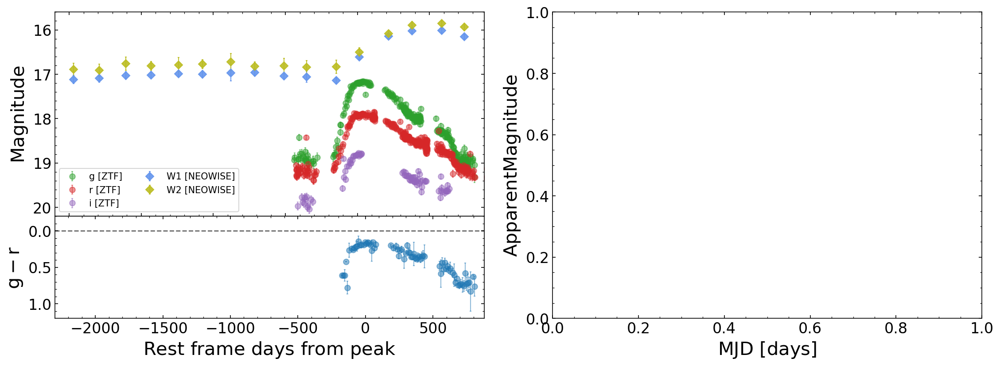

In [421]:
fig = plt.figure(figsize= (18,6),dpi=150)
grid = plt.GridSpec(6, 6, hspace=0, wspace=0.7)

plt.rcParams["xtick.direction"] = "in"
plt.rcParams["ytick.direction"] = "in"
plt.rcParams["xtick.top"] = True
plt.rcParams["ytick.right"] = True
plt.rcParams["xtick.minor.visible"] = True
plt.rcParams["ytick.minor.visible"] = True
plt.rcParams["xtick.labelsize"] = 16
plt.rcParams["ytick.labelsize"] = 16


ax_lc = plt.subplot(grid[0:4, :3])
ax_lc.set_xticklabels([])
ax_color = plt.subplot(grid[4:6, :3])
ax_fit = plt.subplot(grid[:6, 3:6])

# ax_lc = plt.axes([.143, .45, .785, .50])
# ax_lc.set_xticklabels([])
# ax_color = plt.axes([.143,.30,.785,.15])

##########
alpha_Opt = 0.5
alpha_IR = 0.9
ms = 3
elw = 1 
csize = 1

Lumino = 0 
magnit = 1 
##########


ax_color.set_ylabel(r"$\rm g-r $", fontsize=20)
ax_color.set_xlabel(r"$\rm Rest\ frame\ days\ from\ peak $", fontsize=20)


ax_lc.set_xlim(-2100,880)
ax_color.set_ylim(1.2,-0.2)
ax_color.set_xlim(-2300,880)

##  luminosity 

if Lumino:
    ax_lc.errorbar(t_1427_g-t_start, g_nuL, yerr = g_nuL_err, 
                   linestyle = 'None', color = "g", marker = 'o',
                   ms=ms, elinewidth=elw, alpha = alpha_Opt, capsize=csize, label = "g [ZTF]" )

    ax_lc.errorbar(t_1427-t_start, r_nuL, yerr = r_nuL_err, 
                linestyle = 'None', color = "r", marker = 'o', 
                   ms=ms, elinewidth=elw, alpha = alpha_Opt, capsize=csize,label = "r [ZTF]")

    ax_lc.errorbar(t_1427_i-t_start, i_nuL, yerr = i_nuL_err, 
                linestyle = 'None', color = "C8", marker = 'o', 
                   ms=ms, elinewidth=elw, alpha = alpha_Opt, capsize=csize, label = "i [ZTF]")

    ax_lc.errorbar(WISE_t_new-t_start, W1_nuL, yerr = W1_nuL_err, 
                linestyle = 'None', color = "cornflowerblue", marker = 'D', 
                   ms=ms, elinewidth=elw, alpha = alpha_IR,  capsize=csize, label = "W1 [NEOWISE]" )

    ax_lc.errorbar(WISE_t_new-t_start, W2_nuL, yerr = W2_nuL_err, 
                linestyle = 'None', color = "purple", marker = 'D', 
                   ms=ms, elinewidth=elw, alpha = alpha_IR,  capsize=csize, label = "W2 [NEOWISE]")
    
    ax_lc.set_ylabel(r"${{\rm Log}\ \nu L_{\nu}\ [\rm ergs^{-1}] }$", fontsize=15)
    ax_lc.set_ylim(43.9,45)

##  magnitude 

if magnit:
    
    ax_lc.errorbar(t_1427_g-t_start, gmag_1427 - 0.9, yerr = gmag_1427_err, 
                   linestyle = 'None', color = "C2", marker = 'o',
                   ms=6, elinewidth=elw, alpha = alpha_Opt, capsize=csize, label = "g [ZTF]" )

    ax_lc.errorbar(t_1427-t_start, mag_1427, yerr = mag_1427_err, 
                linestyle = 'None', color = "C3", marker = 'o', 
                   ms=6, elinewidth=elw, alpha = alpha_Opt, capsize=csize,label = "r [ZTF]")

    ax_lc.errorbar(t_1427_i-t_start, imag_1427 + 0.9, yerr = imag_1427_err, 
                linestyle = 'None', color = "C4", marker = 'o', 
                   ms=6, elinewidth=elw, alpha = alpha_Opt, capsize=csize, label = "i [ZTF]")

    ax_lc.errorbar(WISE_t_new-t_start, W1_mag_new +2.699, yerr = W1_mag_err_new, 
                linestyle = 'None', color = "cornflowerblue", marker = 'D', 
                   ms=6, elinewidth=elw, alpha = alpha_IR,  capsize=csize, label = "W1 [NEOWISE]" )

    ax_lc.errorbar(WISE_t_new-t_start, W2_mag_new + 3.339, yerr = W2_mag_err_new, 
                linestyle = 'None', color = "C8", marker = 'D', 
                   ms=6, elinewidth=elw, alpha = alpha_IR,  capsize=csize, label = "W2 [NEOWISE]")
    
    ax_lc.set_ylim(20.2, 15.6)
    ax_lc.set_ylabel(r"${\rm Magnitude}$", fontsize=20)
    
ax_lc.legend(fontsize = 10.0,markerscale = 1, ncol=2, loc='lower left')
    

## color panel
ax_color.errorbar(t_gr[t_gr_mask]-t_start,g_r,yerr = g_r_err, 
                  linestyle="None", color = "C0", marker = 'o', 
                  ms=6, elinewidth=elw, alpha = 0.5, capsize=csize)

ax_color.axhline(y = 0, color = color,linestyle="--", alpha=line_alpha,lw=line_lw)


## MOSFIT panel 

ax_fit.set_ylabel(r"$\rm Apparent Magnitude $", fontsize=20)
ax_fit.set_xlabel(r"$\rm MJD\ [days] $", fontsize=20)

# plt.savefig('image/J1427_lc_color.pdf',dpi=600,bbox_inches='tight')

### spectra


In [417]:
sdss_data=fits.open("data/SDSS/SDSS_J142746.39+293038.2.fits")

z=sdss_data[2].data['z'][0]                # Redshift
lam=10**sdss_data[1].data['loglam']        # OBS wavelength [A]
rest_lam = lam/(1+z)
flux=sdss_data[1].data['flux']             # OBS flux [erg/s/cm^2/A]
err=1./np.sqrt(sdss_data[1].data['ivar'])  # 1 sigma error


gtc_C_data = fits.open("data/GTC-OSIRIS/Sci_spec/combined_grism/SDSS_J1427GTC_OSIRIS.fits")
wave_c = gtc_C_data[1].data["wave"]
rest_wave = wave_c/(1+z)
fc_gtc_data = ascii.read("data/GTC-OSIRIS/Sci_spec/Flux_cal_spec/J1427_FluxCal.dat")
flux_c = fc_gtc_data["fluxCal"]
var_c = gtc_C_data[1].data["var"]

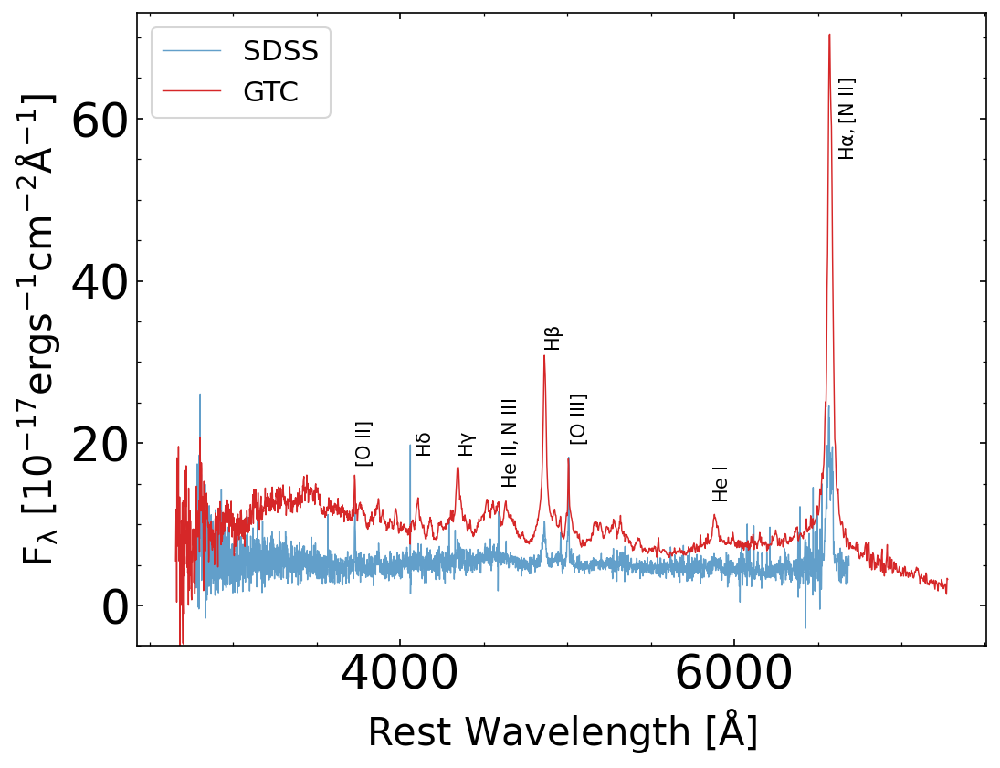

In [183]:
fig = plt.figure(figsize = (8,6), dpi = 150)
ax  = plt.subplot(111)
ax.set_xlabel(r"${\rm  Rest\ Wavelength\ [\AA]}$", fontsize=20)
ax.set_ylabel(r"${\rm  F_{\lambda}\ [10^{-17}ergs^{-1}cm^{-2}\AA^{-1}] }$", fontsize=20)
ax.set_ylim(-5,73)
ax.plot(rest_lam,flux,c='C0',lw=0.7, alpha = 0.7, label="SDSS")
ax.plot(rest_wave,flux_c,c='C3',lw=0.7, alpha =1, label="GTC")

# ax.text(0.12,0.25,'SDSS J1420 GTC',transform=ax.transAxes,fontdict={'size': '12', 'color': 'C3'})
# ax.text(0.12,0.50,'SDSS J1420 SDSS',transform=ax.transAxes,fontdict={'size': '12', 'color': 'C0'})


fontdict_emline=dict(fontsize=10, color='k',family='DejaVu Sans',weight='light')
color = 'k'
line_alpha = 0.9
line_lw = 1.2

ax.text(6620, 60,r'${\rm H\alpha, [N\ II]}$',fontdict=fontdict_emline,rotation=90, va='center')
ax.text(4855, 33,r'${\rm H\beta}$',fontdict=fontdict_emline,rotation=90, va='center')
ax.text(4340, 20,r'${\rm H\gamma}$',fontdict=fontdict_emline,rotation=90, va='center')
ax.text(4100, 20,r'${\rm H\delta}$',fontdict=fontdict_emline,rotation=90, va='center')
ax.text(3726, 20, r'${\rm [O\ II]}$',fontdict=fontdict_emline,rotation=90, va='center')
ax.text(5008, 23, r'${\rm [O\ III]}$',fontdict=fontdict_emline,rotation=90, va='center')
ax.text(4600, 20, r'${\rm He\ II, N\ III}$',fontdict=fontdict_emline,rotation=90, va='center')
ax.text(5875, 15, r'${\rm He\ I}$',fontdict=fontdict_emline,rotation=90, va='center')

ax.legend(loc='upper left', fontsize=15)

# ax.set_xlim(4000, 5000)

# plt.savefig('image/J1427_spec_FC.pdf',dpi=600,bbox_inches='tight')

In [468]:
z=sdss_data[2].data['z'][0]
dist = cosmo.luminosity_distance(z).value    ## Mpc
dist

2031.5031481290189

In [471]:
objname = 'J1427'
sdss_Ha_flux = 338.1347478867627e-17   ## erg/s/cm^2
gtc_ha_flux  = 918.9194333880549e-17   ## erg/s/cm^2

mpc_cm = 3.0856776 * 10**(24)
sdss_Lha = sdss_Ha_flux * (4*np.pi*(dist*mpc_cm)**2) 
gtc_Lha = gtc_ha_flux * (4*np.pi*(dist*mpc_cm)**2) 
SFR_sdss = 4.9*10**(-42)*sdss_Lha
SFR_gtc = 4.9*10**(-42)*gtc_Lha

SFR_sdss, SFR_gtc

(8.18147940889356, 22.234095932708573)

## SDSS J1420

In [53]:
## ZTF 
ztfr = fits.open("data/lc/ZTF/SDSS_J1420_ZTFr.fits")
MJD_ZTF = ztfr[1].data["MJD"]
mag_ZTF = ztfr[1].data["mag"]
mag_err_ZTF = ztfr[1].data["magerr"]

ztfg = fits.open("data/lc/ZTF/SDSS_J1420_ZTFg.fits")
gMJD_ZTF = ztfg[1].data["MJD"]
gmag_ZTF = ztfg[1].data["mag"]
gmag_err_ZTF = ztfg[1].data["magerr"]

## Pan-starrs
panr = pd.read_csv("data/lc/Pan_starrs/SDSS_J1420_Panstarrs.csv")
pan_t = np.array(panr["epochMean"])
pan_r_mag = np.array(panr["rMeanApMag"])
pan_r_mag_err = np.array(panr["rMeanApMagErr"])

## PTF
ptfr = pd.read_csv("data/lc/PTF/SDSS_J1420_PTF_r.csv")
ptft = np.array(ptfr["obsmjd"])
ptfmag = np.array(ptfr["mag_autocorr"])
ptfmagerr = np.array(ptfr["magerr_auto"])

## SDSS
# SDSS J1617 
# SDSS_t = np.array([53504])
# SDSS_r_mag = np.array([18.59])
# SDSS_r_mag_err = np.array([0.01])

# SDSS J1420
SDSS_t = np.array([52758])
SDSS_r_mag = np.array([18.89])
SDSS_r_mag_err = np.array([0.01])

In [322]:
## ZTF g-r color

r_mjd_bin, r_mag_bin, r_mag_err_bin = rebin_lc(MJD_ZTF, mag_ZTF, mag_err_ZTF, 10)
g_mjd_bin, g_mag_bin, g_mag_err_bin = rebin_lc(gMJD_ZTF, gmag_ZTF, gmag_err_ZTF, 10)

t_gr = np.intersect1d(g_mjd_bin,r_mjd_bin)

t_gr_mask = (t_gr>58000)&(t_gr<60000)

g_gr_mask = np.isin(g_mjd_bin, t_gr[t_gr_mask], invert=False)
r_gr_mask = np.isin(r_mjd_bin, t_gr[t_gr_mask], invert=False)
g_mag_gr = g_mag_bin[g_gr_mask]
g_mag_err_gr = g_mag_err_bin[g_gr_mask]
r_mag_gr = r_mag_bin[r_gr_mask]
r_mag_err_gr = r_mag_err_bin[r_gr_mask]

g_r = g_mag_gr-r_mag_gr
g_r_err = np.sqrt(g_mag_err_gr**2 + r_mag_err_gr**2)

In [312]:
# neoWISE 
data_WISE = pd.read_csv("data/lc/neoWISE/neoWISESDSSJ1420.csv")
WISE_t = np.array(data_WISE["mjd"])
W1_mag = np.array(data_WISE["w1mpro"])
W1_mag_err = np.array(data_WISE["w1sigmpro"])
W2_mag = np.array(data_WISE["w2mpro"])
W2_mag_err = np.array(data_WISE["w2sigmpro"])

W1_mjd_bin, W1_mag_bin, W1_mag_err_bin = rebin_lc(WISE_t, W1_mag, W1_mag_err, 40)
W2_mjd_bin, W2_mag_bin, W2_mag_err_bin = rebin_lc(WISE_t, W2_mag, W2_mag_err, 40)

<ErrorbarContainer object of 3 artists>

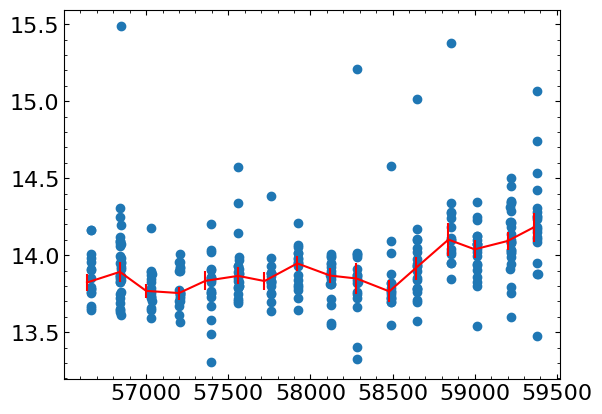

In [314]:
# plt.scatter(WISE_t,W1_mag)
# plt.errorbar(WISE_t_new,W1_mag_new, yerr = W1_mag_err_new, color = 'r')

plt.scatter(WISE_t,W2_mag)
plt.errorbar(W2_mjd_bin,W2_mag_bin, yerr = W2_mag_err_bin, color = 'r')

# plt.ylim(14.3, 15.3)

In [344]:
sdss_data=fits.open("data/SDSS/SDSS_J142048.66+375755.4.fits")

z=sdss_data[2].data['z'][0]                # Redshift
lam=10**sdss_data[1].data['loglam']        # OBS wavelength [A]
rest_lam = lam/(1+z)
flux=sdss_data[1].data['flux']             # OBS flux [erg/s/cm^2/A]
err=1./np.sqrt(sdss_data[1].data['ivar'])  # 1 sigma error


gtc_C_data = fits.open("data/GTC-OSIRIS/Sci_spec/combined_grism/SDSS_J1420GTC_OSIRIS.fits")
wave_c = gtc_C_data[1].data["wave"]
rest_wave = wave_c/(1+z)
gtc_fc_data = ascii.read("data/GTC-OSIRIS/Sci_spec/Flux_cal_spec/J1420_FluxCal.dat")
flux_c = gtc_fc_data["fluxCal"]
var_c = gtc_C_data[1].data["var"]

In [46]:
plt.rcParams["xtick.direction"] = "in"
plt.rcParams["ytick.direction"] = "in"
plt.rcParams["xtick.top"] = True
plt.rcParams["ytick.right"] = True
plt.rcParams["xtick.minor.visible"] = True
plt.rcParams["ytick.minor.visible"] = True
plt.rcParams["xtick.labelsize"] = 16
plt.rcParams["ytick.labelsize"] = 16

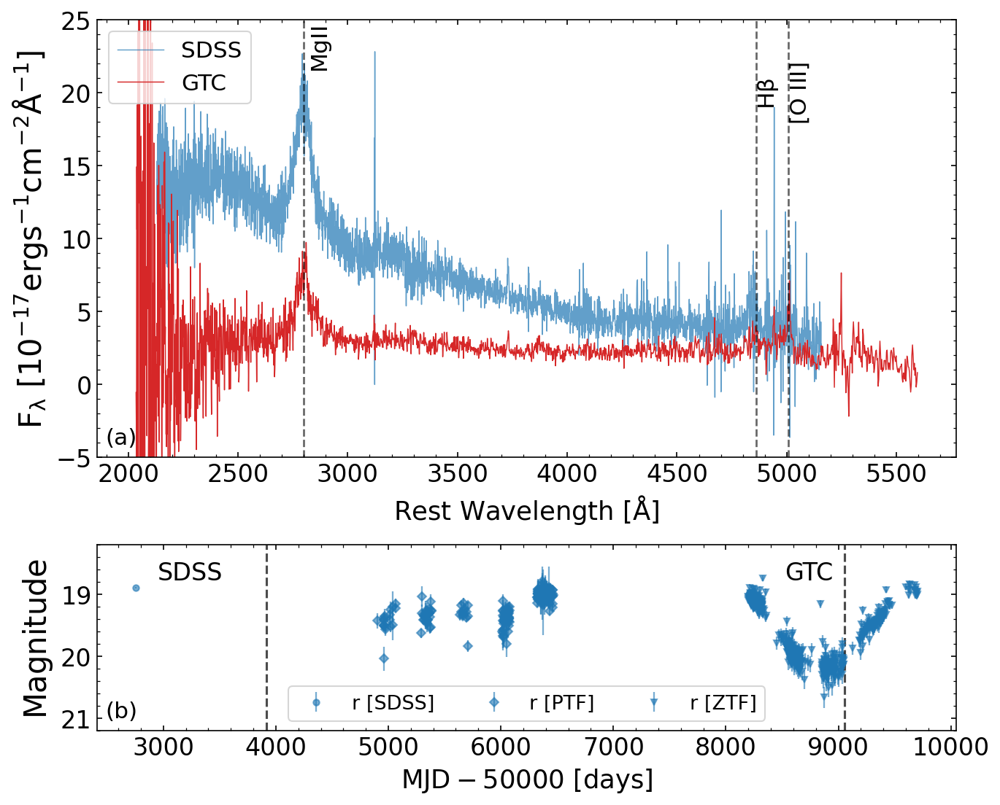

In [47]:
fig = plt.figure(figsize= (10,10),dpi=150)

ax_spec = plt.axes([.143, .45, .785, .40])
ax_lc = plt.axes([.143,.20,.785,.17])

ax_spec.set_xlabel(r"${\rm  Rest\ Wavelength\ [\AA]}$", fontsize=17)
ax_spec.set_ylabel(r"${\rm  F_{\lambda}\ [10^{-17}ergs^{-1}cm^{-2}\AA^{-1}] }$", fontsize=20)
ax_spec.set_ylim(-5,25)

ax_spec.plot(rest_lam,flux,c='C0',lw=0.7, alpha = 0.7, label = 'SDSS')
ax_spec.plot(rest_wave,flux_c,c='C3',lw=0.7, label='GTC')
# ax_spec.text(0.1,0.10,'SDSS J1420 [GTC]',transform=ax_spec.transAxes,fontdict={'size': '16', 'color': 'black'})
# ax_spec.text(0.1,0.38,'SDSS J1420 [SDSS]',transform=ax_spec.transAxes,fontdict={'size': '16', 'color': 'black'})
ax_spec.text(0.01,0.03,'(a)',transform=ax_spec.transAxes,fontdict={'size': '15', 'color': 'black'})

fontdict_emline=dict(fontsize=15, color='k',family='DejaVu Sans',weight='light')
color = 'k'
line_alpha = 0.6
line_lw = 1.3

ax_spec.axvline(x = 4861, color = color,linestyle="--", alpha=line_alpha,lw=line_lw)
ax_spec.text(4861,20,r'${\rm H\beta}$',fontdict=fontdict_emline,rotation=90, va='center')

ax_spec.axvline(x = 5007, color = color,linestyle="--", alpha=line_alpha,lw=line_lw)
ax_spec.text(5008 ,20,r'${\rm [O\ III]}$',fontdict=fontdict_emline,rotation=90, va='center')

ax_spec.axvline(x = 2800, color = color,linestyle="--", alpha=line_alpha,lw=line_lw)
ax_spec.text(2830,23,r'${\rm Mg II}$',fontdict=fontdict_emline,rotation=90, va='center')

ax_spec.legend(loc = "upper left", fontsize=15)

ax_lc.set_xlabel(r"${\rm  MJD-50000\ [days]}$", fontsize=17)
ax_lc.set_ylabel(r"${\rm Magnitude }$", fontsize=20)
ax_lc.set_ylim(21.2, 18.2)

ax_lc.errorbar(SDSS_t-50000, SDSS_r_mag, yerr = SDSS_r_mag_err, linestyle = 'None', color = "C0", marker = 'o',
                    ms=4, elinewidth=1.1, alpha = 0.6, label = "r [SDSS]")
# ax_lc.scatter(SDSS_t, SDSS_r_mag, color = 'C0', s = 4, alpha = 0.5, label = "r [SDSS]")

ax_lc.errorbar(ptft-50000, ptfmag, yerr = ptfmagerr, linestyle = 'None', color = "C0", marker = 'D',
                    ms=4, elinewidth=1.1, alpha = 0.6, label = "r [PTF]")
# ax_lc.scatter(ptft, ptfmag, color = 'C2', s = 4, alpha = 0.5, label = "r [PTF]")

ax_lc.errorbar(MJD_ZTF-50000, mag_ZTF, yerr = mag_err_ZTF, linestyle = 'None', color = "C0", marker = 'v',
                    ms=4, elinewidth=1.1, alpha = 0.6, label = "r [ZTF]")
# ax_lc.scatter(MJD_ZTF, mag_ZTF, color = 'C3', s = 4, alpha = 0.5)

ax_lc.axvline(x = 59055-50000, color = 'k',linestyle="--", alpha=0.7)
ax_lc.text(0.80,0.81,'GTC',transform=ax_lc.transAxes,fontdict={'size': '16', 'color': 'k'})
ax_lc.axvline(x = 53917-50000, color = 'k',linestyle="--", alpha=0.7)
ax_lc.text(0.07,0.81,'SDSS',transform=ax_lc.transAxes,fontdict={'size': '16', 'color': 'k'})

ax_lc.text(0.01,0.07,'(b)',transform=ax_lc.transAxes,fontdict={'size': '15', 'color': 'black'})


ax_lc.legend(ncol=3, loc = "best", fontsize=13)

# plt.savefig("image/J1420_result.pdf", dpi=600, bbox_inches="tight")


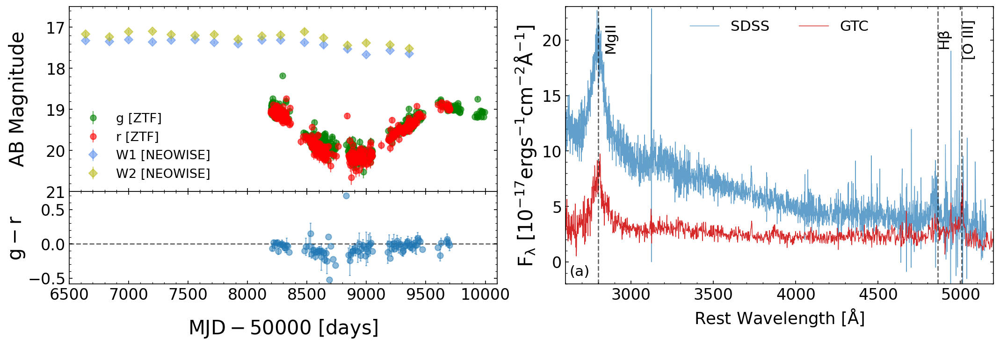

In [361]:
fig = plt.figure(figsize= (17,6),dpi=150)
grid = plt.GridSpec(7, 6, hspace=0, wspace=0.7)

plt.rcParams["xtick.direction"] = "in"
plt.rcParams["ytick.direction"] = "in"
plt.rcParams["xtick.top"] = True
plt.rcParams["ytick.right"] = True
plt.rcParams["xtick.minor.visible"] = True
plt.rcParams["ytick.minor.visible"] = True
plt.rcParams["xtick.labelsize"] = 16
plt.rcParams["ytick.labelsize"] = 16


ax_lc = plt.subplot(grid[0:4, :3])
ax_lc.set_xticklabels([])
ax_color = plt.subplot(grid[4:6, :3])
ax_spec = plt.subplot(grid[:6, 3:7])


######### light curve 
ax_lc.set_ylim(21, 16.5)

## ZTF
ax_lc.errorbar(gMJD_ZTF-50000, gmag_ZTF, yerr = gmag_err_ZTF, linestyle = 'None', 
               color = "g", marker = 'o', ms=6, elinewidth=1.1, alpha = 0.6, label = "g [ZTF]")

ax_lc.errorbar(MJD_ZTF-50000, mag_ZTF, yerr = mag_err_ZTF, linestyle = 'None', 
               color = "r", marker = 'o', ms=6, elinewidth=1.1, alpha = 0.6, label = "r [ZTF]")

## neoWISE
ax_lc.errorbar(W1_mjd_bin-50000, W1_mag_bin+2.699, yerr = W1_mag_err_bin, linestyle = 'None', 
               color = "cornflowerblue", marker = 'D', ms=6, elinewidth=1.1, alpha = 0.6, label = "W1 [NEOWISE]")

ax_lc.errorbar(W2_mjd_bin-50000, W2_mag_bin+3.339, yerr = W2_mag_err_bin, linestyle = 'None', 
               color = "C8", marker = 'D', ms=6, elinewidth=1.1, alpha = 0.6, label = "W2 [NEOWISE]")

ax_color.set_xlabel(r'${\rm MJD-50000\ [days]}$', fontsize=20, labelpad=15)
ax_color.set_ylabel(r'${\rm g-r}$', fontsize=20, labelpad=1)
ax_lc.set_ylabel(r'${\rm AB\ Magnitude}$', fontsize=20, labelpad=17)

## color panel
ax_color.errorbar(t_gr[t_gr_mask]-50000,g_r,yerr = g_r_err, 
                  linestyle="None", color = "C0", marker = 'o', 
                  ms=6, elinewidth=1.1, alpha = 0.5, capsize=1)

ax_color.axhline(y = 0, color = color,linestyle="--", alpha=line_alpha,lw=line_lw)
ax_color.set_xlim(6500, 10100)
ax_lc.set_xlim(6500, 10100)

ax_lc.legend(ncol=1, loc = "best", fontsize=13, frameon=False )


## spectra 
ax_spec.set_xlabel(r"${\rm  Rest\ Wavelength\ [\AA]}$", fontsize=17)
ax_spec.set_ylabel(r"${\rm  F_{\lambda}\ [10^{-17}ergs^{-1}cm^{-2}\AA^{-1}] }$", fontsize=20)
ax_spec.set_ylim(-5,25)

ax_spec.plot(rest_lam,flux,c='C0',lw=0.7, alpha = 0.7, label = 'SDSS')
ax_spec.plot(rest_wave,flux_c,c='C3',lw=0.7, label='GTC')
# ax_spec.text(0.1,0.10,'SDSS J1420 [GTC]',transform=ax_spec.transAxes,fontdict={'size': '16', 'color': 'black'})
# ax_spec.text(0.1,0.38,'SDSS J1420 [SDSS]',transform=ax_spec.transAxes,fontdict={'size': '16', 'color': 'black'})
ax_spec.text(0.01,0.03,'(a)',transform=ax_spec.transAxes,fontdict={'size': '15', 'color': 'black'})

fontdict_emline=dict(fontsize=15, color='k',family='DejaVu Sans',weight='light')
color = 'k'
line_alpha = 0.6
line_lw = 1.3

ax_spec.axvline(x = 4861, color = color,linestyle="--", alpha=line_alpha,lw=line_lw)
ax_spec.text(4861,20,r'${\rm H\beta}$',fontdict=fontdict_emline,rotation=90, va='center')

ax_spec.axvline(x = 5007, color = color,linestyle="--", alpha=line_alpha,lw=line_lw)
ax_spec.text(5008 ,20,r'${\rm [O\ III]}$',fontdict=fontdict_emline,rotation=90, va='center')

ax_spec.axvline(x = 2800, color = color,linestyle="--", alpha=line_alpha,lw=line_lw)
ax_spec.text(2840,20,r'${\rm Mg II}$',fontdict=fontdict_emline,rotation=90, va='center')

ax_spec.legend(ncol=2, loc = "upper center", fontsize=15, frameon=False)
ax_spec.set_xlim(2600, 5200)
ax_spec.set_ylim(-2, 23)

plt.savefig("image/J1420_lc_spec.pdf", dpi=600, bbox_inches="tight")

## Tables

In [49]:
### obs
sdss_spec_list = glob.glob('data/SDSS/*.fits')

In [50]:
sdss_names = []
RA = []
DEC = []
obs_mjd = []
redshift = []
exp_time = []
# seeing = []
airmass = []

for i in range(len(sdss_spec_list)):
    hdu_sdss = fits.open(sdss_spec_list[i])
    hdu_gtc  = fits.open(glob.glob('data/GTC-OSIRIS/Sci_spec/combined_grism/*' + sdss_spec_list[i][15:20] + '*.fits')[0])
    
    sdss_names.append('SDSS '+ sdss_spec_list[i][15:34])
    RA.append(np.around(hdu_gtc[0].header['RA'], 3))
    DEC.append(np.around(hdu_gtc[0].header['DEC'], 3))
    redshift.append(np.around(hdu_sdss[2].data['z'][0], 4))
    
    obs_mjd.append(hdu_gtc[0].header['MJD'])
    exp_time.append(hdu_gtc[0].header['EXPTIME'])
    # seeing.append(hdu_gtc[0].header['EXPTIME'])
    airmass.append(np.around(hdu_gtc[0].header['AIRMASS'], 2))
    

In [51]:
obs_table = Table()
obs_table['SDSS_name'] = sdss_names
obs_table['RA'] = RA
obs_table['DEC'] = DEC
obs_table['z'] = redshift
obs_table['MJD'] = obs_mjd
obs_table['exptime'] = exp_time
obs_table['airmass'] = airmass
obs_table

SDSS_name,RA,DEC,z,MJD,exptime,airmass
str24,float64,float64,float32,float64,float64,float64
SDSS J161700.81+124332.2,244.309,12.753,0.3534,58997.2022735774,90.0,1.72
SDSS J141802.79+414935.2,214.588,41.805,1.0419,59046.8989837826,90.0,1.1
SDSS J142746.39+293038.2,217.011,29.524,0.3736,59054.9738324405,90.0,1.57
SDSS J144050.76+520445.9,220.31,52.075,0.3187,59044.0172810969,50.0,1.54
SDSS J142048.66+375755.4,215.279,37.963,0.7866,59044.9425863272,100.0,1.2
SDSS J145206.89+360226.0,223.102,36.053,2.9712,59044.0338898928,120.0,1.66
SDSS J160353.04+264515.9,241.039,26.773,1.334,58990.2063353642,90.0,1.48
SDSS J141119.44+413802.3,212.906,41.609,1.1298,59046.8857777645,120.0,1.08
SDSS J160747.76+304418.6,242.02,30.754,0.4651,58990.2188585123,90.0,1.54


In [52]:
np.array(np.around(obs_table['MJD'],1))

array([58997.2, 59046.9, 59055. , 59044. , 59044.9, 59044. , 58990.2,
       59046.9, 58990.2, 58995.2, 58995.2])

In [57]:

## properties
prop_list = ['name', 'BH_mass', 'L_bol[sdss]', 'Eddington_ratio[sdss]', 'EW[sdss]', 'L_conti[sdss]', 'time_lag', 
                                'L_bol[GTC]' , 'Eddington_ratio[gtc]' , 'EW[gtc]' , 'L_conti[gtc]' , ]
df_gtc  = ascii.read("data/GTC_datatable.csv")
df_sdss = ascii.read('data/SDSS_datatable.csv')